# Sistema de apoyo para la detección de tumores cerebrales en resonancia magnética
**Proyecto final · Diplomado en IA Generativa, BI y Ciencia de Datos · Universidad Anáhuac Querétaro**
Autor: Raúl Pichardo Manzano

> Resultado de apoyo. No sustituye el diagnóstico de un médico especialista.

**Problema.** El doctor sube una resonancia y el sistema indica si **se detecta o no un posible tumor**. El error más costoso es el **falso negativo** (decir “sin tumor” cuando sí hay), por eso la métrica principal es la **sensibilidad**, con meta de 0.98.

**Este notebook reúne todo el proyecto en un solo lugar, en el orden del flujo de trabajo:**

```
DATOS
  └─▶ PROCESAMIENTO
        ├─ 2.1 Limpieza
        ├─ 2.2 Exploración (estadística, intervalos de confianza, pruebas de hipótesis)
        ├─ 2.3 Preparación del dataset (entrenamiento / prueba, validación cruzada CV = 5)
        └─ 2.4 Creación de rasgos (MobileNetV2 y rasgos básicos; PCA y K-Means)
  └─▶ MODELOS (mismos pliegues y mismas métricas)
        ├─ 3.1 Modelos clásicos: solución simple, regresión logística, Random Forest, SVM
        │       validación cruzada → umbral → métricas en prueba
        └─ 3.2 Red neuronal en Keras
                validación cruzada → entrenamiento con detención temprana → métricas en prueba
                → comparación contra el mejor modelo clásico
  └─▶ 4. IA generativa: asistente de consultas SQL
  └─▶ 5. Conclusiones
```

**Notas de método**
- La preparación del dataset va **antes** de la creación de rasgos para que el PCA y el K-Means se ajusten solo con el entrenamiento.
- Los rasgos son fijos (1,280 de MobileNetV2 y 18 básicos) y los hiperparámetros también: **no se hizo búsqueda de hiperparámetros ni selección de rasgos**; queda como trabajo futuro.
- El conjunto de prueba se usa **una sola vez**, al final de cada modelo.
- Los mismos pasos están separados en `01_eda` … `05_ia_generativa`; este notebook ejecuta exactamente el mismo código.

**Cómo correrlo:** kernel *Python (tumores)* → *Run All*. Tarda de 10 a 20 minutos en CPU. Requiere el dataset en `datos/Training` y `datos/Testing` (ver `README.md`).

# 1. Datos
Fuente: *Brain Tumor MRI Dataset* (Masoud Nickparvar, Kaggle, CC BY 4.0). Se leen las 7,200 imágenes, sus tamaños y sus huellas digitales.

In [1]:
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import hashlib
import warnings
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from scipy import stats
from sklearn.model_selection import train_test_split

from app.backend.ml import config
from app.backend.ml.duplicados import UMBRAL_CORRELACION, agrupar, maxima_correlacion, miniatura, tabla_pares
from app.backend.ml.entrenar import apartar_validacion, pliegues_estratificados
from app.backend.ml.metricas import wilson
from app.backend.ml.preprocesar import leer_imagen, preparar
from app.backend.ml.rasgos import rasgos_basicos
from app.backend.ml.red import pesos_clase

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
INICIO = time.time()
print("Raíz del proyecto:", config.RAIZ)
print("Versiones:", config.versiones())

Raíz del proyecto: C:\proyectos\tumores-cerebrales
Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


#### Inventario
Se listan todos los archivos de las 8 carpetas. La división original Training/Testing del dataset **no se usa** para evaluar: más abajo se juntan todas las imágenes, se quitan las repetidas y se vuelve a dividir.

In [2]:
filas, otros_archivos = [], []
for carpeta in ["Training", "Testing"]:
    for clase in config.CLASES:
        d = config.DATOS / carpeta / clase
        if not d.is_dir():
            raise FileNotFoundError(f"No existe la carpeta {d}")
        for f in sorted(d.iterdir()):
            if f.suffix.lower() in config.EXTENSIONES:
                filas.append({"ruta": f.relative_to(config.RAIZ).as_posix(), "carpeta_origen": carpeta,
                              "clase": clase, "extension": f.suffix.lower(), "bytes": f.stat().st_size})
            else:
                otros_archivos.append(str(f))
df = pd.DataFrame(filas)
df["es_tumor"] = (df.clase != "notumor").astype(int)
print(f"Imágenes encontradas: {len(df):,} · archivos que no son imagen: {len(otros_archivos)}")
inventario = pd.crosstab(df.carpeta_origen, df.clase, margins=True, margins_name="total")
display(inventario)
print("Extensiones:", df.extension.value_counts().to_dict())

Imágenes encontradas: 7,200 · archivos que no son imagen: 0


clase,glioma,meningioma,notumor,pituitary,total
carpeta_origen,,,,,
Testing,400,400,400,400,1600
Training,1400,1400,1400,1400,5600
total,1800,1800,1800,1800,7200


Extensiones: {'.jpg': 7200}


#### Lectura, tamaños y huellas
Cada imagen se lee **una sola vez** con `np.fromfile` + `cv2.imdecode` (funciona con acentos en Windows) y se calcula:
- ancho y alto originales;
- **SHA-256 de los pixeles decodificados** (detecta copias exactas aunque el archivo tenga otro nombre);
- **hash perceptual**: la imagen se reduce a 16 × 16 en grises y cada pixel se compara con el promedio (256 bits). Detecta copias con cambios mínimos de compresión o tamaño;
- las **mismas dos huellas sobre la imagen ya preparada** (recorte del cerebro y 160 × 160). Sirven para atrapar copias que solo difieren en el marco negro o en el tamaño del archivo: los pixeles originales son distintos, pero lo que ve el modelo es idéntico;
- una **miniatura de 64 × 64 en grises** de la imagen original y otra de la preparada, para buscar copias en espejo, giradas o recomprimidas (sección 3);
- brillo y contraste de la imagen ya preparada, que es lo que verá el modelo.

In [3]:
def hash_perceptual(img, n=16, codigo=cv2.COLOR_BGR2GRAY):
    """Hash promedio de 16x16 (como el script de referencia): 256 bits en hexadecimal."""
    gris = cv2.cvtColor(img, codigo)
    g = np.asarray(Image.fromarray(gris).resize((n, n), Image.Resampling.BILINEAR), dtype=np.float32)
    bits = (g > g.mean()).flatten()
    return np.packbits(bits).tobytes().hex()


def analizar(ruta_rel):
    try:
        img = leer_imagen(config.RAIZ / ruta_rel)
    except ValueError:
        return {"legible": False}
    sha = hashlib.sha256(str(img.shape).encode() + img.tobytes()).hexdigest()
    lista = preparar(img)
    basicos = rasgos_basicos(lista)
    en_grises = bool((img[..., 0] == img[..., 1]).all() and (img[..., 1] == img[..., 2]).all())
    return {"legible": True, "alto": img.shape[0], "ancho": img.shape[1], "en_grises": en_grises,
            "sha256": sha, "hash_perceptual": hash_perceptual(img),
            "sha256_preparada": hashlib.sha256(lista.tobytes()).hexdigest(),
            "hash_perceptual_preparada": hash_perceptual(lista, codigo=cv2.COLOR_RGB2GRAY),
            "mini_original": miniatura(img), "mini_preparada": miniatura(lista),
            "brillo": float(basicos[0]), "contraste": float(basicos[1])}


t0 = time.time()
with ThreadPoolExecutor(max_workers=12) as ex:
    info = list(ex.map(analizar, df.ruta))
df = pd.concat([df, pd.DataFrame(info)], axis=1)
print(f"Imágenes analizadas en {time.time() - t0:.0f} s")

Imágenes analizadas en 38 s


# 2. Procesamiento
## 2.1 Limpieza
Se quitan imágenes ilegibles, copias exactas, casi idénticas, en espejo o giradas, los aumentos que ya traía el dataset y las imágenes con etiquetas contradictorias.

##### Limpieza
Se quitan los archivos que no se pueden leer y las imágenes demasiado pequeñas (menos de 32 pixeles por lado).

Ilegibles quitadas: 0 · demasiado pequeñas quitadas: 0 · quedan 7,200
Imágenes guardadas en grises (3 canales iguales): 7,071 de 7,200
Tamaños distintos: 447 · el más común: (np.int64(512), np.int64(512)) con 5,014 imágenes


,ancho,alto,bytes
count,7200.0,7200.0,7200.0
mean,453.3,456.9,23312.4
std,130.0,124.4,16301.0
min,150.0,167.0,3681.0
25%,442.0,449.0,16113.5
50%,512.0,512.0,21705.5
75%,512.0,512.0,27392.2
max,1375.0,1446.0,306492.0


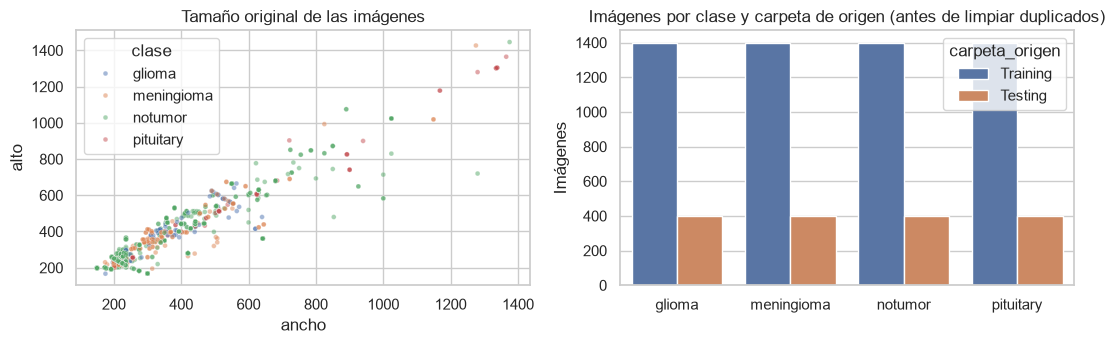

In [4]:
n_ilegibles = int((~df.legible).sum())
df = df[df.legible].drop(columns="legible").reset_index(drop=True)
muy_chicas = (df.ancho < 32) | (df.alto < 32)
n_chicas = int(muy_chicas.sum())
df = df[~muy_chicas].reset_index(drop=True)
df[["alto", "ancho"]] = df[["alto", "ancho"]].astype(int)
MINI_O = np.stack(df.pop("mini_original").to_list())    # miniaturas de la imagen original
MINI_P = np.stack(df.pop("mini_preparada").to_list())   # miniaturas de la imagen preparada (recortada)
print(f"Ilegibles quitadas: {n_ilegibles} · demasiado pequeñas quitadas: {n_chicas} · quedan {len(df):,}")
print(f"Imágenes guardadas en grises (3 canales iguales): {int(df.en_grises.sum()):,} de {len(df):,}")

tamanos = df.groupby(["ancho", "alto"]).size().sort_values(ascending=False)
print(f"Tamaños distintos: {len(tamanos)} · el más común: {tamanos.index[0]} con {tamanos.iloc[0]:,} imágenes")
display(df[["ancho", "alto", "bytes"]].describe().round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
sns.scatterplot(data=df, x="ancho", y="alto", hue="clase", hue_order=config.CLASES, s=12, alpha=0.5, ax=axs[0])
axs[0].set_title("Tamaño original de las imágenes")
sns.countplot(data=df, x="clase", hue="carpeta_origen", order=config.CLASES, ax=axs[1])
axs[1].set_title("Imágenes por clase y carpeta de origen (antes de limpiar duplicados)")
axs[1].set_xlabel(""); axs[1].set_ylabel("Imágenes")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_01_inventario.png", dpi=130); plt.show()

#### Limpieza: aumentos, copias y etiquetas contradictorias
Si la misma toma está en entrenamiento y en prueba, el modelo "ya vio el examen" y las métricas salen infladas. Este dataset trae mucha repetición, de varios tipos. Se trata en tres pasos:

**Paso 1 · Aumentos sintéticos del dataset.** Los archivos con `aug` en el nombre son imágenes giradas o con zoom que alguien generó a partir de otras del mismo dataset. No son tomas reales: se quitan **todos**.

**Paso 2 · Copias.** Dos imágenes son la misma toma si la **correlación entre sus miniaturas de 64 × 64 es mayor de 0.98**, comparando una con la otra tal cual y en las otras 7 orientaciones (espejo horizontal, espejo vertical, giro de 180°, giros de 90° y 270° y las dos transpuestas), sobre la imagen original y sobre la preparada. Esto incluye las copias exactas (mismo SHA-256), las recomprimidas en JPEG y las volteadas, que las huellas no detectan.
- **Se elimina por pares, sin encadenar:** se recorren las imágenes en orden y una imagen se elimina **solo si** tiene correlación mayor de 0.98 con una imagen que **se conserva**. (Encadenar "A se parece a B, B a C, C a D…" llegaba a juntar decenas de tomas distintas y a borrar imágenes legítimas.)
- **El hash perceptual de 16 × 16 ya no elimina por sí solo:** resume la silueta y juntaba imágenes distintas. Ahora solo sirve, más abajo, para mantener del mismo lado a las imágenes que lo comparten.
- **Etiquetas contradictorias:** si dos imágenes con correlación mayor de 0.98 tienen **clases distintas** (tumor contra sin tumor, o dos tipos de tumor), se descartan **las dos**, porque no se sabe cuál etiqueta es la correcta.

**Paso 3 · Grupos de similitud (sección 3.2).** Las imágenes que quedan y se parecen mucho (correlación mayor de 0.95) **no se borran**: se agrupan, y la división se hace por grupos.

In [5]:
HUELLAS = ["sha256", "hash_perceptual", "sha256_preparada", "hash_perceptual_preparada"]
UMBRAL_GRUPO = 0.95       # similitud para formar grupos (sección 3.2)
MARGEN = 1e-4             # margen numérico: los pares se buscan un poco por debajo del umbral
t0 = time.time()
tabla = pd.concat([pd.DataFrame(tabla_pares(MINI_O, UMBRAL_GRUPO - MARGEN)).assign(miniatura="original"),
                   pd.DataFrame(tabla_pares(MINI_P, UMBRAL_GRUPO - MARGEN)).assign(miniatura="preparada")], ignore_index=True)
# un renglón por par: la mayor correlación entre la miniatura original y la preparada
tabla = tabla.sort_values("correlacion", ascending=False, kind="stable").drop_duplicates(["i", "j"]).reset_index(drop=True)
print(f"Comparación de miniaturas (todas contra todas, 8 orientaciones) en {time.time() - t0:.0f} s · "
      f"pares con correlación > {UMBRAL_GRUPO}: {len(tabla):,} · > {UMBRAL_CORRELACION}: {int((tabla.correlacion > UMBRAL_CORRELACION).sum()):,}")

# Paso 1: aumentos sintéticos
df["es_aug"] = df.ruta.map(lambda r: "aug" in Path(r).name.lower())
print(f"Archivos 'aug' (aumentos del dataset): {int(df.es_aug.sum())} ·", df[df.es_aug].groupby(["carpeta_origen", "clase"]).size().to_dict())


# Paso 2: copias por pares (sin encadenar) y etiquetas contradictorias
es_aug = df.es_aug.to_numpy()
clases, shas = df.clase.to_numpy(), df.sha256.to_numpy()
fuertes = tabla[(tabla.correlacion > UMBRAL_CORRELACION) & ~es_aug[tabla.i] & ~es_aug[tabla.j]].reset_index(drop=True)
choque = fuertes[clases[fuertes.i] != clases[fuertes.j]]
contradictoria = np.zeros(len(df), dtype=bool)
contradictoria[choque.i] = True
contradictoria[choque.j] = True

def correlacion_directa(i, j, mini):
    a, b = mini[i].ravel() - mini[i].mean(), mini[j].ravel() - mini[j].mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6))


vecinos = {}
for i, j, v, c in zip(fuertes.i, fuertes.j, fuertes.variante, fuertes.correlacion):
    vecinos.setdefault(int(i), []).append((int(j), v, float(c)))
    vecinos.setdefault(int(j), []).append((int(i), v, float(c)))

CAUSA_AUG, CAUSA_CONTRA = "aumento_del_dataset", "etiqueta_contradictoria"
CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO = "copia_exacta", "casi_identica", "espejo_o_giro"
accion = np.array(["conservada"] * len(df), dtype=object)
causa = np.array([""] * len(df), dtype=object)
referencia = np.full(len(df), -1)
ref_variante = np.array([""] * len(df), dtype=object)
ref_correlacion = np.full(len(df), np.nan)
for i in range(len(df)):                      # orden: Training antes que Testing, por clase y nombre
    if es_aug[i]:
        accion[i], causa[i] = "quitada", CAUSA_AUG
        continue
    if contradictoria[i]:
        accion[i], causa[i] = "quitada", CAUSA_CONTRA
        otros = [(j, v, c) for j, v, c in vecinos.get(i, []) if clases[j] != clases[i]]
        referencia[i], ref_variante[i], ref_correlacion[i] = max(otros, key=lambda x: x[2])
        continue
    conservadas = [(j, v, c) for j, v, c in vecinos.get(i, []) if j < i and accion[j] == "conservada"]
    if conservadas:
        exactas = [x for x in conservadas if shas[x[0]] == shas[i]]
        j, v, c = exactas[0] if exactas else max(conservadas, key=lambda x: x[2])
        accion[i] = "quitada"
        # "casi idéntica" si ya se parecen sin voltear; "espejo o giro" solo si hace falta voltear para verlo
        sin_voltear = max(correlacion_directa(i, j, MINI_O), correlacion_directa(i, j, MINI_P)) > UMBRAL_CORRELACION
        causa[i] = CAUSA_EXACTA if exactas else (CAUSA_CASI if (v == "directa" or sin_voltear) else CAUSA_ESPEJO)
        referencia[i], ref_variante[i], ref_correlacion[i] = j, v, c
df["accion"], df["causa"] = accion, causa

por_causa = pd.crosstab(df.causa.replace("", "SE CONSERVA"), df.clase, margins=True, margins_name="total")
por_causa = por_causa.reindex([CAUSA_AUG, CAUSA_CONTRA, CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO, "SE CONSERVA", "total"]).fillna(0).astype(int)
print("Imágenes por causa de eliminación y clase:")
display(por_causa)
quitadas = df[df.accion == "quitada"]
cruzan = (quitadas.causa.isin([CAUSA_EXACTA, CAUSA_CASI, CAUSA_ESPEJO]).to_numpy()
          & (quitadas.carpeta_origen.to_numpy() != df.carpeta_origen.to_numpy()[np.maximum(referencia[quitadas.index], 0)]))
print(f"Copias eliminadas cuya pareja conservada estaba en la otra carpeta (Training / Testing): {int(cruzan.sum())}")
print(f"Pares con etiquetas contradictorias: {len(choque)} ({int(contradictoria.sum())} imágenes). Clases que chocan:",
      pd.Series([" + ".join(sorted((a, b))) for a, b in zip(clases[choque.i], clases[choque.j])]).value_counts().to_dict())

# Comparación con el método anterior (encadenamiento transitivo + hash perceptual por sí solo), sobre las mismas imágenes sin 'aug'
sin_aug = np.flatnonzero(~es_aug)
pos = -np.ones(len(df), dtype=int); pos[sin_aug] = np.arange(len(sin_aug))
enlaces = [(pos[i], pos[j]) for i, j in zip(fuertes.i, fuertes.j)]
sub = df.iloc[sin_aug].reset_index(drop=True)
for columna in HUELLAS:
    for _, indices in sub.groupby(columna).indices.items():
        enlaces += [(int(indices[0]), int(k)) for k in indices[1:]]
sub["grupo_encadenado"] = agrupar(len(sub), enlaces)
sub = sub[sub.groupby("grupo_encadenado").clase.transform("nunique") == 1].drop_duplicates("grupo_encadenado")
recuperadas = pd.DataFrame({"metodo_anterior_encadenado": sub.clase.value_counts(),
                            "metodo_actual_por_pares": df[df.accion == "conservada"].clase.value_counts()}).reindex(config.CLASES).fillna(0).astype(int)
recuperadas["recuperadas"] = recuperadas.metodo_actual_por_pares - recuperadas.metodo_anterior_encadenado
recuperadas.loc["total"] = recuperadas.sum()
print("Imágenes conservadas por clase: método anterior contra método actual (ambos sin los archivos 'aug'):")
display(recuperadas)

df["ruta_referencia"] = [df.ruta[j] if j >= 0 else "" for j in referencia]
df["clase_referencia"] = [df.clase[j] if j >= 0 else "" for j in referencia]
df["variante"], df["correlacion"] = ref_variante, ref_correlacion
columnas_dup = ["ruta", "carpeta_origen", "clase", "es_tumor", "sha256", "hash_perceptual", "accion", "causa",
                "ruta_referencia", "clase_referencia", "variante", "correlacion"]
df[df.accion == "quitada"][columnas_dup].to_csv(config.DUPLICADOS, index=False, encoding="utf-8")
print("Guardado:", config.DUPLICADOS, f"({int((df.accion == 'quitada').sum()):,} imágenes eliminadas, con su causa y la imagen conservada a la que se parecen)")
tabla.assign(ruta_a=df.ruta.to_numpy()[tabla.i], ruta_b=df.ruta.to_numpy()[tabla.j], clase_a=clases[tabla.i], clase_b=clases[tabla.j])[
    ["ruta_a", "clase_a", "ruta_b", "clase_b", "variante", "miniatura", "correlacion"]].to_csv(config.DATOS / "pares_casi_duplicados.csv", index=False, encoding="utf-8")
print("Guardado:", config.DATOS / "pares_casi_duplicados.csv", f"({len(tabla):,} pares con correlación > {UMBRAL_GRUPO})")

Comparación de miniaturas (todas contra todas, 8 orientaciones) en 168 s · pares con correlación > 0.95: 24,591 · > 0.98: 18,025


Archivos 'aug' (aumentos del dataset): 203 · {('Testing', 'meningioma'): 103, ('Training', 'meningioma'): 100}


Imágenes por causa de eliminación y clase:


clase,glioma,meningioma,notumor,pituitary,total
causa,,,,,
aumento_del_dataset,0,203,0,0,203
etiqueta_contradictoria,5,16,0,13,34
copia_exacta,12,89,86,28,215
casi_identica,5,35,361,8,409
espejo_o_giro,321,638,986,794,2739
SE CONSERVA,1457,819,367,957,3600
total,1800,1800,1800,1800,7200


Copias eliminadas cuya pareja conservada estaba en la otra carpeta (Training / Testing): 1078
Pares con etiquetas contradictorias: 27 (34 imágenes). Clases que chocan: {'glioma + meningioma': 14, 'meningioma + pituitary': 13}


Imágenes conservadas por clase: método anterior contra método actual (ambos sin los archivos 'aug'):


,metodo_anterior_encadenado,metodo_actual_por_pares,recuperadas
clase,,,
glioma,1419,1457,38
meningioma,807,819,12
notumor,340,367,27
pituitary,944,957,13
total,3510,3600,90


Guardado: C:\proyectos\tumores-cerebrales\datos\duplicados.csv (3,600 imágenes eliminadas, con su causa y la imagen conservada a la que se parecen)


Guardado: C:\proyectos\tumores-cerebrales\datos\pares_casi_duplicados.csv (24,591 pares con correlación > 0.95)


##### Ejemplos de pares en espejo
Cada fila es un par que las huellas **no** detectan: a la izquierda una imagen, en medio su pareja tal como está en el dataset y a la derecha la pareja volteada, que coincide con la primera. Se eligen pares cuya correlación sin voltear es baja (imágenes poco simétricas), para que el espejo se note a simple vista.

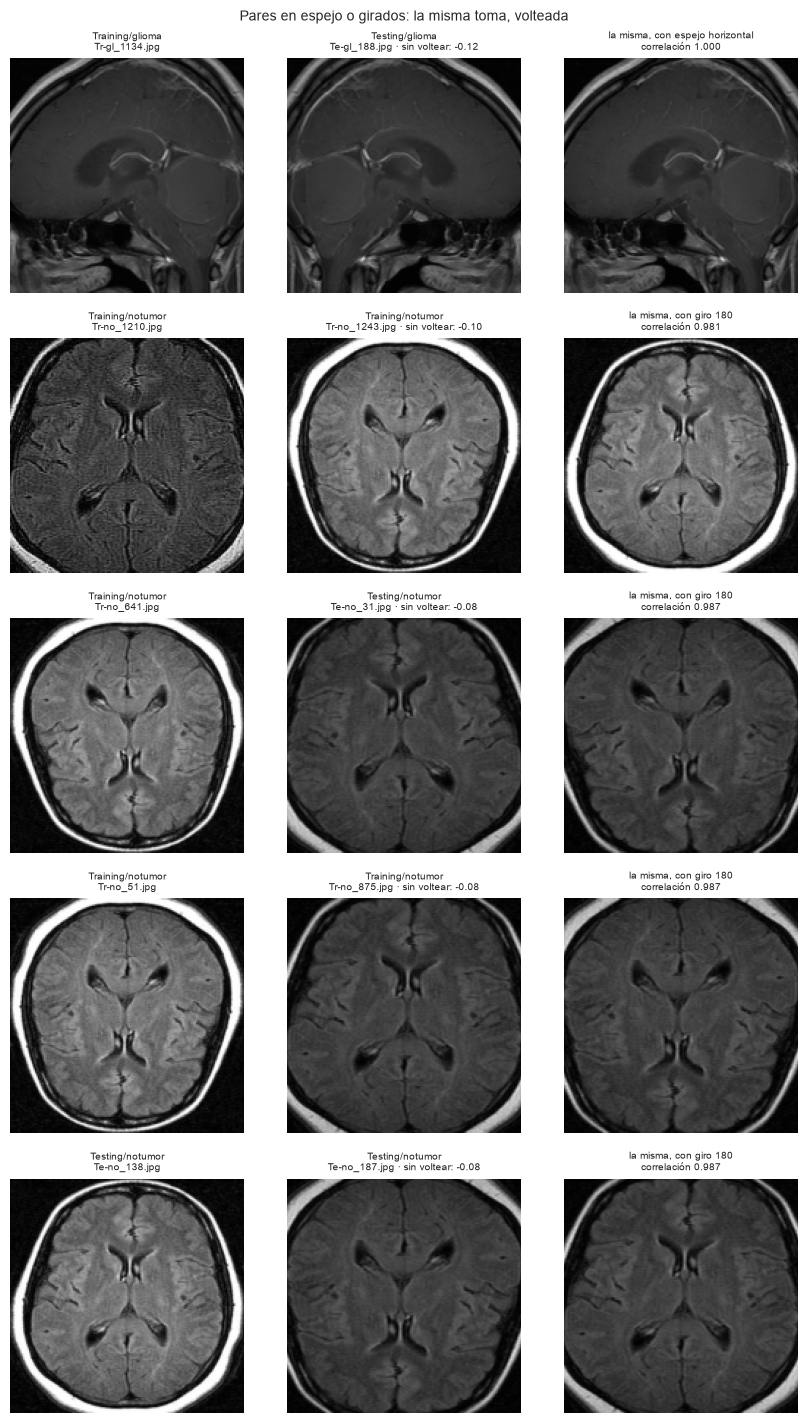

In [6]:
VOLTEAR = {"directa": lambda a: a, "espejo_horizontal": lambda a: a[:, ::-1], "espejo_vertical": lambda a: a[::-1], "giro_180": lambda a: a[::-1, ::-1],
           "giro_90": lambda a: np.rot90(a, 1), "giro_270": lambda a: np.rot90(a, 3),
           "transpuesta": lambda a: a.transpose(1, 0, 2), "antitranspuesta": lambda a: a[::-1, ::-1].transpose(1, 0, 2)}
candidatos = fuertes[fuertes.variante != "directa"].copy()
if len(candidatos):
    candidatos["directa"] = [correlacion_directa(i, j, MINI_P) for i, j in zip(candidatos.i, candidatos.j)]
    muestra = candidatos.sort_values("directa").drop_duplicates("i").drop_duplicates("j")
    muestra = muestra[~muestra.j.isin(muestra.i)].head(5)
    fig, axs = plt.subplots(len(muestra), 3, figsize=(8.5, 2.9 * len(muestra)), squeeze=False)
    for fila, r in zip(axs, muestra.itertuples()):
        a = preparar(leer_imagen(config.RAIZ / df.ruta[r.i])); b = preparar(leer_imagen(config.RAIZ / df.ruta[r.j]))
        fila[0].imshow(a); fila[0].set_title(f"{df.carpeta_origen[r.i]}/{df.clase[r.i]}\n{Path(df.ruta[r.i]).name}", fontsize=7)
        fila[1].imshow(b); fila[1].set_title(f"{df.carpeta_origen[r.j]}/{df.clase[r.j]}\n{Path(df.ruta[r.j]).name} · sin voltear: {r.directa:.2f}", fontsize=7)
        fila[2].imshow(VOLTEAR[r.variante](b)); fila[2].set_title(f"la misma, con {r.variante.replace('_', ' ')}\ncorrelación {r.correlacion:.3f}", fontsize=7)
        for ax in fila:
            ax.axis("off")
    fig.suptitle("Pares en espejo o girados: la misma toma, volteada", fontsize=10)
    plt.tight_layout(); plt.savefig(FIGURAS / "eda_03b_pares_espejo.png", dpi=120); plt.show()
else:
    print("No se encontraron pares en espejo o girados.")

##### Datos limpios
A partir de aquí solo se trabaja con las imágenes conservadas.

In [7]:
POS_LIMPIO = np.flatnonzero((df.accion == "conservada").to_numpy())   # posición de cada imagen limpia en las miniaturas
limpio = df[df.accion == "conservada"].reset_index(drop=True)
assert limpio.sha256.is_unique and limpio.sha256_preparada.is_unique
antes_despues = pd.DataFrame({"antes": df.clase.value_counts(), "quitadas": df[df.accion != "conservada"].clase.value_counts(),
                              "después": limpio.clase.value_counts()}).reindex(config.CLASES).fillna(0).astype(int)
antes_despues.loc["total"] = antes_despues.sum()
display(antes_despues)

n = len(limpio)
n_sin = int((limpio.es_tumor == 0).sum())
print(f"Sin tumor: {n_sin:,} de {n:,} ({n_sin / n:.1%}) · tumor: {n - n_sin:,} ({1 - n_sin / n:.1%})")

,antes,quitadas,después
clase,,,
glioma,1800,343,1457
meningioma,1800,981,819
notumor,1800,1433,367
pituitary,1800,843,957
total,7200,3600,3600


Sin tumor: 367 de 3,600 (10.2%) · tumor: 3,233 (89.8%)


##### Grupos de similitud
Entre las imágenes que quedan todavía hay parecidos fuertes que **no** se borran, porque son imágenes distintas o no se puede asegurar que sean copias:
- la **misma toma con otro contraste o brillo** (a veces además volteada), con correlación entre 0.95 y 0.98;
- **cortes vecinos** del mismo estudio, casi idénticos;
- imágenes que comparten el **hash perceptual** (misma silueta).

Para que ninguna de esas parejas quede repartida entre entrenamiento y prueba, se forman **grupos de similitud**: componentes conexas de los pares con correlación mayor de 0.95 (8 orientaciones, miniatura original o preparada) o con el mismo hash perceptual. Aquí el encadenamiento sí conviene: no borra nada, solo decide qué imágenes viajan juntas. La división y los pliegues se hacen **por grupo** (sección 7).

In [8]:
nueva = -np.ones(len(df), dtype=int); nueva[POS_LIMPIO] = np.arange(len(limpio))
ambos = (nueva[tabla.i] >= 0) & (nueva[tabla.j] >= 0)
enlaces = list(zip(nueva[tabla.i[ambos]], nueva[tabla.j[ambos]]))
n_por_correlacion = len(enlaces)
for columna in ["hash_perceptual", "hash_perceptual_preparada"]:
    for _, indices in limpio.groupby(columna).indices.items():
        enlaces += [(int(indices[0]), int(k)) for k in indices[1:]]
limpio["grupo_similitud"] = agrupar(len(limpio), enlaces)
tam = limpio.groupby("grupo_similitud").ruta.transform("size")
por_grupo = limpio.groupby("grupo_similitud")
resumen_grupos = pd.Series({
    "imágenes limpias": len(limpio),
    "pares con correlación > 0.95 entre ellas": n_por_correlacion,
    "grupos de similitud": int(limpio.grupo_similitud.nunique()),
    "grupos de una sola imagen": int((por_grupo.size() == 1).sum()),
    "grupos de 2 o más imágenes": int((por_grupo.size() > 1).sum()),
    "imágenes en grupos de 2 o más": int((tam > 1).sum()),
    "grupo más grande (imágenes)": int(por_grupo.size().max()),
    "grupos con más de una clase": int((por_grupo.clase.nunique() > 1).sum()),
    "grupos que mezclan tumor y sin tumor": int((por_grupo.es_tumor.nunique() > 1).sum()),
}, name="cantidad")
display(resumen_grupos.to_frame())
print("Tamaño de los grupos (imágenes por grupo → número de grupos):", por_grupo.size().value_counts().sort_index().to_dict())
print("Clase del grupo más grande:", limpio[limpio.grupo_similitud == por_grupo.size().idxmax()].clase.value_counts().to_dict())

,cantidad
imágenes limpias,3600
pares con correlación > 0.95 entre ellas,340
grupos de similitud,3258
grupos de una sola imagen,3080
grupos de 2 o más imágenes,178
imágenes en grupos de 2 o más,520
grupo más grande (imágenes),10
grupos con más de una clase,4
grupos que mezclan tumor y sin tumor,0


Tamaño de los grupos (imágenes por grupo → número de grupos): {1: 3080, 2: 95, 3: 37, 4: 25, 5: 14, 6: 3, 7: 3, 10: 1}
Clase del grupo más grande: {'glioma': 10}


## 2.2 Exploración
Estadística descriptiva, intervalos de confianza y pruebas de hipótesis sobre los datos limpios.

#### Estadística descriptiva: brillo y contraste
- **Brillo:** media de los grises de la imagen preparada, de 0 (negro) a 1 (blanco).
- **Contraste:** desviación estándar de esos grises.

Se calculan sobre la imagen ya recortada y a 160 × 160, igual que la verá el modelo.

brillo                                         contraste          \
            count    mean  median     std     min     max     count    mean   
clase                                                                         
glioma       1457  0.2241  0.2201  0.0408  0.1096  0.4837      1457  0.1435   
meningioma    819  0.2714  0.2600  0.0538  0.1513  0.5403       819  0.1768   
notumor       367  0.3375  0.3291  0.0840  0.1660  0.6021       367  0.2158   
pituitary     957  0.2427  0.2412  0.0302  0.1549  0.4013       957  0.1475   

                                            
            median     std     min     max  
clase                                       
glioma      0.1451  0.0329  0.0260  0.3404  
meningioma  0.1706  0.0353  0.0474  0.3521  
notumor     0.2131  0.0603  0.0627  0.3561  
pituitary   0.1492  0.0228  0.0617  0.3015

brillo                        contraste                        
               count    mean  median    std     count    mean  median     std
grupo_binario                                                                
sin tumor        367  0.3375  0.3291  0.084       367  0.2158  0.2131  0.0603
tumor           3233  0.2416  0.2358  0.046      3233  0.1531  0.1521  0.0339

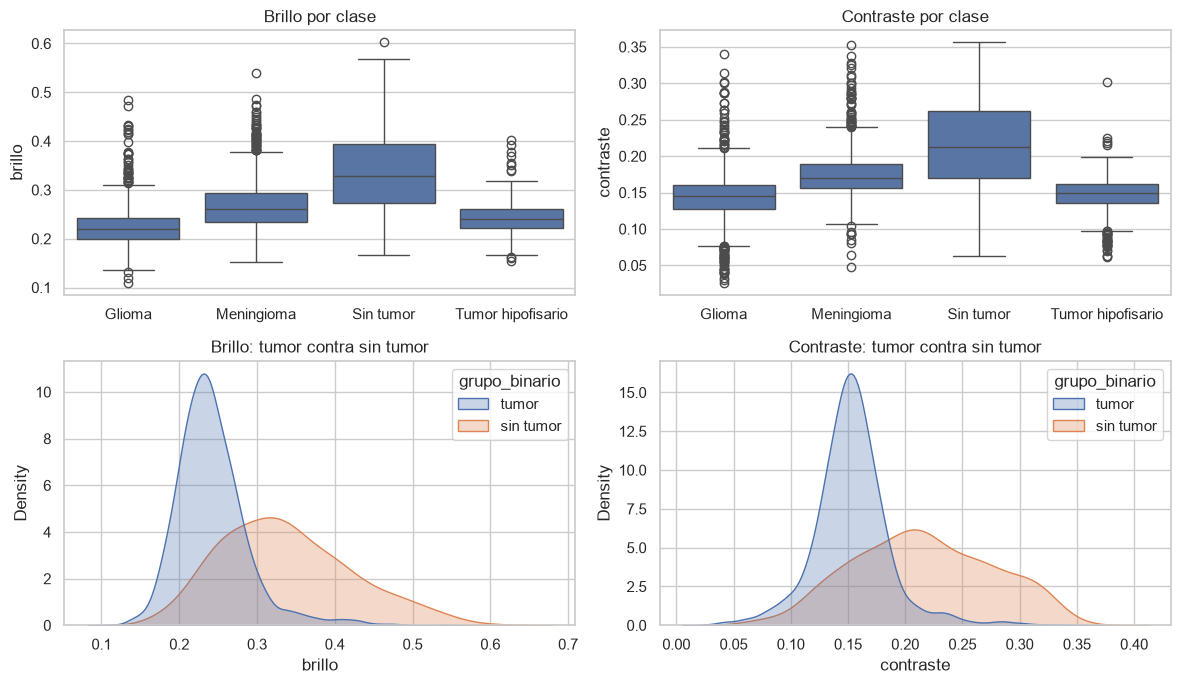

In [9]:
limpio["grupo_binario"] = np.where(limpio.es_tumor == 1, "tumor", "sin tumor")
limpio["nombre_clase"] = limpio.clase.map(config.NOMBRES_ES)
orden = [config.NOMBRES_ES[c] for c in config.CLASES]

descriptiva = limpio.groupby("clase")[["brillo", "contraste"]].agg(["count", "mean", "median", "std", "min", "max"]).round(4)
display(descriptiva)
display(limpio.groupby("grupo_binario")[["brillo", "contraste"]].agg(["count", "mean", "median", "std"]).round(4))

fig, axs = plt.subplots(2, 2, figsize=(12, 7))
sns.boxplot(data=limpio, x="nombre_clase", y="brillo", order=orden, ax=axs[0, 0]); axs[0, 0].set_title("Brillo por clase")
sns.boxplot(data=limpio, x="nombre_clase", y="contraste", order=orden, ax=axs[0, 1]); axs[0, 1].set_title("Contraste por clase")
sns.kdeplot(data=limpio, x="brillo", hue="grupo_binario", common_norm=False, fill=True, alpha=0.3, ax=axs[1, 0]); axs[1, 0].set_title("Brillo: tumor contra sin tumor")
sns.kdeplot(data=limpio, x="contraste", hue="grupo_binario", common_norm=False, fill=True, alpha=0.3, ax=axs[1, 1]); axs[1, 1].set_title("Contraste: tumor contra sin tumor")
for ax in axs[0]:
    ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_04_brillo_contraste.png", dpi=130); plt.show()

#### Intervalos de confianza
1. **Proporción de "sin tumor"** en los datos limpios, con el intervalo de Wilson al 95 %.
2. **Media del brillo** de cada grupo, con el intervalo t de Student al 95 %.

In [10]:
li, ls = wilson(n_sin, n)
print(f"Proporción de 'sin tumor': {n_sin / n:.4f} · IC 95 % de Wilson: [{li:.4f}, {ls:.4f}] (n = {n:,})")

filas_ic = []
for nombre, sub in limpio.groupby("grupo_binario"):
    for variable in ["brillo", "contraste"]:
        x = sub[variable].to_numpy()
        media, ee = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
        a, b = stats.t.interval(0.95, len(x) - 1, loc=media, scale=ee)
        filas_ic.append({"grupo": nombre, "variable": variable, "n": len(x), "media": media, "ic95_inferior": a, "ic95_superior": b})
tabla_ic = pd.DataFrame(filas_ic)
display(tabla_ic.round(4))

Proporción de 'sin tumor': 0.1019 · IC 95 % de Wilson: [0.0925, 0.1123] (n = 3,600)


,grupo,variable,n,media,ic95_inferior,ic95_superior
0,sin tumor,brillo,367,0.3375,0.3289,0.3461
1,sin tumor,contraste,367,0.2158,0.2096,0.2220
2,tumor,brillo,3233,0.2416,0.2400,0.2432
3,tumor,contraste,3233,0.1531,0.1520,0.1543


#### Pruebas de hipótesis
**Mann-Whitney U** (no supone normalidad), tumor contra sin tumor:
- H0: el brillo (o el contraste) tiene la misma distribución en los dos grupos.
- H1: las distribuciones son distintas. Nivel de significancia: 0.05.

Se reporta también el **tamaño del efecto** como la probabilidad de que una imagen con tumor sea más brillante que una sin tumor (0.5 = sin diferencia). Con miles de imágenes casi cualquier diferencia sale "significativa", así que el tamaño del efecto importa más que el valor p.

**Kruskal-Wallis** entre las 4 clases: H0 = la misma distribución en las cuatro.

In [11]:
filas_h = []
for variable in ["brillo", "contraste"]:
    a = limpio.loc[limpio.es_tumor == 1, variable].to_numpy()
    b = limpio.loc[limpio.es_tumor == 0, variable].to_numpy()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas_h.append({"prueba": "Mann-Whitney U (tumor contra sin tumor)", "variable": variable, "estadistico": u, "p_valor": p,
                    "efecto": u / (len(a) * len(b)), "detalle_efecto": "P(tumor > sin tumor)",
                    "mediana_tumor": np.median(a), "mediana_sin_tumor": np.median(b), "se_rechaza_H0": p < 0.05})
    grupos = [limpio.loc[limpio.clase == c, variable].to_numpy() for c in config.CLASES]
    h, pk = stats.kruskal(*grupos)
    filas_h.append({"prueba": "Kruskal-Wallis (4 clases)", "variable": variable, "estadistico": h, "p_valor": pk,
                    "efecto": (h - len(grupos) + 1) / (len(limpio) - len(grupos)), "detalle_efecto": "épsilon cuadrada",
                    "mediana_tumor": np.nan, "mediana_sin_tumor": np.nan, "se_rechaza_H0": pk < 0.05})
pruebas = pd.DataFrame(filas_h)
pruebas.to_csv(config.RESULTADOS / "eda_pruebas_hipotesis.csv", index=False, encoding="utf-8")
tabla_ic.to_csv(config.RESULTADOS / "eda_intervalos_confianza.csv", index=False, encoding="utf-8")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
display(pruebas)
pd.reset_option("display.float_format")

for r in pruebas.itertuples():
    decision = "se rechaza H0" if r.se_rechaza_H0 else "no se rechaza H0"
    print(f"{r.prueba} · {r.variable}: estadístico = {r.estadistico:.4g}, p = {r.p_valor:.3g} → {decision}; {r.detalle_efecto} = {r.efecto:.3f}")

,prueba,variable,estadistico,p_valor,efecto,detalle_efecto,mediana_tumor,mediana_sin_tumor,se_rechaza_H0
0,Mann-Whitney U (tumor contra sin tumor),brillo,1.76e+05,2.447e-108,0.1484,P(tumor > sin tumor),0.2358,0.3291,True
1,Kruskal-Wallis (4 clases),brillo,1027,2.304e-222,0.2848,épsilon cuadrada,NaN,NaN,True
2,Mann-Whitney U (tumor contra sin tumor),contraste,2.221e+05,4.022e-86,0.1872,P(tumor > sin tumor),0.1521,0.2131,True
3,Kruskal-Wallis (4 clases),contraste,928.2,6.914e-201,0.2573,épsilon cuadrada,NaN,NaN,True


Mann-Whitney U (tumor contra sin tumor) · brillo: estadístico = 1.76e+05, p = 2.45e-108 → se rechaza H0; P(tumor > sin tumor) = 0.148
Kruskal-Wallis (4 clases) · brillo: estadístico = 1027, p = 2.3e-222 → se rechaza H0; épsilon cuadrada = 0.285
Mann-Whitney U (tumor contra sin tumor) · contraste: estadístico = 2.221e+05, p = 4.02e-86 → se rechaza H0; P(tumor > sin tumor) = 0.187
Kruskal-Wallis (4 clases) · contraste: estadístico = 928.2, p = 6.91e-201 → se rechaza H0; épsilon cuadrada = 0.257


##### Interpretación y advertencia
La celda anterior imprime el resultado real de esta corrida. Cómo leerlo:
- Si **se rechaza H0**, el brillo o el contraste no se distribuyen igual en las imágenes con tumor y sin tumor. Eso **no** quiere decir que el brillo indique enfermedad: lo más probable es que refleje diferencias en cómo se obtuvieron las imágenes (equipo, tipo de corte, fuente de donde se juntó cada clase).
- **Advertencia:** un modelo podría apoyarse en el brillo general de la imagen y no en la anatomía. Por eso, en el notebook 03 se entrena a propósito un modelo que **solo** usa brillo, contraste e histograma: es la referencia mínima. Lo que ese modelo logre es lo que se puede "adivinar" sin mirar la forma del cerebro, y cualquier modelo mejor debe superarlo con claridad. El Grad-CAM del notebook 04 ayuda a revisar en qué zona se fija la red.
- Estos resultados describen **este dataset**; no se pueden generalizar a imágenes de otro hospital sin validarlo.

## 2.3 Preparación del dataset
División 80 / 20 en entrenamiento y prueba **por grupos de similitud**, 5 pliegues de validación cruzada (CV = 5), revisión de fuga, desbalance y manifiesto final.

#### División en entrenamiento y prueba, por grupos
- **Prueba:** una de las 5 partes de `StratifiedGroupKFold(5, shuffle=True, random_state=42)`, estratificado por las **4 clases** y con los **grupos de similitud** como grupos: ningún grupo queda repartido. Es cerca de 20 %; no es exacto porque los grupos no se pueden partir.
- **Pliegues de la validación cruzada:** el entrenamiento se divide otra vez igual, en 5 pliegues por grupos. Se guardan en la columna `pliegue` del manifiesto para que **todos** los modelos usen exactamente los mismos.
- La prueba no se vuelve a tocar hasta la evaluación final de los notebooks 03 y 04.

particion,entrenamiento,prueba,total,porcentaje_en_prueba
clase,,,,
glioma,1166,291,1457,20.0
meningioma,655,164,819,20.0
notumor,294,73,367,19.9
pituitary,765,192,957,20.1
total,2880,720,3600,20.0


particion,entrenamiento,prueba
grupo_binario,,
sin tumor,10.21,10.14
tumor,89.79,89.86


Imágenes por pliegue y clase (entrenamiento):


clase,glioma,meningioma,notumor,pituitary,total
pliegue,,,,,
1,233,131,59,153,576
2,233,131,59,153,576
3,234,131,58,153,576
4,233,131,59,153,576
5,233,131,59,153,576
total,1166,655,294,765,2880


Valores de sha256 compartidos entre entrenamiento y prueba: 0
Valores de hash_perceptual compartidos entre entrenamiento y prueba: 0
Valores de sha256_preparada compartidos entre entrenamiento y prueba: 0
Valores de hash_perceptual_preparada compartidos entre entrenamiento y prueba: 0
Valores de grupo_similitud compartidos entre entrenamiento y prueba: 0


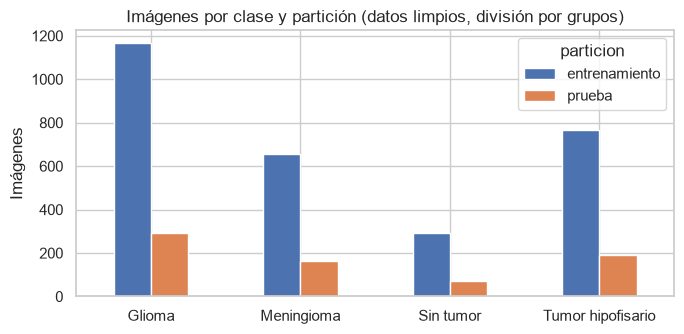

In [12]:
clases_limpio, grupos_limpio = limpio.clase.to_numpy(), limpio.grupo_similitud.to_numpy()
i_ent, i_pru = pliegues_estratificados(clases_limpio, 5, config.SEMILLA, grupos_limpio)[0]
limpio["particion"] = "entrenamiento"
limpio.loc[i_pru, "particion"] = "prueba"
limpio["pliegue"] = 0          # 0 = prueba; 1 a 5 = pliegue de la validación cruzada
pos_ent = np.flatnonzero((limpio.particion == "entrenamiento").to_numpy())
pos_pru = np.flatnonzero((limpio.particion == "prueba").to_numpy())
clases_ent, grupos_ent = clases_limpio[pos_ent], grupos_limpio[pos_ent]
PLIEGUES = pliegues_estratificados(clases_ent, config.N_PLIEGUES, config.SEMILLA, grupos_ent)
for k, (_, rel_pliegue) in enumerate(PLIEGUES, 1):
    limpio.loc[pos_ent[rel_pliegue], "pliegue"] = k

division = pd.crosstab(limpio.clase, limpio.particion, margins=True, margins_name="total").reindex(config.CLASES + ["total"])
division["porcentaje_en_prueba"] = (division.prueba / division.total * 100).round(1)
display(division)
display((pd.crosstab(limpio.grupo_binario, limpio.particion, normalize="columns") * 100).round(2))
print("Imágenes por pliegue y clase (entrenamiento):")
display(pd.crosstab(limpio.pliegue[limpio.pliegue > 0], limpio.clase, margins=True, margins_name="total"))

ent, pru = limpio[limpio.particion == "entrenamiento"], limpio[limpio.particion == "prueba"]
for h in HUELLAS + ["grupo_similitud"]:
    compartidos = set(ent[h]) & set(pru[h])
    print(f"Valores de {h} compartidos entre entrenamiento y prueba: {len(compartidos)}")
    assert not compartidos
assert ent.groupby("grupo_similitud").pliegue.nunique().max() == 1, "Un grupo quedó repartido entre pliegues."

ax = pd.crosstab(limpio.nombre_clase, limpio.particion).reindex(orden).plot(kind="bar", figsize=(7, 3.5), rot=0)
ax.set_xlabel(""); ax.set_ylabel("Imágenes"); ax.set_title("Imágenes por clase y partición (datos limpios, división por grupos)")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_05_division.png", dpi=130); plt.show()

##### Comprobación de fuga invariante a espejo y giro
Con los datos ya limpios y divididos se mide, para cada imagen, su mayor correlación de miniaturas (original y preparada, en las 8 orientaciones) con las imágenes **del otro lado** de cada frontera:
- **prueba ↔ entrenamiento**;
- **validación apartada ↔ su entrenamiento** (la parte que el notebook 04 aparta para la red, por grupos y con la misma semilla);
- **entre pliegues** de la validación cruzada (los 5 pliegues guardados en el manifiesto).

**Cómo leer la tabla**
- **Mayor de 0.98** (copias) y **mayor de 0.95** (la misma toma con otro contraste, copias recomprimidas, cortes casi idénticos): deben dar **0**. Las copias se eliminaron y lo que supera 0.95 viaja junto, en el mismo grupo.
- **Entre 0.90 y 0.95:** aquí **sí quedan parejas a los dos lados**, y no son solo "imágenes distintas". En esta banda hay sobre todo **cortes vecinos del mismo estudio** y también alguna toma repetida con un cambio de contraste o un recorte más fuerte. No se agrupan porque a ese nivel de parecido el encadenamiento ya une estudios enteros y tomas que no tienen relación.
- Los archivos `aug` (giros y zoom sintéticos) ya no están: se quitaron en el paso 1 porque su parecido con la imagen de origen cae por debajo de estos umbrales y no se podían controlar de otra forma.

**Límite que no se puede resolver con este dataset:** no trae identificador de paciente ni de estudio. Dos cortes distintos del mismo paciente pueden estar uno en entrenamiento y otro en prueba (**fuga por estudio**), así que las métricas de prueba siguen siendo, probablemente, algo optimistas respecto a pacientes nuevos.

In [13]:
MO, MP = MINI_O[POS_LIMPIO], MINI_P[POS_LIMPIO]


def gemelas(ia, ib):
    """Para cada imagen de `ia`: mayor correlación con alguna de `ib` (8 orientaciones, ambas miniaturas), cuál es y en qué orientación."""
    m1, k1, v1 = maxima_correlacion(MO[ia], MO[ib])
    m2, k2, v2 = maxima_correlacion(MP[ia], MP[ib])
    usa2 = m2 > m1
    return np.where(usa2, m2, m1), np.asarray(ib)[np.where(usa2, k2, k1)], np.where(usa2, v2, v1)


rel_tr, rel_va = apartar_validacion(clases_ent, 0.15, config.SEMILLA, grupos_ent)
print(f"Validación apartada del notebook 04 (por grupos): {len(rel_va)} imágenes; su entrenamiento: {len(rel_tr)}")
m_pru, par_pru, var_pru = gemelas(pos_pru, pos_ent)
maximos = {"prueba ↔ entrenamiento": m_pru,
           "validación apartada ↔ su entrenamiento": gemelas(pos_ent[rel_va], pos_ent[rel_tr])[0]}
entre_pliegues = np.zeros(len(pos_ent), dtype=np.float32)
for rel_resto, rel_pliegue in PLIEGUES:
    entre_pliegues[rel_pliegue] = gemelas(pos_ent[rel_pliegue], pos_ent[rel_resto])[0]
maximos["entre pliegues (cada imagen contra los otros 4 pliegues)"] = entre_pliegues

fuga = pd.DataFrame([{"frontera": nombre, "imagenes_revisadas": len(m),
                      "gemelas_corr_mayor_098": int((m > 0.98).sum()), "gemelas_corr_mayor_095": int((m > 0.95).sum()),
                      "gemelas_banda_090_095": int(((m > 0.90) & (m <= 0.95)).sum()),
                      "gemelas_corr_mayor_090": int((m > 0.90).sum()),
                      "porcentaje_mayor_090": round(float((m > 0.90).mean() * 100), 2), "correlacion_maxima": float(m.max())}
                     for nombre, m in maximos.items()])
fuga.to_csv(config.RESULTADOS / "eda_fuga_gemelas.csv", index=False, encoding="utf-8")
display(fuga)
for r in fuga.itertuples():
    print(f"{r.frontera}: de {r.imagenes_revisadas:,} imágenes, {r.gemelas_corr_mayor_098} tienen al otro lado una gemela con correlación > 0.98, "
          f"{r.gemelas_corr_mayor_095} con > 0.95 y {r.gemelas_banda_090_095} en la banda 0.90–0.95 ({r.porcentaje_mayor_090} % con > 0.90)")
sin_tumor_pru = limpio.es_tumor.to_numpy()[pos_pru] == 0
print(f"Prueba 'sin tumor': {int(sin_tumor_pru.sum())} imágenes · con gemela > 0.95 en entrenamiento: {int((m_pru[sin_tumor_pru] > 0.95).sum())} "
      f"· en la banda 0.90–0.95: {int(((m_pru[sin_tumor_pru] > 0.90) & (m_pru[sin_tumor_pru] <= 0.95)).sum())}")
assert int(fuga.gemelas_corr_mayor_095.sum()) == 0, "Quedaron gemelas (correlación > 0.95) entre particiones."

Validación apartada del notebook 04 (por grupos): 412 imágenes; su entrenamiento: 2468


,frontera,imagenes_revisadas,gemelas_corr_mayor_098,gemelas_corr_mayor_095,gemelas_banda_090_095,gemelas_corr_mayor_090,porcentaje_mayor_090,correlacion_maxima
0,prueba ↔ entrenamiento,720,0,0,318,318,44.17,0.949782
1,validación apartada ↔ su entrenamiento,412,0,0,169,169,41.02,0.949832
2,entre pliegues (cada imagen contra los otros 4...,2880,0,0,1057,1057,36.70,0.949832


prueba ↔ entrenamiento: de 720 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 318 en la banda 0.90–0.95 (44.17 % con > 0.90)
validación apartada ↔ su entrenamiento: de 412 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 169 en la banda 0.90–0.95 (41.02 % con > 0.90)
entre pliegues (cada imagen contra los otros 4 pliegues): de 2,880 imágenes, 0 tienen al otro lado una gemela con correlación > 0.98, 0 con > 0.95 y 1057 en la banda 0.90–0.95 (36.7 % con > 0.90)
Prueba 'sin tumor': 73 imágenes · con gemela > 0.95 en entrenamiento: 0 · en la banda 0.90–0.95: 6


Los 5 pares prueba ↔ entrenamiento de **mayor correlación que quedan** (todos por debajo de 0.95). Sirven para juzgar a simple vista qué tan parecidas son las imágenes que la división todavía separa.

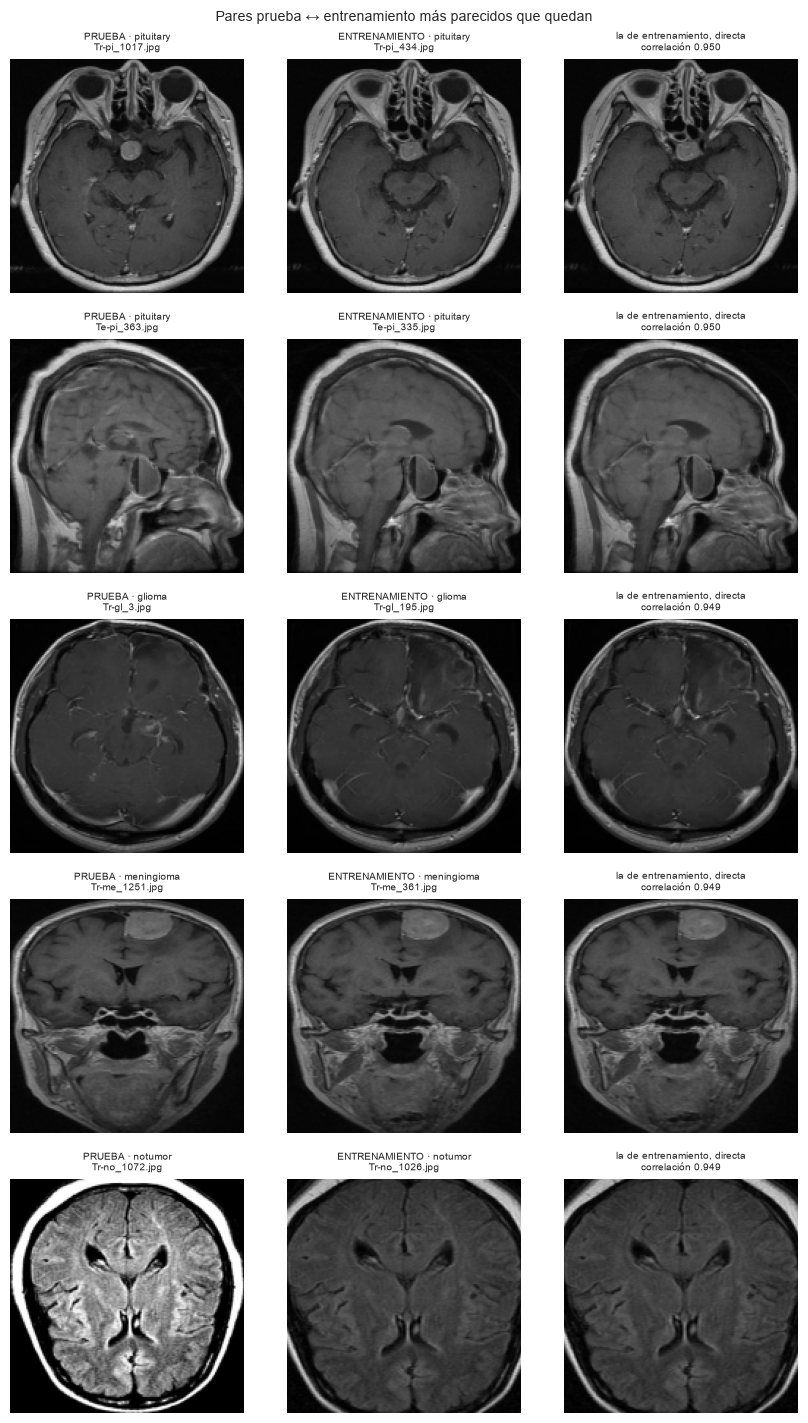

In [14]:
top = np.argsort(-m_pru)[:5]
fig, axs = plt.subplots(len(top), 3, figsize=(8.5, 2.9 * len(top)), squeeze=False)
for fila, k in zip(axs, top):
    a, b = limpio.iloc[pos_pru[k]], limpio.iloc[par_pru[k]]
    img_b = preparar(leer_imagen(config.RAIZ / b.ruta))
    fila[0].imshow(preparar(leer_imagen(config.RAIZ / a.ruta))); fila[0].set_title(f"PRUEBA · {a.clase}\n{Path(a.ruta).name}", fontsize=7)
    fila[1].imshow(img_b); fila[1].set_title(f"ENTRENAMIENTO · {b.clase}\n{Path(b.ruta).name}", fontsize=7)
    fila[2].imshow(VOLTEAR[var_pru[k]](img_b)); fila[2].set_title(f"la de entrenamiento, {var_pru[k].replace('_', ' ')}\ncorrelación {m_pru[k]:.3f}", fontsize=7)
    for ax in fila:
        ax.axis("off")
fig.suptitle("Pares prueba ↔ entrenamiento más parecidos que quedan", fontsize=10)
plt.tight_layout(); plt.savefig(FIGURAS / "eda_06_pares_prueba_entrenamiento.png", dpi=120); plt.show()

#### Desbalance
En el problema binario hay muchas más imágenes con tumor que sin tumor, y al quitar duplicados el desbalance crece, porque la clase "sin tumor" es la que más copias tenía (las cifras exactas están en la sección 3.1 y en la celda de abajo). Un modelo que dijera siempre "tumor" tendría una exactitud alta y no serviría: por eso la exactitud no es la métrica principal.

**Cómo se trata:** con **pesos de clase** (`class_weight="balanced"` en scikit-learn y una pérdida ponderada en Keras). No se duplican ni se eliminan imágenes. Los pesos se calculan solo con el entrenamiento.

**Métrica principal:** la **sensibilidad**, porque el error más costoso es el falso negativo (un tumor que se pasa por alto). El umbral de decisión se elige para una sensibilidad objetivo de 0.98 en validación, y se reportan también especificidad, precisión, F1 y AUC.

In [15]:
pesos = pesos_clase(ent.es_tumor)
print(f"Entrenamiento: {int((ent.es_tumor == 1).sum()):,} con tumor y {int((ent.es_tumor == 0).sum()):,} sin tumor")
print(f"Pesos de clase balanceados → sin tumor: {pesos[0]:.4f} · tumor: {pesos[1]:.4f}")

Entrenamiento: 2,586 con tumor y 294 sin tumor
Pesos de clase balanceados → sin tumor: 4.8980 · tumor: 0.5568


#### Manifiesto
`datos/manifiesto.csv` es la única lista de imágenes que usan los demás notebooks y la aplicación.

In [16]:
limpio["grupo"] = limpio.grupo_similitud   # mismo valor; se conserva el nombre anterior de la columna
columnas = ["ruta", "carpeta_origen", "clase", "es_tumor", "sha256", "hash_perceptual", "particion", "pliegue", "grupo_similitud", "grupo",
            "sha256_preparada", "hash_perceptual_preparada",
            "ancho", "alto", "brillo", "contraste"]
manifiesto = limpio[columnas]
manifiesto.to_csv(config.MANIFIESTO, index=False, encoding="utf-8")
print("Guardado:", config.MANIFIESTO, f"({len(manifiesto):,} filas)")
display(manifiesto.head())

resumen = pd.Series({
    "imagenes_en_carpetas": len(filas), "ilegibles": n_ilegibles, "demasiado_pequenas": n_chicas,
    "quitadas_por_aumento_del_dataset": int((df.causa == CAUSA_AUG).sum()),
    "quitadas_por_etiqueta_contradictoria": int((df.causa == CAUSA_CONTRA).sum()),
    "pares_contradictorios": len(choque),
    "quitadas_por_copia_exacta": int((df.causa == CAUSA_EXACTA).sum()),
    "quitadas_por_casi_identica": int((df.causa == CAUSA_CASI).sum()),
    "quitadas_por_espejo_o_giro": int((df.causa == CAUSA_ESPEJO).sum()),
    "quitadas_total": int((df.accion == "quitada").sum()),
    "recuperadas_frente_al_metodo_encadenado": int(recuperadas.loc["total", "recuperadas"]),
    "imagenes_limpias": len(limpio),
    "grupos_de_similitud": int(limpio.grupo_similitud.nunique()),
    "grupo_de_similitud_mas_grande": int(resumen_grupos["grupo más grande (imágenes)"]),
    "entrenamiento": len(ent), "prueba": len(pru),
}, name="valor")
resumen.to_csv(config.RESULTADOS / "eda_resumen.csv", header=True, index_label="concepto", encoding="utf-8")
display(resumen.to_frame())
print(f"Notebook terminado en {time.time() - INICIO:.0f} s")

Guardado: C:\proyectos\tumores-cerebrales\datos\manifiesto.csv (3,600 filas)


,ruta,carpeta_origen,clase,es_tumor,sha256,hash_perceptual,particion,pliegue,grupo_similitud,grupo,sha256_preparada,hash_perceptual_preparada,ancho,alto,brillo,contraste
0,datos/Training/glioma/Tr-gl_1.jpg,Training,glioma,1,eb139c78b32d818c5bba63983ceeaa560b71b7e427251a...,000003c00ff01ff83ff83ff83ffc3ffc3ffc3fc837e83f...,entrenamiento,1,0,0,0766481464780ec89283219f0c4fbd2ba875d6c908d875...,7ff8c03803dc7ffefffe7ffe1ffe0ffe1fc608c03de4ff...,512,512,0.207823,0.113185
1,datos/Training/glioma/Tr-gl_10.jpg,Training,glioma,1,7441c7ea5c1474ae20efdc2169e7e86d81204289354d86...,03000fe01ff03ff83ffc3ffc3ffc3ffc3ffc3fdc3ffc3f...,entrenamiento,2,1,1,4f5f4d2d4fe3281608df7bbf0488a376504e05b1fd1e4f...,0fc01c703fdc7f9c7ffefffffffdfff9ffef4fce7fee7b...,512,512,0.240194,0.163783
2,datos/Training/glioma/Tr-gl_100.jpg,Training,glioma,1,db7bc5885e0f6f532fa2757dc3aa5a23db57eeb1c58189...,0000000003800fe01ff03ff83ff83ff83ffc3ff03ff83f...,prueba,0,2,2,f4edf13578677e208dd1b4ee12cd70eb06503080b1d7d6...,0fe0383827ec5ff2fffcbffcbfe5bfdd9ddcdd9646e37f...,512,512,0.268639,0.163834
3,datos/Training/glioma/Tr-gl_1000.jpg,Training,glioma,1,e7310f1c588b7b5259754665a81e2aacf78cc97b10d801...,02000fc01ff03ff82ffc7ffe7ffe7ffe7ffa3fc63fcc3f...,entrenamiento,3,3,3,82c36afd8b067bd99a3a00c8a152848bd79ce02d6046b6...,e7cccf061ff33ffc7ffe7fdf7fef7eff7fe83fc0bf80bb...,512,512,0.223719,0.114447
4,datos/Training/glioma/Tr-gl_1001.jpg,Training,glioma,1,d7595c5cf5e8747271e162b0ef4399c38f8d97c16c371c...,0000000007e00ff00ff01ff81ff81ff81ff81ff81ff80f...,entrenamiento,5,4,4,e204f77505bb57a0e7eef687d934f9ee00cf78f3ca08ba...,07e0189017e81ff05ffe5ffffdfdbdfdb9e1b9fd9fff4f...,512,512,0.229865,0.158315


,valor
imagenes_en_carpetas,7200
ilegibles,0
demasiado_pequenas,0
quitadas_por_aumento_del_dataset,203
quitadas_por_etiqueta_contradictoria,34
pares_contradictorios,27
quitadas_por_copia_exacta,215
quitadas_por_casi_identica,409
quitadas_por_espejo_o_giro,2739
quitadas_total,3600


Notebook terminado en 271 s


## 2.4 Creación de rasgos
Cada imagen se convierte una sola vez en 1,280 números con MobileNetV2 congelada (y en 18 rasgos básicos de brillo, contraste e histograma). Después, PCA y K-Means para entender los datos.

In [17]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from app.backend.ml import config, rasgos
from app.backend.ml.preprocesar import cargar_lote

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
config.RASGOS.mkdir(parents=True, exist_ok=True)
INICIO = time.time()

man = pd.read_csv(config.MANIFIESTO)
print(f"Manifiesto: {len(man):,} imágenes")
display(pd.crosstab(man.clase, man.particion, margins=True, margins_name="total"))

Manifiesto: 3,600 imágenes


particion,entrenamiento,prueba,total
clase,,,
glioma,1166,291,1457
meningioma,655,164,819
notumor,294,73,367
pituitary,765,192,957
total,2880,720,3600


#### Extracción (una sola vez)

In [18]:
RUTA_MOBILENET = config.RASGOS / "rasgos_mobilenet.npz"
RUTA_BASICOS = config.RASGOS / "rasgos_basicos.npz"
RUTA_IMAGENES = config.RASGOS / "imagenes_160.npy"   # imágenes preparadas, para el ajuste fino del notebook 04
rutas = man.ruta.to_numpy().astype(str)


RUTA_FIRMA_IMAGENES = config.RASGOS / "imagenes_160.firma.txt"
FIRMA = rasgos.firma_cache(man)
print("Firma del manifiesto + preprocesamiento:", FIRMA[:16], "…")


def vigente(ruta_npz):
    """El archivo existe, tiene la misma firma y sus rutas son las del manifiesto en el mismo orden."""
    if not ruta_npz.exists():
        return False
    with np.load(ruta_npz, allow_pickle=False) as d:
        return ("firma" in d.files and str(d["firma"]) == FIRMA
                and len(d["rutas"]) == len(rutas) and bool((d["rutas"] == rutas).all()))


imagenes_vigentes = (RUTA_IMAGENES.exists() and RUTA_FIRMA_IMAGENES.exists()
                     and RUTA_FIRMA_IMAGENES.read_text(encoding="utf-8").strip() == FIRMA)
if vigente(RUTA_MOBILENET) and vigente(RUTA_BASICOS) and imagenes_vigentes:
    print("Los rasgos ya existen y su firma coincide con el manifiesto y el preprocesamiento actuales: se leen del disco.")
else:
    print("No hay rasgos guardados para este manifiesto y este preprocesamiento: se calculan.")
    t0 = time.time()
    imagenes = cargar_lote([config.RAIZ / r for r in rutas], hilos=12)
    print(f"Imágenes preparadas: {imagenes.shape} {imagenes.dtype} en {time.time() - t0:.0f} s")
    np.save(RUTA_IMAGENES, imagenes)
    RUTA_FIRMA_IMAGENES.write_text(FIRMA, encoding="utf-8")

    t0 = time.time()
    X_basicos = rasgos.rasgos_basicos_lote(imagenes)
    np.savez_compressed(RUTA_BASICOS, X=X_basicos, rutas=rutas, nombres=np.array(rasgos.NOMBRES_BASICOS), firma=np.array(FIRMA))
    print(f"Rasgos básicos: {X_basicos.shape} en {time.time() - t0:.0f} s")

    t0 = time.time()
    X_mobilenet = rasgos.rasgos_mobilenet(imagenes)
    np.savez_compressed(RUTA_MOBILENET, X=X_mobilenet, rutas=rutas, firma=np.array(FIRMA))
    print(f"Rasgos MobileNetV2: {X_mobilenet.shape} en {time.time() - t0:.0f} s")
    del imagenes

with np.load(RUTA_MOBILENET, allow_pickle=False) as d:
    X = d["X"]
with np.load(RUTA_BASICOS, allow_pickle=False) as d:
    Xb = d["X"]
print("MobileNetV2:", X.shape, "· básicos:", Xb.shape, "· valores no finitos:", int((~np.isfinite(X)).sum() + (~np.isfinite(Xb)).sum()))
display(pd.DataFrame(Xb, columns=rasgos.NOMBRES_BASICOS).describe().T.round(4))

Firma del manifiesto + preprocesamiento: b2c9d71d55da7d41 …
Los rasgos ya existen y su firma coincide con el manifiesto y el preprocesamiento actuales: se leen del disco.
MobileNetV2: (3600, 1280) · básicos: (3600, 18) · valores no finitos: 0


,count,mean,std,min,25%,50%,75%,max
brillo,3600.0,0.2514,0.0588,0.1096,0.2146,0.2398,0.2713,0.6021
contraste,3600.0,0.1595,0.0420,0.0260,0.1370,0.1544,0.1737,0.3561
hist_00,3600.0,0.1786,0.0625,0.0000,0.1467,0.1844,0.2177,0.4962
hist_01,3600.0,0.0601,0.0326,0.0000,0.0408,0.0548,0.0732,0.3946
hist_02,3600.0,0.1002,0.0711,0.0000,0.0610,0.0858,0.1165,0.6692
hist_03,3600.0,0.1789,0.1114,0.0053,0.1072,0.1522,0.2240,0.7062
hist_04,3600.0,0.1864,0.0867,0.0027,0.1247,0.1918,0.2461,0.5480
hist_05,3600.0,0.1122,0.0704,0.0008,0.0555,0.0940,0.1646,0.4675
hist_06,3600.0,0.0600,0.0465,0.0004,0.0336,0.0470,0.0677,0.4098
hist_07,3600.0,0.0399,0.0326,0.0000,0.0223,0.0328,0.0457,0.3871


#### PCA: ¿se separan las clases?
Se estandarizan los 1,280 rasgos y se resumen con PCA, **ajustando solo con el entrenamiento**. Si las clases se separan en dos dimensiones, un modelo sencillo sobre estos rasgos debería funcionar bien.

Varianza explicada: componente 1 = 6.4%, componente 2 = 4.5%
Acumulada con 2 componentes: 10.9% · con 10: 28.3% · con 50: 51.7%


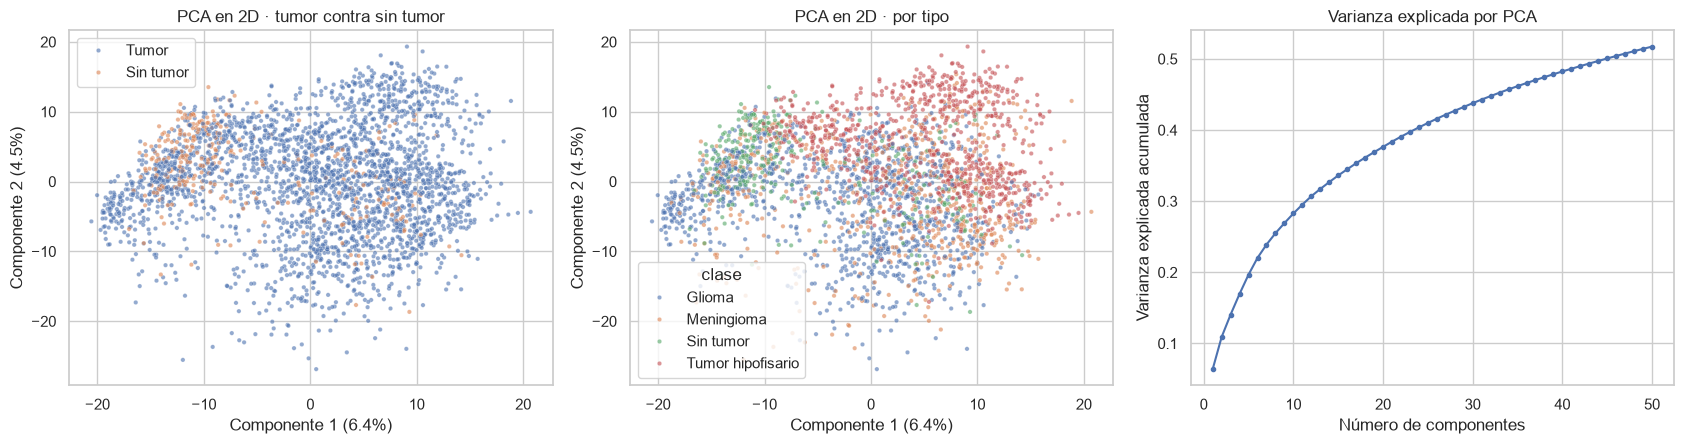

In [19]:
ent = (man.particion == "entrenamiento").to_numpy()
man_ent = man[ent].reset_index(drop=True)
escala = StandardScaler().fit(X[ent])
pca = PCA(n_components=50, random_state=config.SEMILLA).fit(escala.transform(X[ent]))
Z = pca.transform(escala.transform(X[ent]))
acumulada = np.cumsum(pca.explained_variance_ratio_)
print(f"Varianza explicada: componente 1 = {pca.explained_variance_ratio_[0]:.1%}, componente 2 = {pca.explained_variance_ratio_[1]:.1%}")
print(f"Acumulada con 2 componentes: {acumulada[1]:.1%} · con 10: {acumulada[9]:.1%} · con 50: {acumulada[49]:.1%}")

binaria = np.where(man_ent.es_tumor == 1, "Tumor", "Sin tumor")
nombres = man_ent.clase.map(config.NOMBRES_ES)
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=binaria, hue_order=["Tumor", "Sin tumor"], s=10, alpha=0.6, ax=axs[0])
axs[0].set_title("PCA en 2D · tumor contra sin tumor")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=nombres, hue_order=[config.NOMBRES_ES[c] for c in config.CLASES], s=10, alpha=0.6, ax=axs[1])
axs[1].set_title("PCA en 2D · por tipo")
for ax in axs[:2]:
    ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%})")
axs[2].plot(range(1, 51), acumulada, marker="o", ms=3)
axs[2].set_xlabel("Número de componentes"); axs[2].set_ylabel("Varianza explicada acumulada"); axs[2].set_title("Varianza explicada por PCA")
plt.tight_layout(); plt.savefig(FIGURAS / "rasgos_01_pca.png", dpi=130); plt.show()
pd.DataFrame({"componente": range(1, 51), "varianza": pca.explained_variance_ratio_, "acumulada": acumulada}).to_csv(
    config.RESULTADOS / "pca_varianza.csv", index=False)

#### K-Means: ¿aparecen las clases sin usar etiquetas?
K-Means agrupa las imágenes solo por parecido (sobre los 50 componentes de PCA). Se prueba con 2 grupos (contra tumor / sin tumor) y con 4 grupos (contra las 4 clases).

El **índice de Rand ajustado** compara los grupos con las clases reales: 1 = idénticos, 0 = como al azar.

grupo K-Means (k=2),0,1
clase real,,
Sin tumor,210,84
Tumor,885,1701


Índice de Rand ajustado (k=2 contra tumor / sin tumor): 0.073


grupo K-Means (k=4),0,1,2,3
clase real,,,,
Glioma,34,416,418,298
Meningioma,58,161,263,173
Sin tumor,11,200,60,23
Tumor hipofisario,198,30,268,269


Índice de Rand ajustado (k=4 contra las 4 clases): 0.058


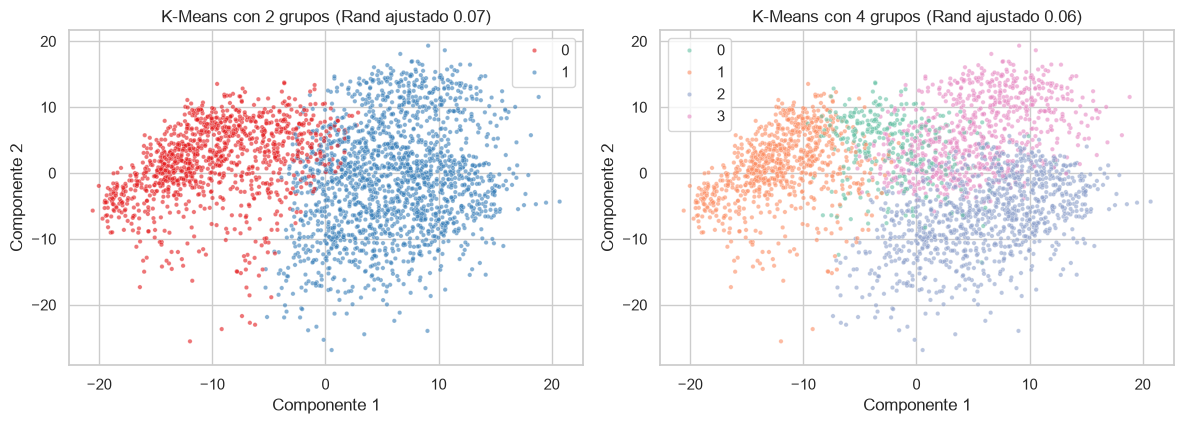

In [20]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=config.SEMILLA).fit(Z)
km4 = KMeans(n_clusters=4, n_init=10, random_state=config.SEMILLA).fit(Z)
tabla2 = pd.crosstab(pd.Series(binaria, name="clase real"), pd.Series(km2.labels_, name="grupo K-Means (k=2)"))
tabla4 = pd.crosstab(pd.Series(nombres.to_numpy(), name="clase real"), pd.Series(km4.labels_, name="grupo K-Means (k=4)"))
ari2 = adjusted_rand_score(man_ent.es_tumor, km2.labels_)
ari4 = adjusted_rand_score(man_ent.clase, km4.labels_)
display(tabla2); print(f"Índice de Rand ajustado (k=2 contra tumor / sin tumor): {ari2:.3f}")
display(tabla4); print(f"Índice de Rand ajustado (k=4 contra las 4 clases): {ari4:.3f}")
tabla2.to_csv(config.RESULTADOS / "kmeans_k2_tabla.csv"); tabla4.to_csv(config.RESULTADOS / "kmeans_k4_tabla.csv")
pd.DataFrame([{"k": 2, "comparado_con": "tumor / sin tumor", "rand_ajustado": ari2},
              {"k": 4, "comparado_con": "4 clases", "rand_ajustado": ari4}]).to_csv(config.RESULTADOS / "kmeans_rand.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km2.labels_, palette="Set1", s=10, alpha=0.6, ax=axs[0]); axs[0].set_title(f"K-Means con 2 grupos (Rand ajustado {ari2:.2f})")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km4.labels_, palette="Set2", s=10, alpha=0.6, ax=axs[1]); axs[1].set_title(f"K-Means con 4 grupos (Rand ajustado {ari4:.2f})")
for ax in axs:
    ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
plt.tight_layout(); plt.savefig(FIGURAS / "rasgos_02_kmeans.png", dpi=130); plt.show()

##### Lectura
- Las cifras de arriba son las de esta corrida. Un índice de Rand ajustado cercano a 0 significa que los grupos naturales de los rasgos **no** coinciden con las clases; cercano a 1, que coinciden.
- Que K-Means no recupere las clases no impide que un modelo supervisado las separe: la separación puede estar en direcciones que no son las de mayor varianza.
- PCA y K-Means se usan aquí solo para **entender** los datos. Los modelos del notebook 03 usan los 1,280 rasgos completos.
- La comprobación de fuga entre entrenamiento y prueba (copias, espejos y giros) está al final del notebook 01. No se repite aquí con los rasgos de MobileNetV2 porque esos rasgos **no** son invariantes al espejo: una imagen y su espejo pueden dar rasgos distintos, así que esa medida subestimaría la fuga.

In [21]:
print(f"Notebook terminado en {time.time() - INICIO:.0f} s")

Notebook terminado en 3 s


# 3. Modelos
## 3.1 Modelos clásicos (Módulo 3)
Solución más simple (logística con rasgos básicos), regresión logística, Random Forest y SVM, con los mismos 5 pliegues y las mismas métricas. El umbral se elige con la validación cruzada y la prueba se evalúa una sola vez.

In [22]:
import os
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from app.backend.ml.entrenar import pliegues_estratificados
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from app.backend.ml import config, rasgos
from app.backend.ml.metricas import elegir_umbral, metricas_binarias, metricas_por_pliegue, wilson

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = config.RESULTADOS / "modelos_clasicos"
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
OBJETIVO = config.SENSIBILIDAD_OBJETIVO
INICIO = time.time()
print("Versiones:", config.versiones())

Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


#### Datos
Se leen el manifiesto y los rasgos guardados por el notebook 02 (mismo orden).

In [23]:
man = pd.read_csv(config.MANIFIESTO)
FIRMA = rasgos.firma_cache(man)
with np.load(config.RASGOS / "rasgos_mobilenet.npz", allow_pickle=False) as d:
    X_mob, rutas_mob = d["X"], d["rutas"]
    assert str(d["firma"]) == FIRMA, "Los rasgos guardados son de otro manifiesto o preprocesamiento: ejecute de nuevo el notebook 02."
with np.load(config.RASGOS / "rasgos_basicos.npz", allow_pickle=False) as d:
    X_bas, rutas_bas = d["X"], d["rutas"]
assert (rutas_mob == man.ruta.to_numpy()).all() and (rutas_bas == man.ruta.to_numpy()).all(), "Los rasgos no corresponden al manifiesto: ejecute de nuevo el notebook 02."

ent = (man.particion == "entrenamiento").to_numpy()
pru = (man.particion == "prueba").to_numpy()
man_ent, man_pru = man[ent].reset_index(drop=True), man[pru].reset_index(drop=True)
y_ent, y_pru = man_ent.es_tumor.to_numpy(), man_pru.es_tumor.to_numpy()
RASGOS = {"basicos": (X_bas[ent], X_bas[pru]), "mobilenet": (X_mob[ent], X_mob[pru])}
print(f"Entrenamiento: {len(y_ent):,} ({y_ent.mean():.1%} con tumor) · Prueba: {len(y_pru):,} ({y_pru.mean():.1%} con tumor)")

# Pliegues: estratificados por las 4 clases (eso también estratifica tumor / sin tumor).
pliegue_de = man_ent.pliegue.to_numpy()
PLIEGUES = [(np.flatnonzero(pliegue_de != k), np.flatnonzero(pliegue_de == k)) for k in range(1, config.N_PLIEGUES + 1)]
# Comprobación: son los pliegues por grupos que da el paquete compartido, y ningún grupo está repartido
recalculados = pliegues_estratificados(man_ent.clase.to_numpy(), config.N_PLIEGUES, config.SEMILLA, man_ent.grupo_similitud.to_numpy())
assert all((a[1] == b[1]).all() for a, b in zip(PLIEGUES, recalculados)), "Los pliegues del manifiesto no coinciden con los recalculados."
assert man_ent.groupby("grupo_similitud").pliegue.nunique().max() == 1
assert not set(man_ent.grupo_similitud) & set(man_pru.grupo_similitud), "Hay grupos de similitud repartidos entre entrenamiento y prueba."
print(f"Grupos de similitud en entrenamiento: {man_ent.grupo_similitud.nunique():,} · ninguno repartido entre pliegues ni compartido con la prueba")
print(f"Imágenes 'sin tumor' en prueba: {int((y_pru == 0).sum())} (la especificidad de prueba se mide con esas pocas imágenes: su intervalo de confianza es ancho)")
display(pd.crosstab(pd.Series(pliegue_de, name="pliegue"), man_ent.clase))

Entrenamiento: 2,880 (89.8% con tumor) · Prueba: 720 (89.9% con tumor)

Grupos de similitud en entrenamiento: 2,608 · ninguno repartido entre pliegues ni compartido con la prueba
Imágenes 'sin tumor' en prueba: 73 (la especificidad de prueba se mide con esas pocas imágenes: su intervalo de confianza es ancho)


clase,glioma,meningioma,notumor,pituitary
pliegue,,,,
1,233,131,59,153
2,233,131,59,153
3,234,131,58,153
4,233,131,59,153
5,233,131,59,153


#### Modelos

In [24]:
def tuberia(modelo):
    return Pipeline([("escala", StandardScaler()), ("modelo", modelo)])

MODELOS = {
    "Logística (rasgos básicos)": {"archivo": "logistica_basica", "rasgos": "basicos",
        "tuberia": tuberia(LogisticRegression(max_iter=5000, C=1.0, class_weight="balanced", random_state=config.SEMILLA))},
    "Logística (MobileNetV2)": {"archivo": "logistica_mobilenet", "rasgos": "mobilenet",
        "tuberia": tuberia(LogisticRegression(max_iter=5000, C=1.0, class_weight="balanced", random_state=config.SEMILLA))},
    "Random Forest (MobileNetV2)": {"archivo": "random_forest", "rasgos": "mobilenet",
        "tuberia": tuberia(RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=config.SEMILLA))},
    "SVM RBF (MobileNetV2)": {"archivo": "svm_rbf", "rasgos": "mobilenet",
        "tuberia": tuberia(SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", probability=True, random_state=config.SEMILLA))},
}
for nombre, m in MODELOS.items():
    print(f"{nombre}: {m['tuberia'].named_steps['modelo']}")

Logística (rasgos básicos): LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)
Logística (MobileNetV2): LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)
Random Forest (MobileNetV2): RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)
SVM RBF (MobileNetV2): SVC(C=10, class_weight='balanced', probability=True, random_state=42)


Los hiperparámetros son valores fijos razonables (no se buscaron con la prueba ni con una búsqueda en malla): el objetivo es comparar familias de modelos en igualdad de condiciones.

#### Validación cruzada
Para cada modelo y cada pliegue: se entrena con 4 partes y se predice la parte restante. Así cada imagen de entrenamiento recibe una probabilidad de un modelo que **no la vio** (predicción fuera de pliegue).

In [25]:
prob_oof, segundos = {}, {}
for nombre, m in MODELOS.items():
    X = RASGOS[m["rasgos"]][0]
    t0 = time.time()
    p = np.full(len(y_ent), np.nan)
    for i_tr, i_va in PLIEGUES:
        modelo = clone(m["tuberia"]).fit(X[i_tr], y_ent[i_tr])
        p[i_va] = modelo.predict_proba(X[i_va])[:, 1]
    assert not np.isnan(p).any()
    prob_oof[nombre], segundos[nombre] = p, time.time() - t0
    print(f"{nombre:30s} listo en {segundos[nombre]:6.1f} s · AUC fuera de pliegue = {metricas_binarias(y_ent, p)['auc']:.4f}")

Logística (rasgos básicos)     listo en    0.1 s · AUC fuera de pliegue = 0.9020


Logística (MobileNetV2)        listo en    0.3 s · AUC fuera de pliegue = 0.9863


Random Forest (MobileNetV2)    listo en    5.6 s · AUC fuera de pliegue = 0.9854


SVM RBF (MobileNetV2)          listo en   22.7 s · AUC fuera de pliegue = 0.9911


#### Umbral de decisión
Por defecto un modelo dice "tumor" cuando la probabilidad es ≥ 0.5. Aquí el umbral se baja o se sube para que la **sensibilidad sea al menos 0.98**: se toma el umbral más alto que lo cumple sobre las predicciones fuera de pliegue (así se pierde la menor especificidad posible).

**Nota honesta:** como el umbral se elige con todas las predicciones fuera de pliegue juntas, la sensibilidad de la validación cruzada queda en 0.98 por construcción. Lo que distingue a los modelos en la validación cruzada es la **especificidad** que conservan a esa sensibilidad y el **AUC** (que no depende del umbral). La medición independiente es la del conjunto de prueba, al final.

In [26]:
METRICAS = ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]
umbrales, filas_pliegue, filas_resumen, filas_oof = {}, [], [], []
for nombre in MODELOS:
    p = prob_oof[nombre]
    u = elegir_umbral(y_ent, p, OBJETIVO)
    umbrales[nombre] = u
    por_pliegue = pd.DataFrame(metricas_por_pliegue(y_ent, p, pliegue_de, u))
    en_05 = pd.DataFrame(metricas_por_pliegue(y_ent, p, pliegue_de, 0.5))
    por_pliegue["sensibilidad_umbral_05"], por_pliegue["especificidad_umbral_05"] = en_05.sensibilidad, en_05.especificidad
    por_pliegue.insert(0, "modelo", nombre)
    filas_pliegue.append(por_pliegue)
    total = metricas_binarias(y_ent, p, u)
    fila = {"modelo": nombre, "umbral": u}
    for met in METRICAS:
        fila[f"{met}_media"], fila[f"{met}_std"] = por_pliegue[met].mean(), por_pliegue[met].std(ddof=1)
    fila.update({"sensibilidad_oof": total["sensibilidad"], "especificidad_oof": total["especificidad"], "auc_oof": total["auc"],
                 "vp": total["vp"], "vn": total["vn"], "fp": total["fp"], "fn": total["fn"],
                 "segundos_cv": segundos[nombre], "nota": "5 pliegues; modelo completo en cada pliegue"})
    filas_resumen.append(fila)
    filas_oof.append(pd.DataFrame({"ruta": man_ent.ruta, "modelo": nombre, "pliegue": pliegue_de, "clase": man_ent.clase,
                                   "es_tumor": y_ent, "probabilidad_tumor": p, "umbral": u, "prediccion": (p >= u).astype(int)}))

cv_pliegues = pd.concat(filas_pliegue, ignore_index=True)
cv_resumen = pd.DataFrame(filas_resumen)
pred_oof = pd.concat(filas_oof, ignore_index=True)
cv_pliegues.to_csv(config.RESULTADOS / "cv_pliegues.csv", index=False, encoding="utf-8")
cv_resumen.to_csv(config.RESULTADOS / "cv_resumen.csv", index=False, encoding="utf-8")
pred_oof.to_csv(config.RESULTADOS / "predicciones_oof.csv", index=False, encoding="utf-8")

print("Métricas por pliegue (al umbral elegido):")
display(cv_pliegues.round(4))

def media_std(tabla, metricas=METRICAS[:5]):
    vista = tabla[["modelo", "umbral"]].copy()
    vista["umbral"] = vista.umbral.round(4)
    for met in metricas:
        vista[met] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(tabla[f"{met}_media"], tabla[f"{met}_std"])]
    return vista

print("Resumen: media ± desviación estándar de los 5 pliegues")
display(media_std(cv_resumen))
display(cv_resumen[["modelo", "sensibilidad_oof", "especificidad_oof", "auc_oof", "vp", "vn", "fp", "fn", "segundos_cv"]].round(4))

Métricas por pliegue (al umbral elegido):


,modelo,pliegue,umbral,vp,vn,fp,fn,sensibilidad,especificidad,precision,f1,exactitud,auc,sensibilidad_umbral_05,especificidad_umbral_05
0,Logística (rasgos básicos),1,0.0225,505,12,47,12,0.9768,0.2034,0.9149,0.9448,0.8976,0.9310,0.9246,0.8305
1,Logística (rasgos básicos),2,0.0225,507,20,39,10,0.9807,0.3390,0.9286,0.9539,0.9149,0.8338,0.8975,0.7627
2,Logística (rasgos básicos),3,0.0225,506,19,39,12,0.9768,0.3276,0.9284,0.9520,0.9115,0.9138,0.9112,0.8276
3,Logística (rasgos básicos),4,0.0225,509,16,43,8,0.9845,0.2712,0.9221,0.9523,0.9115,0.9542,0.9362,0.8136
4,Logística (rasgos básicos),5,0.0225,508,12,47,9,0.9826,0.2034,0.9153,0.9478,0.9028,0.8874,0.9246,0.7627
5,Logística (MobileNetV2),1,0.6276,511,52,7,6,0.9884,0.8814,0.9865,0.9874,0.9774,0.9900,0.9903,0.8475
6,Logística (MobileNetV2),2,0.6276,504,52,7,13,0.9749,0.8814,0.9863,0.9805,0.9653,0.9664,0.9807,0.8644
7,Logística (MobileNetV2),3,0.6276,503,51,7,15,0.9710,0.8793,0.9863,0.9786,0.9618,0.9927,0.9730,0.8793
8,Logística (MobileNetV2),4,0.6276,506,54,5,11,0.9787,0.9153,0.9902,0.9844,0.9722,0.9928,0.9826,0.8644
9,Logística (MobileNetV2),5,0.6276,511,51,8,6,0.9884,0.8644,0.9846,0.9865,0.9757,0.9919,0.9903,0.7966


Resumen: media ± desviación estándar de los 5 pliegues


,modelo,umbral,sensibilidad,especificidad,precision,f1,auc
0,Logística (rasgos básicos),0.0225,0.9803 ± 0.0034,0.2689 ± 0.0651,0.9219 ± 0.0067,0.9502 ± 0.0038,0.9040 ± 0.0462
1,Logística (MobileNetV2),0.6276,0.9803 ± 0.0079,0.8843 ± 0.0187,0.9868 ± 0.0021,0.9835 ± 0.0038,0.9868 ± 0.0115
2,Random Forest (MobileNetV2),0.6367,0.9803 ± 0.0060,0.7822 ± 0.0359,0.9754 ± 0.0037,0.9778 ± 0.0016,0.9855 ± 0.0057
3,SVM RBF (MobileNetV2),0.7493,0.9803 ± 0.0088,0.9150 ± 0.0205,0.9902 ± 0.0024,0.9852 ± 0.0047,0.9913 ± 0.0033


,modelo,sensibilidad_oof,especificidad_oof,auc_oof,vp,vn,fp,fn,segundos_cv
0,Logística (rasgos básicos),0.9803,0.2687,0.9020,2535,79,215,51,0.0864
1,Logística (MobileNetV2),0.9803,0.8844,0.9863,2535,260,34,51,0.3444
2,Random Forest (MobileNetV2),0.9803,0.7823,0.9854,2535,230,64,51,5.6445
3,SVM RBF (MobileNetV2),0.9803,0.9150,0.9911,2535,269,25,51,22.7195


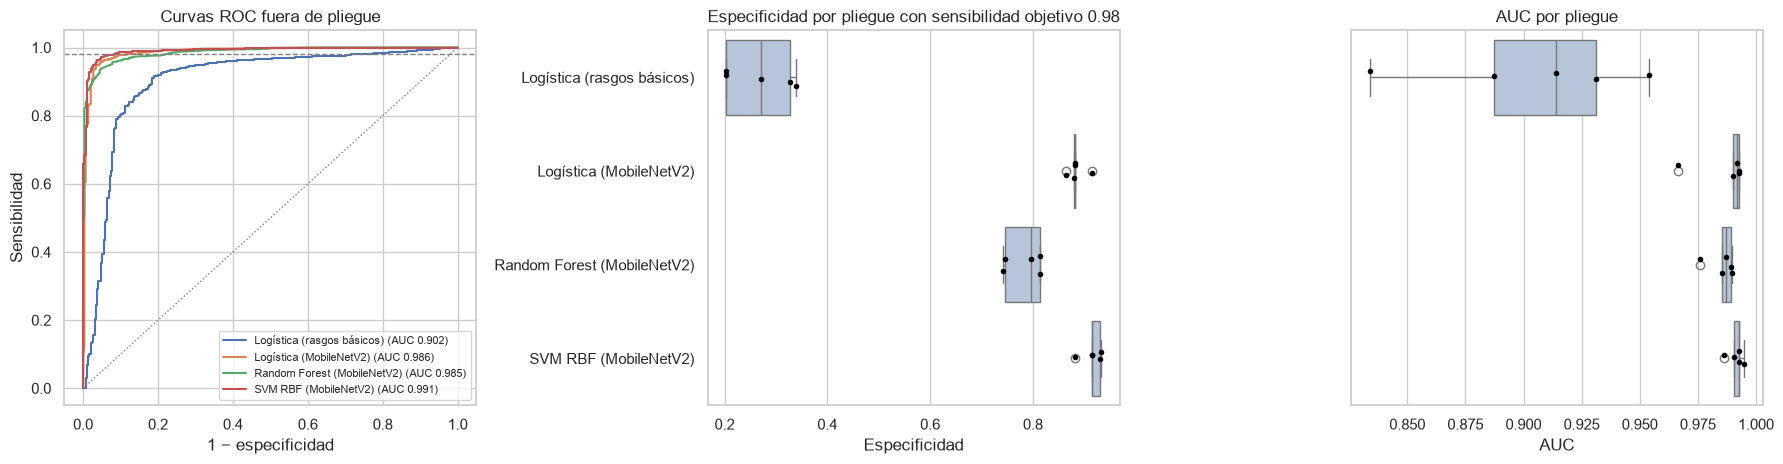

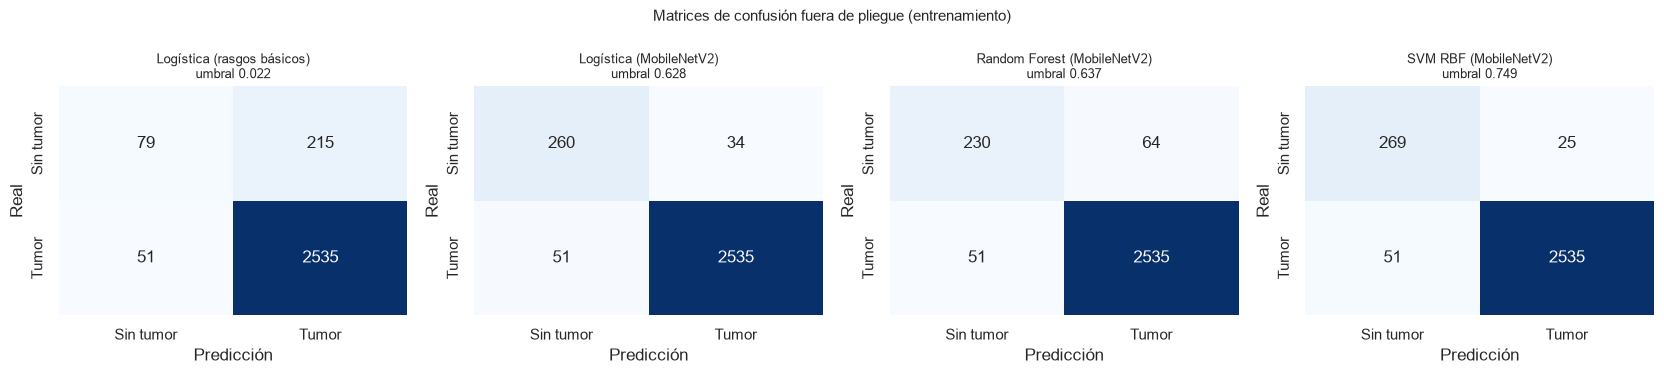

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
for nombre in MODELOS:
    fpr, tpr, _ = roc_curve(y_ent, prob_oof[nombre])
    auc = cv_resumen.set_index("modelo").loc[nombre, "auc_oof"]
    axs[0].plot(fpr, tpr, label=f"{nombre} (AUC {auc:.3f})")
axs[0].axhline(OBJETIVO, ls="--", color="gray", lw=1)
axs[0].plot([0, 1], [0, 1], ls=":", color="gray", lw=1)
axs[0].set_xlabel("1 − especificidad"); axs[0].set_ylabel("Sensibilidad"); axs[0].set_title("Curvas ROC fuera de pliegue"); axs[0].legend(fontsize=8)
largo = cv_pliegues.melt(id_vars=["modelo", "pliegue"], value_vars=["especificidad"], var_name="metrica", value_name="valor")
sns.boxplot(data=largo, y="modelo", x="valor", ax=axs[1], color="lightsteelblue"); sns.stripplot(data=largo, y="modelo", x="valor", ax=axs[1], color="black", size=4)
axs[1].set_title(f"Especificidad por pliegue con sensibilidad objetivo {OBJETIVO}"); axs[1].set_ylabel(""); axs[1].set_xlabel("Especificidad")
largo = cv_pliegues.melt(id_vars=["modelo", "pliegue"], value_vars=["auc"], value_name="valor")
sns.boxplot(data=largo, y="modelo", x="valor", ax=axs[2], color="lightsteelblue"); sns.stripplot(data=largo, y="modelo", x="valor", ax=axs[2], color="black", size=4)
axs[2].set_title("AUC por pliegue"); axs[2].set_ylabel(""); axs[2].set_xlabel("AUC"); axs[2].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIGURAS / "ml_01_validacion_cruzada.png", dpi=130); plt.show()

fig, axs = plt.subplots(1, len(MODELOS), figsize=(4.2 * len(MODELOS), 3.8))
for ax, nombre in zip(axs, MODELOS):
    r = cv_resumen.set_index("modelo").loc[nombre]
    cm = np.array([[r.vn, r.fp], [r.fn, r.vp]], dtype=int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
    ax.set_title(f"{nombre}\numbral {umbrales[nombre]:.3f}", fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión fuera de pliegue (entrenamiento)", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "ml_02_confusion_cv.png", dpi=130); plt.show()

##### Mejor modelo clásico (decidido con la validación cruzada)
Criterio: la mayor **especificidad fuera de pliegue** al umbral que da sensibilidad ≥ 0.98; si hay empate, el mayor AUC. Esta elección se hace **antes** de ver la prueba.

In [28]:
orden_cv = cv_resumen.sort_values(["especificidad_oof", "auc_oof"], ascending=False).reset_index(drop=True)
MEJOR_CLASICO = orden_cv.modelo[0]
print("Mejor modelo clásico según la validación cruzada:", MEJOR_CLASICO)
display(orden_cv[["modelo", "umbral", "sensibilidad_oof", "especificidad_oof", "auc_oof"]].round(4))

Mejor modelo clásico según la validación cruzada: SVM RBF (MobileNetV2)


,modelo,umbral,sensibilidad_oof,especificidad_oof,auc_oof
0,SVM RBF (MobileNetV2),0.7493,0.9803,0.9150,0.9911
1,Logística (MobileNetV2),0.6276,0.9803,0.8844,0.9863
2,Random Forest (MobileNetV2),0.6367,0.9803,0.7823,0.9854
3,Logística (rasgos básicos),0.0225,0.9803,0.2687,0.9020


#### Evaluación final en el conjunto de prueba (una sola vez)
Cada modelo se reentrena con **todo** el entrenamiento y se aplica a la prueba con el umbral que ya quedó fijado arriba. Se agregan los intervalos de confianza de Wilson al 95 % para la sensibilidad y la especificidad.

,modelo,umbral,sensibilidad,especificidad,precision,f1,auc,exactitud,vp,vn,fp,fn
0,Logística (rasgos básicos),0.0225,0.9768,0.3014,0.9253,0.9504,0.9389,0.9083,632,22,51,15
1,Logística (MobileNetV2),0.6276,0.9784,0.8630,0.9844,0.9814,0.9813,0.9667,633,63,10,14
2,Random Forest (MobileNetV2),0.6367,0.9830,0.7945,0.9770,0.9800,0.9870,0.9639,636,58,15,11
3,SVM RBF (MobileNetV2),0.7493,0.9784,0.8630,0.9844,0.9814,0.9782,0.9667,633,63,10,14


,modelo,sensibilidad,sensibilidad_ic95_inferior,sensibilidad_ic95_superior,especificidad,especificidad_ic95_inferior,especificidad_ic95_superior
0,Logística (rasgos básicos),0.9768,0.9621,0.9859,0.3014,0.2082,0.4144
1,Logística (MobileNetV2),0.9784,0.9640,0.9871,0.8630,0.7659,0.9239
2,Random Forest (MobileNetV2),0.9830,0.9698,0.9905,0.7945,0.6883,0.8713
3,SVM RBF (MobileNetV2),0.9784,0.9640,0.9871,0.8630,0.7659,0.9239


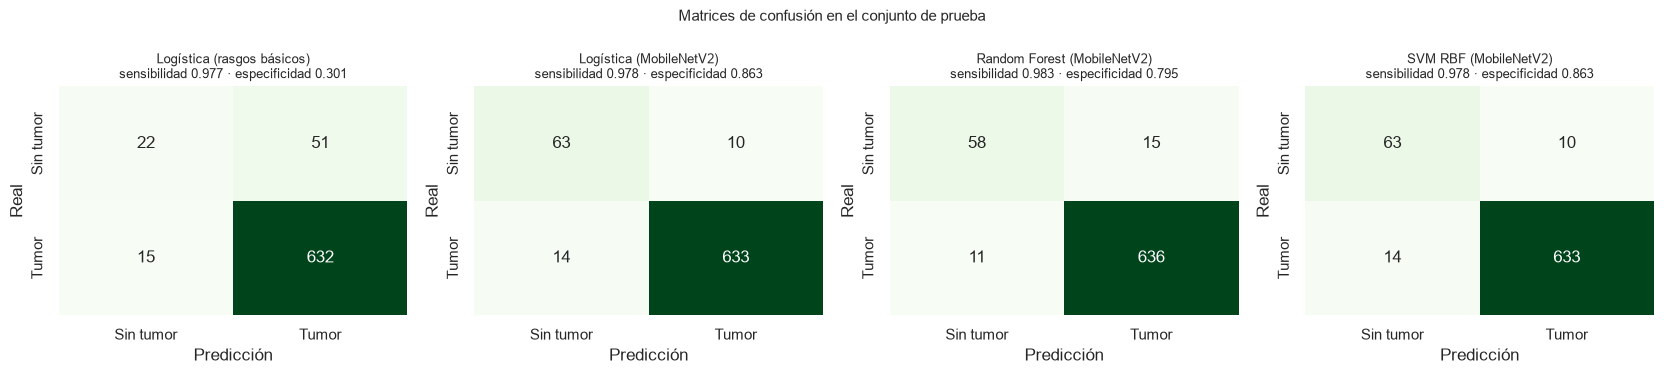

In [29]:
filas_prueba, filas_pred = [], []
for nombre, m in MODELOS.items():
    X_tr, X_te = RASGOS[m["rasgos"]]
    t0 = time.time()
    modelo = clone(m["tuberia"]).fit(X_tr, y_ent)
    joblib.dump(modelo, CARPETA_MODELOS / f"{m['archivo']}.joblib")
    p = modelo.predict_proba(X_te)[:, 1]
    u = umbrales[nombre]
    r = metricas_binarias(y_pru, p, u)
    s_li, s_ls = wilson(r["vp"], r["vp"] + r["fn"])
    e_li, e_ls = wilson(r["vn"], r["vn"] + r["fp"])
    filas_prueba.append({"modelo": nombre, "umbral": u, "n": len(y_pru), **r,
                         "sensibilidad_ic95_inferior": s_li, "sensibilidad_ic95_superior": s_ls,
                         "especificidad_ic95_inferior": e_li, "especificidad_ic95_superior": e_ls,
                         "segundos_entrenamiento": time.time() - t0})
    filas_pred.append(pd.DataFrame({"ruta": man_pru.ruta, "modelo": nombre, "clase": man_pru.clase, "es_tumor": y_pru,
                                    "probabilidad_tumor": p, "umbral": u, "prediccion": (p >= u).astype(int),
                                    "tipo_probable": "", "probabilidad_tipo": np.nan}))

prueba_resumen = pd.DataFrame(filas_prueba)
pred_prueba = pd.concat(filas_pred, ignore_index=True)
prueba_resumen.to_csv(config.RESULTADOS / "prueba_resumen.csv", index=False, encoding="utf-8")
pred_prueba.to_csv(config.RESULTADOS / "predicciones_prueba.csv", index=False, encoding="utf-8")
info_clasicos = {nombre: {"archivo": f"{m['archivo']}.joblib", "rasgos": m["rasgos"], "umbral": umbrales[nombre]} for nombre, m in MODELOS.items()}
info_clasicos["_mejor_por_validacion_cruzada"] = MEJOR_CLASICO
(CARPETA_MODELOS / "info.json").write_text(json.dumps(info_clasicos, ensure_ascii=False, indent=2), encoding="utf-8")

display(prueba_resumen[["modelo", "umbral", "sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud", "vp", "vn", "fp", "fn"]].round(4))
display(prueba_resumen[["modelo", "sensibilidad", "sensibilidad_ic95_inferior", "sensibilidad_ic95_superior",
                        "especificidad", "especificidad_ic95_inferior", "especificidad_ic95_superior"]].round(4))

fig, axs = plt.subplots(1, len(MODELOS), figsize=(4.2 * len(MODELOS), 3.8))
for ax, r in zip(axs, prueba_resumen.itertuples()):
    cm = np.array([[r.vn, r.fp], [r.fn, r.vp]], dtype=int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax, xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
    ax.set_title(f"{r.modelo}\nsensibilidad {r.sensibilidad:.3f} · especificidad {r.especificidad:.3f}", fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión en el conjunto de prueba", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "ml_03_confusion_prueba.png", dpi=130); plt.show()

#### Resumen
La celda arma el resumen con las cifras de esta corrida.

In [30]:
print(f"Validación cruzada de {config.N_PLIEGUES} pliegues sobre {len(y_ent):,} imágenes de entrenamiento; prueba única sobre {len(y_pru):,} imágenes.\n")
for r in prueba_resumen.itertuples():
    c = cv_resumen.set_index("modelo").loc[r.modelo]
    marca = "  ← mejor clásico por validación cruzada" if r.modelo == MEJOR_CLASICO else ""
    print(f"{r.modelo}{marca}\n"
          f"   Validación cruzada: especificidad {c.especificidad_media:.3f} ± {c.especificidad_std:.3f} con sensibilidad {c.sensibilidad_media:.3f} ± {c.sensibilidad_std:.3f}; AUC {c.auc_media:.4f} ± {c.auc_std:.4f}; umbral {r.umbral:.4f}\n"
          f"   Prueba: sensibilidad {r.sensibilidad:.3f} (IC 95 %: {r.sensibilidad_ic95_inferior:.3f} a {r.sensibilidad_ic95_superior:.3f}), "
          f"especificidad {r.especificidad:.3f} (IC 95 %: {r.especificidad_ic95_inferior:.3f} a {r.especificidad_ic95_superior:.3f}), "
          f"AUC {r.auc:.4f}, falsos negativos {r.fn}, falsos positivos {r.fp}")
simple = prueba_resumen.set_index("modelo").loc["Logística (rasgos básicos)"]
print(f"\nLa solución más simple (solo brillo, contraste e histograma) llega a AUC {simple.auc:.3f} en prueba: "
      "esa es la parte del problema que se puede resolver sin mirar la anatomía (ver la advertencia del notebook 01).")
print("\nArchivos en resultados/:")
for f in sorted(config.RESULTADOS.rglob("*")):
    if f.is_file():
        print("  ", f.relative_to(config.RESULTADOS).as_posix())
print(f"\nNotebook terminado en {time.time() - INICIO:.0f} s")

Validación cruzada de 5 pliegues sobre 2,880 imágenes de entrenamiento; prueba única sobre 720 imágenes.

Logística (rasgos básicos)
   Validación cruzada: especificidad 0.269 ± 0.065 con sensibilidad 0.980 ± 0.003; AUC 0.9040 ± 0.0462; umbral 0.0225
   Prueba: sensibilidad 0.977 (IC 95 %: 0.962 a 0.986), especificidad 0.301 (IC 95 %: 0.208 a 0.414), AUC 0.9389, falsos negativos 15, falsos positivos 51
Logística (MobileNetV2)
   Validación cruzada: especificidad 0.884 ± 0.019 con sensibilidad 0.980 ± 0.008; AUC 0.9868 ± 0.0115; umbral 0.6276
   Prueba: sensibilidad 0.978 (IC 95 %: 0.964 a 0.987), especificidad 0.863 (IC 95 %: 0.766 a 0.924), AUC 0.9813, falsos negativos 14, falsos positivos 10
Random Forest (MobileNetV2)
   Validación cruzada: especificidad 0.782 ± 0.036 con sensibilidad 0.980 ± 0.006; AUC 0.9855 ± 0.0057; umbral 0.6367
   Prueba: sensibilidad 0.983 (IC 95 %: 0.970 a 0.990), especificidad 0.795 (IC 95 %: 0.688 a 0.871), AUC 0.9870, falsos negativos 11, falsos positivos

## 3.2 Red neuronal en Keras (Módulo 4)
Transferencia de aprendizaje con MobileNetV2, validación cruzada de 5 pliegues, detención temprana, diagnóstico de convergencia, evaluación única en prueba y comparación contra el mejor modelo clásico.

In [31]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import json
import shutil
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image as Imagen, Markdown, display


from app.backend.ml import config, entrenar, inferencia, rasgos, red
from app.backend.ml.diagnostico import diagnosticar, graficar_curvas
from app.backend.ml.gradcam import mapa_gradcam, superponer
from app.backend.ml.metricas import elegir_umbral, mcnemar, metricas_binarias, metricas_por_pliegue, wilson
from app.backend.ml.preprocesar import cargar_lote, leer_imagen

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
VERSION = "v001"
CARPETA_VERSION = config.MODELOS / VERSION
CARPETA_VERSION.mkdir(parents=True, exist_ok=True)
NOMBRE_RED = "Red Keras (MobileNetV2)"
OBJETIVO = config.SENSIBILIDAD_OBJETIVO

# Hiperparámetros (fijos; no se ajustaron con la prueba)
EPOCAS_CABEZA, PACIENCIA_CABEZA, TASA_CABEZA, LOTE_CABEZA = 60, 8, 1e-3, 64
EPOCAS_AJUSTE, PACIENCIA_AJUSTE, TASA_AJUSTE, LOTE_AJUSTE, CAPAS_AJUSTE = 8, 3, 1e-5, 32, 30
FRACCION_VALIDACION = 0.15
INICIO = time.time()
tiempos = {}
print("Versiones:", config.versiones())

Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


#### Datos

In [32]:
man = pd.read_csv(config.MANIFIESTO)
FIRMA = rasgos.firma_cache(man)
with np.load(config.RASGOS / "rasgos_mobilenet.npz", allow_pickle=False) as d:
    X_todo, rutas_x = d["X"], d["rutas"]
    assert str(d["firma"]) == FIRMA, "Los rasgos guardados son de otro manifiesto o preprocesamiento: ejecute de nuevo el notebook 02."
assert (rutas_x == man.ruta.to_numpy()).all(), "Los rasgos no corresponden al manifiesto: ejecute de nuevo el notebook 02."

ruta_imagenes = config.RASGOS / "imagenes_160.npy"
ruta_firma = config.RASGOS / "imagenes_160.firma.txt"
if ruta_imagenes.exists() and ruta_firma.exists() and ruta_firma.read_text(encoding="utf-8").strip() == FIRMA:
    imagenes = np.load(ruta_imagenes)
else:
    imagenes = cargar_lote([config.RAIZ / r for r in man.ruta], hilos=12)
print("Imágenes preparadas en memoria:", imagenes.shape, imagenes.dtype, f"{imagenes.nbytes / 1e6:.0f} MB")

ent = (man.particion == "entrenamiento").to_numpy()
pru = (man.particion == "prueba").to_numpy()
man_ent, man_pru = man[ent].reset_index(drop=True), man[pru].reset_index(drop=True)
X_ent, img_ent, img_pru = X_todo[ent], imagenes[ent], imagenes[pru]
y_ent, tipo_ent = entrenar.etiquetas_de_clases(man_ent.clase)
y_pru, tipo_pru = entrenar.etiquetas_de_clases(man_pru.clase)
MAYORITARIA = float(max(y_ent.mean(), 1 - y_ent.mean()))
print(f"Entrenamiento: {len(y_ent):,} · Prueba: {len(y_pru):,} · clase mayoritaria (tumor): {MAYORITARIA:.1%}")
print("Pesos de clase:", {k: round(v, 4) for k, v in red.pesos_clase(y_ent).items()})

Imágenes preparadas en memoria: (3600, 160, 160, 3) uint8 276 MB
Entrenamiento: 2,880 · Prueba: 720 · clase mayoritaria (tumor): 89.8%
Pesos de clase: {1: 0.5568, 0: 4.898}


#### Arquitectura

In [33]:
red.construir_cabeza().summary()
_completo = red.construir_completo()
print(f"\nModelo completo: {len(_completo.layers)} capas · {_completo.count_params():,} parámetros")
print("Entrada:", _completo.input.shape, "· salidas:", {k: v.shape for k, v in _completo.output.items()})
print("Capa para Grad-CAM:", red.NOMBRE_CAPA_GRADCAM, _completo.get_layer(red.NOMBRE_CAPA_GRADCAM).output.shape)
del _completo

Model: "cabeza"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rasgos (InputLayer) │ (None, 1280)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densa (Dense)       │ (None, 256)       │    327,936 │ rasgos[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ densa[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tumor_logit (Dense) │ (None, 1)         │        257 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tipo (Dense)        │ (None, 3)         │        771 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tumor (Activation)  │ (None, 1)         │          0 │ tumor_logit[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 328,964 (1.25 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 0 (0.00 B)


Modelo completo: 161 capas · 2,586,948 parámetros
Entrada: (None, 160, 160, 3) · salidas: {'tumor': (None, 1), 'tipo': (None, 3)}
Capa para Grad-CAM: out_relu (None, 5, 5, 1280)


#### Validación cruzada de la cabeza (5 pliegues)
Mismos pliegues que el notebook 03 (por grupos de similitud, columna `pliegue` del manifiesto). En cada pliegue, del bloque de entrenamiento se aparta una parte (1 de 7, por grupos) para la detención temprana; el bloque fuera de pliegue no participa en el entrenamiento ni en la detención: solo recibe predicciones.

In [34]:
t0 = time.time()
GRUPOS_ENT = man_ent.grupo_similitud.to_numpy()
assert not set(GRUPOS_ENT) & set(man_pru.grupo_similitud), "Hay grupos de similitud repartidos entre entrenamiento y prueba."
cv = entrenar.kfold_cabeza(X_ent, y_ent, tipo_ent, estratos=man_ent.clase.to_numpy(), grupos=GRUPOS_ENT, n_pliegues=config.N_PLIEGUES,
                           fraccion_val=FRACCION_VALIDACION, epocas_max=EPOCAS_CABEZA, tasa=TASA_CABEZA,
                           lote=LOTE_CABEZA, paciencia=PACIENCIA_CABEZA, semilla=config.SEMILLA)
tiempos["kfold_cabeza_s"] = time.time() - t0
prob_oof, pliegue_de = cv["prob_oof"], cv["pliegue_oof"]
assert not np.isnan(prob_oof).any()

# Comprobación: son exactamente los pliegues del notebook 03
oof_previas = pd.read_csv(config.RESULTADOS / "predicciones_oof.csv")
oof_previas = oof_previas[oof_previas.modelo != NOMBRE_RED]
referencia = oof_previas[oof_previas.modelo == oof_previas.modelo.iloc[0]].set_index("ruta").loc[man_ent.ruta, "pliegue"].to_numpy()
assert (referencia == pliegue_de).all() and (man_ent.pliegue.to_numpy() == pliegue_de).all(), "Los pliegues no coinciden con los del notebook 03 y el manifiesto."
print(f"Pliegues idénticos a los del notebook 03. Validación cruzada en {tiempos['kfold_cabeza_s']:.0f} s")

umbral_cv = elegir_umbral(y_ent, prob_oof, OBJETIVO)
METRICAS = ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]
por_pliegue = pd.DataFrame(metricas_por_pliegue(y_ent, prob_oof, pliegue_de, umbral_cv))
en_05 = pd.DataFrame(cv["pliegues"])
por_pliegue["sensibilidad_umbral_05"], por_pliegue["especificidad_umbral_05"] = en_05.sensibilidad, en_05.especificidad
por_pliegue.insert(0, "modelo", NOMBRE_RED)
display(por_pliegue.round(4))
display(en_05[["pliegue", "mejor_epoca", "epocas", "exactitud_tipo"]].round(4))

NOTA_RED = "K-fold sobre la cabeza con rasgos congelados; el ajuste fino se entrenó una sola vez"
total = metricas_binarias(y_ent, prob_oof, umbral_cv)
fila_cv = {"modelo": NOMBRE_RED, "umbral": umbral_cv}
for met in METRICAS:
    fila_cv[f"{met}_media"], fila_cv[f"{met}_std"] = por_pliegue[met].mean(), por_pliegue[met].std(ddof=1)
fila_cv.update({"sensibilidad_oof": total["sensibilidad"], "especificidad_oof": total["especificidad"], "auc_oof": total["auc"],
                "vp": total["vp"], "vn": total["vn"], "fp": total["fp"], "fn": total["fn"],
                "segundos_cv": tiempos["kfold_cabeza_s"], "nota": NOTA_RED})


def agregar(archivo, nuevas):
    """Añade las filas de la red al CSV (quita antes las de una corrida anterior de este notebook)."""
    ruta = config.RESULTADOS / archivo
    previas = pd.read_csv(ruta)
    previas = previas[previas.modelo != NOMBRE_RED]
    junto = pd.concat([previas, nuevas], ignore_index=True)
    junto.to_csv(ruta, index=False, encoding="utf-8")
    return junto


cv_pliegues = agregar("cv_pliegues.csv", por_pliegue)
cv_resumen = agregar("cv_resumen.csv", pd.DataFrame([fila_cv]))
agregar("predicciones_oof.csv", pd.DataFrame({
    "ruta": man_ent.ruta, "modelo": NOMBRE_RED, "pliegue": pliegue_de, "clase": man_ent.clase, "es_tumor": y_ent,
    "probabilidad_tumor": prob_oof, "umbral": umbral_cv, "prediccion": (prob_oof >= umbral_cv).astype(int)}))
print(f"Cabeza en validación cruzada · umbral {umbral_cv:.4f} · "
      + " · ".join(f"{m} {fila_cv[m + '_media']:.4f} ± {fila_cv[m + '_std']:.4f}" for m in METRICAS[:5]))
print(f"Exactitud del tipo de tumor (solo casos de tumor), media de pliegues: {en_05.exactitud_tipo.mean():.4f}")

Pliegues idénticos a los del notebook 03. Validación cruzada en 36 s


,modelo,pliegue,umbral,vp,vn,fp,fn,sensibilidad,especificidad,precision,f1,exactitud,auc,sensibilidad_umbral_05,especificidad_umbral_05
0,Red Keras (MobileNetV2),1,0.5205,511,53,6,6,0.9884,0.8983,0.9884,0.9884,0.9792,0.9802,0.9884,0.8983
1,Red Keras (MobileNetV2),2,0.5205,504,51,8,13,0.9749,0.8644,0.9844,0.9796,0.9635,0.9759,0.9749,0.8475
2,Red Keras (MobileNetV2),3,0.5205,506,53,5,12,0.9768,0.9138,0.9902,0.9835,0.9705,0.9871,0.9768,0.9138
3,Red Keras (MobileNetV2),4,0.5205,503,56,3,14,0.9729,0.9492,0.9941,0.9834,0.9705,0.9922,0.9749,0.9492
4,Red Keras (MobileNetV2),5,0.5205,511,53,6,6,0.9884,0.8983,0.9884,0.9884,0.9792,0.9925,0.9884,0.8983


,pliegue,mejor_epoca,epocas,exactitud_tipo
0,1,17,25,0.8897
1,2,5,13,0.8491
2,3,8,16,0.8668
3,4,5,13,0.8839
4,5,4,12,0.8569


Cabeza en validación cruzada · umbral 0.5205 · sensibilidad 0.9803 ± 0.0075 · especificidad 0.9048 ± 0.0307 · precision 0.9891 ± 0.0035 · f1 0.9846 ± 0.0038 · auc 0.9856 ± 0.0074
Exactitud del tipo de tumor (solo casos de tumor), media de pliegues: 0.8693


#### Modelo final
##### Validación apartada y entrenamiento de la cabeza
Se aparta una de 7 partes del entrenamiento (cerca de 15 %; estratificada por las 4 clases, **por grupos de similitud**, semilla 42) como validación. Ningún grupo queda repartido entre esa validación y su entrenamiento. La prueba sigue sin tocarse.

In [35]:
indices = np.arange(len(man_ent))
i_tr, i_va = entrenar.apartar_validacion(man_ent.clase.to_numpy(), FRACCION_VALIDACION, config.SEMILLA, GRUPOS_ENT)
assert not set(GRUPOS_ENT[i_tr]) & set(GRUPOS_ENT[i_va])
print(f"Entrenamiento del modelo final: {len(i_tr):,} · validación: {len(i_va):,}")


def avisar(etapa, epoca, r):
    print(f"[{etapa}] época {epoca:2d} · pérdida {r['loss']:.4f} · exactitud {r['accuracy']:.4f} · "
          f"pérdida val {r['val_loss']:.4f} · exactitud val {r['val_accuracy']:.4f} · tasa {r['learning_rate']:.2e}")


t0 = time.time()
cabeza, hist_cabeza = entrenar.entrenar_cabeza(
    X_ent[i_tr], y_ent[i_tr], tipo_ent[i_tr], X_ent[i_va], y_ent[i_va], tipo_ent[i_va],
    epocas_max=EPOCAS_CABEZA, tasa=TASA_CABEZA, lote=LOTE_CABEZA, paciencia=PACIENCIA_CABEZA,
    callback_progreso=avisar, semilla=config.SEMILLA)
tiempos["cabeza_s"] = time.time() - t0
diag_cabeza = diagnosticar(hist_cabeza, EPOCAS_CABEZA, PACIENCIA_CABEZA, MAYORITARIA)
p_va_cabeza, _ = entrenar.predecir_cabeza(cabeza, X_ent[i_va])
print(f"\nCabeza entrenada en {tiempos['cabeza_s']:.0f} s · diagnóstico: {diag_cabeza['etiqueta']} · mejor época: {diag_cabeza['mejor_epoca']}")

Entrenamiento del modelo final: 2,468 · validación: 412


[cabeza] época  1 · pérdida 0.8139 · exactitud 0.8468 · pérdida val 0.4094 · exactitud val 0.9684 · tasa 1.00e-03


[cabeza] época  2 · pérdida 0.3465 · exactitud 0.9562 · pérdida val 0.3616 · exactitud val 0.9709 · tasa 1.00e-03


[cabeza] época  3 · pérdida 0.2670 · exactitud 0.9660 · pérdida val 0.3496 · exactitud val 0.9684 · tasa 1.00e-03


[cabeza] época  4 · pérdida 0.2154 · exactitud 0.9745 · pérdida val 0.3572 · exactitud val 0.9757 · tasa 1.00e-03


[cabeza] época  5 · pérdida 0.1815 · exactitud 0.9801 · pérdida val 0.3519 · exactitud val 0.9757 · tasa 1.00e-03


... (9 outputs left out)

[cabeza] época 16 · pérdida 0.0701 · exactitud 0.9931 · pérdida val 0.3505 · exactitud val 0.9757 · tasa 3.00e-04


[cabeza] época 17 · pérdida 0.0614 · exactitud 0.9947 · pérdida val 0.3584 · exactitud val 0.9806 · tasa 9.00e-05
[cabeza] época 18 · pérdida 0.0608 · exactitud 0.9943 · pérdida val 0.3589 · exactitud val 0.9806 · tasa 9.00e-05


[cabeza] época 19 · pérdida 0.0593 · exactitud 0.9968 · pérdida val 0.3604 · exactitud val 0.9806 · tasa 9.00e-05


[cabeza] época 20 · pérdida 0.0581 · exactitud 0.9959 · pérdida val 0.3591 · exactitud val 0.9806 · tasa 9.00e-05

Cabeza entrenada en 9 s · diagnóstico: convergió · mejor época: 12


##### Modelo completo y ajuste fino (una sola vez)
Se arma el modelo completo (imagen → MobileNetV2 → cabeza) con los pesos de la cabeza recién entrenada. Después se descongelan las últimas capas de MobileNetV2 (las de normalización por lotes se quedan congeladas) y se entrena con una tasa de aprendizaje muy baja y aumento ligero de datos (espejo, giro, zoom, desplazamiento y brillo leves).

In [36]:
completo = red.construir_completo(cabeza=cabeza)
p_va_antes, _ = entrenar.predecir_completo(completo, img_ent[i_va])
print(f"Comprobación: diferencia máxima entre la cabeza sobre rasgos guardados y el modelo completo sobre imágenes = {np.abs(p_va_antes - p_va_cabeza).max():.2e}")

t0 = time.time()
completo, hist_ajuste = entrenar.ajuste_fino(
    completo, img_ent[i_tr], y_ent[i_tr], tipo_ent[i_tr], img_ent[i_va], y_ent[i_va], tipo_ent[i_va],
    capas=CAPAS_AJUSTE, tasa=TASA_AJUSTE, epocas_max=EPOCAS_AJUSTE, lote=LOTE_AJUSTE, paciencia=PACIENCIA_AJUSTE,
    aumento=True, callback_progreso=avisar, semilla=config.SEMILLA)
tiempos["ajuste_fino_s"] = time.time() - t0
diag_ajuste = diagnosticar(hist_ajuste, EPOCAS_AJUSTE, PACIENCIA_AJUSTE, MAYORITARIA)
p_va_ajuste, _ = entrenar.predecir_completo(completo, img_ent[i_va])
print(f"\nAjuste fino en {tiempos['ajuste_fino_s'] / 60:.1f} min · capas descongeladas: {hist_ajuste['capas_descongeladas']} "
      f"· diagnóstico: {diag_ajuste['etiqueta']} · mejor época: {diag_ajuste['mejor_epoca']}")

Comprobación: diferencia máxima entre la cabeza sobre rasgos guardados y el modelo completo sobre imágenes = 5.96e-08


[ajuste_fino] época  1 · pérdida 0.2108 · exactitud 0.9688 · pérdida val 0.4028 · exactitud val 0.9757 · tasa 1.00e-05


[ajuste_fino] época  2 · pérdida 0.1731 · exactitud 0.9793 · pérdida val 0.4098 · exactitud val 0.9806 · tasa 1.00e-05


[ajuste_fino] época  3 · pérdida 0.1493 · exactitud 0.9826 · pérdida val 0.3992 · exactitud val 0.9782 · tasa 3.00e-06


[ajuste_fino] época  4 · pérdida 0.1437 · exactitud 0.9854 · pérdida val 0.4114 · exactitud val 0.9806 · tasa 3.00e-06


[ajuste_fino] época  5 · pérdida 0.1395 · exactitud 0.9866 · pérdida val 0.4001 · exactitud val 0.9806 · tasa 9.00e-07


[ajuste_fino] época  6 · pérdida 0.1562 · exactitud 0.9826 · pérdida val 0.3956 · exactitud val 0.9806 · tasa 2.70e-07


[ajuste_fino] época  7 · pérdida 0.1421 · exactitud 0.9806 · pérdida val 0.3997 · exactitud val 0.9806 · tasa 2.70e-07


[ajuste_fino] época  8 · pérdida 0.1311 · exactitud 0.9862 · pérdida val 0.4009 · exactitud val 0.9806 · tasa 1.00e-07



Ajuste fino en 5.6 min · capas descongeladas: 19 · diagnóstico: convergió · mejor época: 6


##### Historial por época

In [37]:
partes = []
for etapa, h in [("cabeza", hist_cabeza), ("ajuste_fino", hist_ajuste)]:
    partes.append(pd.DataFrame({"etapa": etapa, "epoca": range(1, len(h["loss"]) + 1), "perdida": h["loss"],
                                "exactitud": h["accuracy"], "perdida_val": h["val_loss"],
                                "exactitud_val": h["val_accuracy"], "tasa_aprendizaje": h["learning_rate"]}))
historial = pd.concat(partes, ignore_index=True)
historial.to_csv(config.RESULTADOS / "historial_epocas.csv", index=False, encoding="utf-8")
pd.set_option("display.max_rows", 100)
display(historial.round(6))

,etapa,epoca,perdida,exactitud,perdida_val,exactitud_val,tasa_aprendizaje
0,cabeza,1,0.813884,0.846840,0.409364,0.968447,0.001000
1,cabeza,2,0.346503,0.956240,0.361613,0.970874,0.001000
2,cabeza,3,0.267001,0.965964,0.349607,0.968447,0.001000
3,cabeza,4,0.215449,0.974473,0.357153,0.975728,0.001000
4,cabeza,5,0.181494,0.980146,0.351861,0.975728,0.001000
5,cabeza,6,0.155346,0.982577,0.363920,0.978155,0.001000
6,cabeza,7,0.138271,0.983793,0.377276,0.978155,0.001000
7,cabeza,8,0.117118,0.989870,0.347404,0.973301,0.000300
8,cabeza,9,0.108636,0.990681,0.343230,0.973301,0.000300
9,cabeza,10,0.102103,0.988655,0.343287,0.970874,0.000300


##### Curvas y diagnóstico de convergencia
La línea punteada marca la **mejor época**: la de menor pérdida de validación. Los pesos que se conservan son los de esa época.

**Trabajo futuro (no se cambió ahora):** los callbacks vigilan la pérdida total (`tumor` + 0.5 × `tipo`). Vigilar solo la pérdida de la salida `tumor` podría elegir una época mejor para la decisión principal; habría que evaluarlo con una división nueva, porque cambiarlo después de ver la prueba sería elegir con ella.

**Es un mínimo de la pérdida de validación observado en esta corrida, no un mínimo global.** El entrenamiento de una red encuentra un punto bueno, no el mejor posible: con otra semilla, otra tasa de aprendizaje u otra división de validación el resultado puede cambiar un poco.

El diagnóstico automático (`app/backend/ml/diagnostico.py`) aplica reglas explícitas y devuelve una de cuatro etiquetas: "convergió", "se detuvo antes de converger", "sobreajuste" o "no aprende" (y "cancelado" si el entrenamiento se interrumpe). Además agrega **advertencias** en palabras simples: si el entrenamiento no mejoró el modelo de partida (puede pasar en el ajuste fino) y si hay señales de memorización (la pérdida de entrenamiento queda muy por debajo de la de validación).

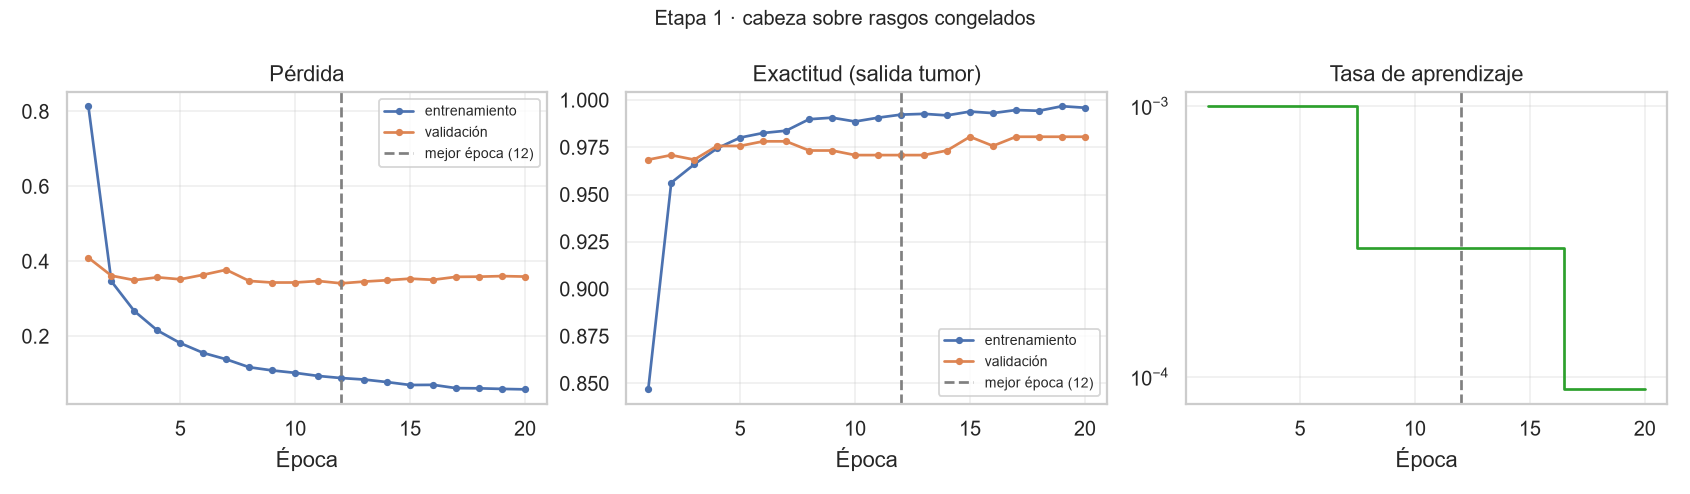

Cabeza → CONVERGIÓ (mejor época: 12 de 20 corridas)
   La pérdida de validación llegó a su mínimo en la época 12 (0.3411) y la detención temprana actuó en la época 20 de 60 tras 8 épocas sin mejorar. Se conservan los pesos de esa época. Es un mínimo de la pérdida de validación, no una garantía de mínimo global.
   Advertencias: 0
   Matiz: en la mejor época la pérdida de entrenamiento fue 0.26 veces la de validación (la advertencia de memorización salta por debajo de 0.25) y la exactitud de entrenamiento fue 0.992 (la advertencia salta desde 0.995). Quedó cerca de esos límites: el 'convergió' es sin advertencia, pero por poco.



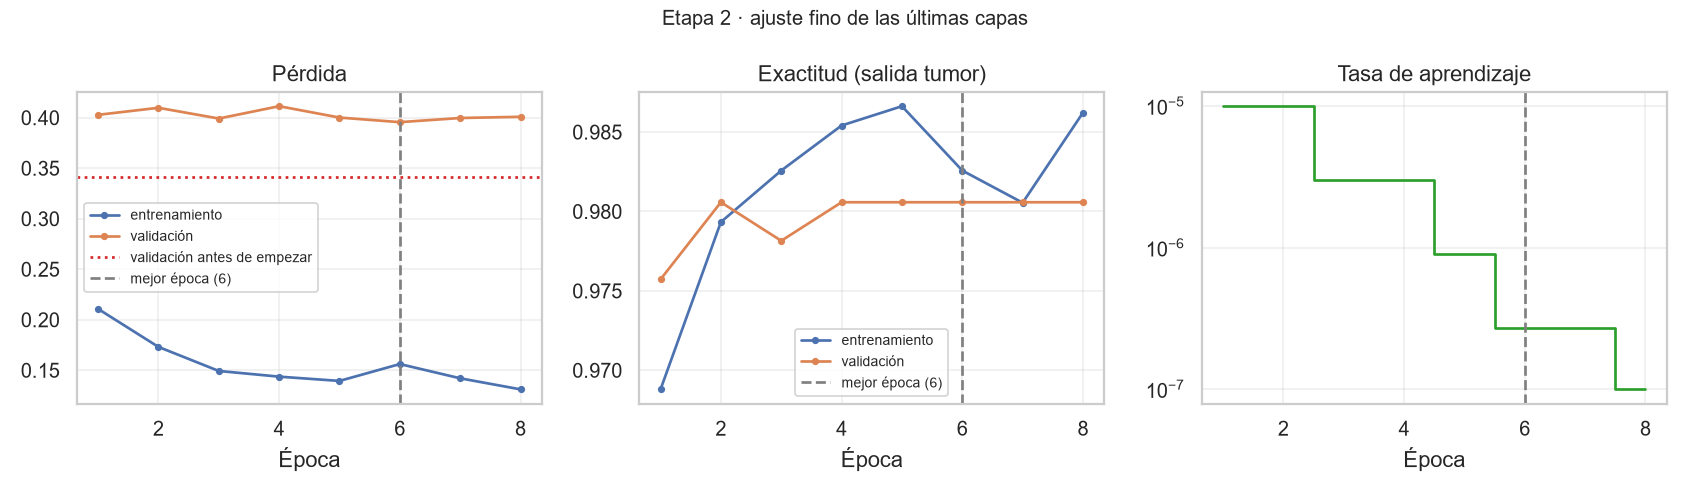

Ajuste fino → CONVERGIÓ (mejor época: 6 de 8 corridas)
   El entrenamiento no mejoró el modelo de partida: la pérdida de validación antes de empezar era 0.3411 y la mejor que se logró fue 0.3956 (época 6). Conviene quedarse con el modelo de partida. La pérdida de validación llegó a su mínimo en la época 6 (0.3956) y la pérdida de validación se aplanó antes de terminar las 8 épocas. Se conservan los pesos de esa época. Es un mínimo de la pérdida de validación, no una garantía de mínimo global.
   Advertencias: 1



In [38]:
curva_cabeza = graficar_curvas(hist_cabeza, diag_cabeza["mejor_epoca"], FIGURAS / "red_curvas_cabeza.png", "Etapa 1 · cabeza sobre rasgos congelados")
curva_ajuste = graficar_curvas(hist_ajuste, diag_ajuste["mejor_epoca"], FIGURAS / "red_curvas_ajuste_fino.png", "Etapa 2 · ajuste fino de las últimas capas")
for nombre, curva, diag in [("Cabeza", curva_cabeza, diag_cabeza), ("Ajuste fino", curva_ajuste, diag_ajuste)]:
    display(Imagen(filename=curva))
    print(f"{nombre} → {diag['etiqueta'].upper()} (mejor época: {diag['mejor_epoca']} de {diag['epocas_corridas']} corridas)")
    print("  ", diag["explicacion"])
    print("   Advertencias:", len(diag["advertencias"]))
    if diag["etiqueta"] == "convergió" and not diag["advertencias"]:
        from app.backend.ml import diagnostico as _dg
        _h = hist_cabeza if nombre == "Cabeza" else hist_ajuste
        _k = diag["mejor_epoca"] - 1
        _razon, _exa = _h["loss"][_k] / _h["val_loss"][_k], _h["accuracy"][_k]
        if _razon < _dg.RAZON_MEMORIZACION + 0.10 or _exa >= _dg.EXACTITUD_MEMORIZACION - 0.01:
            print(f"   Matiz: en la mejor época la pérdida de entrenamiento fue {_razon:.2f} veces la de validación (la advertencia de memorización "
                  f"salta por debajo de {_dg.RAZON_MEMORIZACION}) y la exactitud de entrenamiento fue {_exa:.3f} (la advertencia salta desde {_dg.EXACTITUD_MEMORIZACION}). "
                  "Quedó cerca de esos límites: el 'convergió' es sin advertencia, pero por poco.")
    print()

##### ¿Cabeza sola o modelo con ajuste fino?
Se comparan en la **misma validación** y con la **misma pérdida** (`val_loss`). Se exporta el que tenga menor pérdida de validación. Si el ajuste fino no mejora, se exporta la cabeza sola (dentro del modelo completo) y se dice tal cual. La prueba no interviene en esta decisión.

In [39]:
y_va = y_ent[i_va]
val_cabeza, val_ajuste = float(hist_ajuste["val_loss_inicial"]), float(min(hist_ajuste["val_loss"]))
comparacion = []
for nombre, p, perdida in [("cabeza sola", p_va_antes, val_cabeza), ("con ajuste fino", p_va_ajuste, val_ajuste)]:
    u = elegir_umbral(y_va, p, OBJETIVO)
    comparacion.append({"variante": nombre, "perdida_val": perdida, "umbral_sens_098": u, **metricas_binarias(y_va, p, u)})
comparacion = pd.DataFrame(comparacion)
display(comparacion[["variante", "perdida_val", "umbral_sens_098", "sensibilidad", "especificidad", "auc", "fn", "fp"]].round(4))

USAR_AJUSTE = val_ajuste < val_cabeza
if USAR_AJUSTE:
    modelo_final, ETAPA, p_va_final, diag_final = completo, "ajuste_fino", p_va_ajuste, diag_ajuste
    print(f"El ajuste fino MEJORÓ la pérdida de validación ({val_cabeza:.4f} → {val_ajuste:.4f}). Se exporta el modelo con ajuste fino.")
else:
    modelo_final, ETAPA, p_va_final, diag_final = red.construir_completo(cabeza=cabeza), "cabeza", p_va_antes, diag_cabeza
    print(f"El ajuste fino NO mejoró la pérdida de validación ({val_cabeza:.4f} → {val_ajuste:.4f}). Se exporta la cabeza sola (MobileNetV2 congelada).")

,variante,perdida_val,umbral_sens_098,sensibilidad,especificidad,auc,fn,fp
0,cabeza sola,0.3411,0.4319,0.9811,0.9286,0.9741,7,3
1,con ajuste fino,0.3956,0.6712,0.9811,0.9286,0.9777,7,3


El ajuste fino NO mejoró la pérdida de validación (0.3411 → 0.3956). Se exporta la cabeza sola (MobileNetV2 congelada).


#### Umbral de decisión
El umbral es el más alto con sensibilidad ≥ 0.98 (con un pequeño margen para que ninguna imagen quede justo encima). El valor que se guarda es el **punto medio** entre la probabilidad límite que da sensibilidad ≥ 0.98 y la siguiente probabilidad más baja. **Con qué datos se elige** depende de lo que se exporta.

**Nota de honestidad sobre esta regla:** se adoptó **después** de haber visto resultados de prueba de una división anterior de los datos (en la primera entrega el umbral salía de la validación apartada). Con la división actual el código **no usa la prueba** para elegir el umbral ni ninguna otra cosa, y la regla no se volvió a cambiar. La regla es:

- **Si se exporta la cabeza sola:** con las **predicciones fuera de pliegue** de la validación cruzada de la cabeza (todo el entrenamiento). Son la misma arquitectura y la misma receta de entrenamiento, cada predicción viene de un modelo que **no vio** esa imagen, y son varias veces más casos que la validación apartada. La validación apartada, en cambio, es pequeña y ya se usó para la detención temprana, así que un umbral elegido ahí sería optimista e inestable.
- **Si se exporta el modelo con ajuste fino:** con la **validación apartada**, porque del ajuste fino no existen predicciones fuera de pliegue (se entrenó una sola vez).

Limitación: las predicciones fuera de pliegue vienen de 5 modelos hermanos, no del modelo exportado; su calibración puede diferir un poco. La validación apartada se usa abajo como comprobación, y la prueba mide el resultado final.

Umbral elegido: 0.520507 · origen: predicciones fuera de pliegue de la validación cruzada de la cabeza (2880 imágenes de entrenamiento)
En los datos donde se eligió: {'vp': 2535, 'vn': 266, 'fp': 28, 'fn': 51, 'sensibilidad': 0.9803, 'especificidad': 0.9048, 'precision': 0.9891, 'f1': 0.9847, 'exactitud': 0.9726, 'auc': 0.9844}
Comprobación en la validación apartada del modelo exportado: {'vp': 361, 'vn': 39, 'fp': 3, 'fn': 9, 'sensibilidad': 0.9757, 'especificidad': 0.9286, 'precision': 0.9918, 'f1': 0.9837, 'exactitud': 0.9709, 'auc': 0.9741}
(Como referencia: el umbral que saldría solo de la validación apartada sería 0.431893)


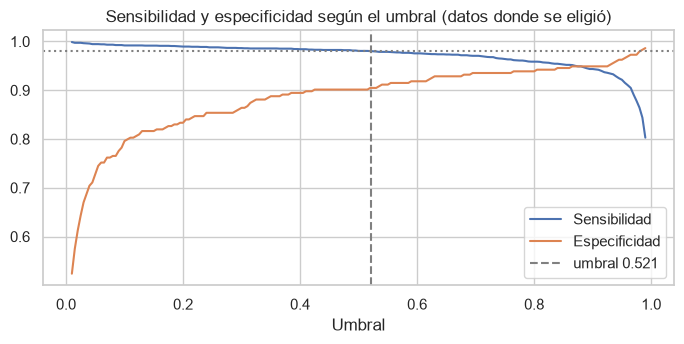

In [40]:
if USAR_AJUSTE:
    y_umbral, p_umbral = y_va, p_va_final
    ORIGEN_UMBRAL = f"validación apartada por grupos ({len(i_va)} imágenes) del modelo con ajuste fino"
else:
    y_umbral, p_umbral = y_ent, prob_oof
    ORIGEN_UMBRAL = f"predicciones fuera de pliegue de la validación cruzada de la cabeza ({len(y_ent)} imágenes de entrenamiento)"
UMBRAL = elegir_umbral(y_umbral, p_umbral, OBJETIVO)
m_umbral = metricas_binarias(y_umbral, p_umbral, UMBRAL)
m_val = metricas_binarias(y_va, p_va_final, UMBRAL)
print(f"Umbral elegido: {UMBRAL:.6f} · origen: {ORIGEN_UMBRAL}")
print("En los datos donde se eligió:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_umbral.items()})
print("Comprobación en la validación apartada del modelo exportado:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_val.items()})
print(f"(Como referencia: el umbral que saldría solo de la validación apartada sería {elegir_umbral(y_va, p_va_final, OBJETIVO):.6f})")

umbrales = np.linspace(0.01, 0.99, 197)
sens = [metricas_binarias(y_umbral, p_umbral, u)["sensibilidad"] for u in umbrales]
espe = [metricas_binarias(y_umbral, p_umbral, u)["especificidad"] for u in umbrales]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(umbrales, sens, label="Sensibilidad"); ax.plot(umbrales, espe, label="Especificidad")
ax.axvline(UMBRAL, ls="--", color="gray", label=f"umbral {UMBRAL:.3f}"); ax.axhline(OBJETIVO, ls=":", color="gray")
ax.set_xlabel("Umbral"); ax.set_title("Sensibilidad y especificidad según el umbral (datos donde se eligió)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURAS / "red_umbral.png", dpi=130); plt.show()

#### Evaluación única en el conjunto de prueba
El modelo, el umbral y la decisión cabeza / ajuste fino ya están fijos. Ahora, y solo ahora, se usa la prueba.

Prueba (720 imágenes) · modelo exportado: cabeza · umbral 0.5205
  Sensibilidad  0.9675  (IC 95 % de Wilson: 0.9509 a 0.9787) · falsos negativos: 21
  Especificidad 0.8904  (IC 95 % de Wilson: 0.7984 a 0.9434) · falsos positivos: 8
  Precisión 0.9874 · F1 0.9774 · AUC 0.9825 · exactitud 0.9597
  Dato secundario · exactitud del tipo de tumor en los casos con tumor: 0.8779


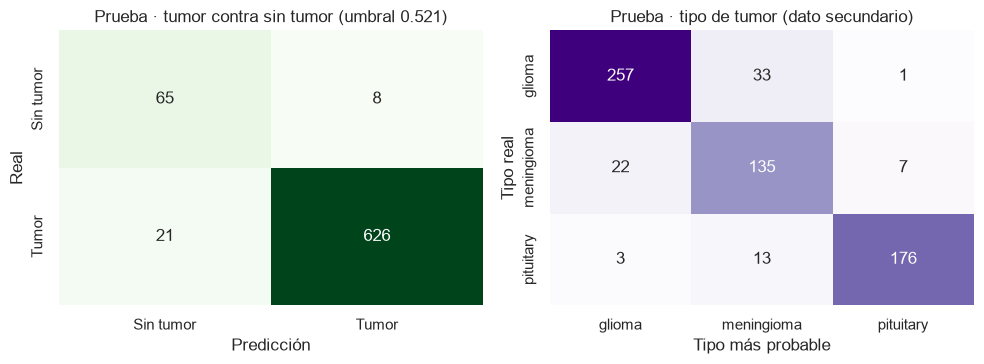

In [41]:
t0 = time.time()
p_pru, p_tipo_pru = entrenar.predecir_completo(modelo_final, img_pru)
tiempos["prediccion_prueba_s"] = time.time() - t0
m_pru = metricas_binarias(y_pru, p_pru, UMBRAL)
s_li, s_ls = wilson(m_pru["vp"], m_pru["vp"] + m_pru["fn"])
e_li, e_ls = wilson(m_pru["vn"], m_pru["vn"] + m_pru["fp"])
con_tumor = tipo_pru >= 0
exactitud_tipo = float((p_tipo_pru[con_tumor].argmax(1) == tipo_pru[con_tumor]).mean())

fila_prueba = {"modelo": NOMBRE_RED, "umbral": UMBRAL, "n": len(y_pru), **m_pru,
               "sensibilidad_ic95_inferior": s_li, "sensibilidad_ic95_superior": s_ls,
               "especificidad_ic95_inferior": e_li, "especificidad_ic95_superior": e_ls,
               "segundos_entrenamiento": tiempos["cabeza_s"] + tiempos["ajuste_fino_s"]}
prueba_resumen = agregar("prueba_resumen.csv", pd.DataFrame([fila_prueba]))
tipos_pred = [config.TIPOS_TUMOR[k] for k in p_tipo_pru.argmax(1)]
pred_prueba = agregar("predicciones_prueba.csv", pd.DataFrame({
    "ruta": man_pru.ruta, "modelo": NOMBRE_RED, "clase": man_pru.clase, "es_tumor": y_pru, "probabilidad_tumor": p_pru,
    "umbral": UMBRAL, "prediccion": (p_pru >= UMBRAL).astype(int), "tipo_probable": tipos_pred,
    "probabilidad_tipo": p_tipo_pru.max(1)}))

print(f"Prueba ({len(y_pru):,} imágenes) · modelo exportado: {ETAPA} · umbral {UMBRAL:.4f}")
print(f"  Sensibilidad  {m_pru['sensibilidad']:.4f}  (IC 95 % de Wilson: {s_li:.4f} a {s_ls:.4f}) · falsos negativos: {m_pru['fn']}")
print(f"  Especificidad {m_pru['especificidad']:.4f}  (IC 95 % de Wilson: {e_li:.4f} a {e_ls:.4f}) · falsos positivos: {m_pru['fp']}")
print(f"  Precisión {m_pru['precision']:.4f} · F1 {m_pru['f1']:.4f} · AUC {m_pru['auc']:.4f} · exactitud {m_pru['exactitud']:.4f}")
print(f"  Dato secundario · exactitud del tipo de tumor en los casos con tumor: {exactitud_tipo:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
cm = np.array([[m_pru["vn"], m_pru["fp"]], [m_pru["fn"], m_pru["vp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axs[0], xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
axs[0].set_title(f"Prueba · tumor contra sin tumor (umbral {UMBRAL:.3f})"); axs[0].set_xlabel("Predicción"); axs[0].set_ylabel("Real")
cm_tipo = pd.crosstab(pd.Series(man_pru.clase[con_tumor].to_numpy(), name="Tipo real"), pd.Series(np.array(tipos_pred)[con_tumor], name="Tipo más probable")).reindex(index=config.TIPOS_TUMOR, columns=config.TIPOS_TUMOR, fill_value=0)
sns.heatmap(cm_tipo, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axs[1]); axs[1].set_title("Prueba · tipo de tumor (dato secundario)")
plt.tight_layout(); plt.savefig(FIGURAS / "red_confusion_prueba.png", dpi=130); plt.show()

#### Tabla comparativa final de los 5 modelos
- **Validación cruzada:** media ± desviación estándar de los 5 pliegues, al umbral elegido con las predicciones fuera de pliegue (por eso la sensibilidad queda cerca de 0.98 en todos; lo que cambia es la especificidad y el AUC).
- **Prueba:** una sola evaluación por modelo, con el umbral ya fijado.
- **Red Keras:** la validación cruzada es de la **cabeza con rasgos congelados**; la columna de prueba es del modelo exportado. El ajuste fino se entrenó **una sola vez**.

In [42]:
cvr, prr = cv_resumen.set_index("modelo"), prueba_resumen.set_index("modelo")
ORDEN = [m for m in cvr.index if m != NOMBRE_RED] + [NOMBRE_RED]
filas = []
for m in ORDEN:
    c, p = cvr.loc[m], prr.loc[m]
    fila = {"modelo": m, "umbral_cv": c.umbral}
    for met in ["sensibilidad", "especificidad", "precision", "f1", "auc"]:
        fila[f"cv_{met}_media"], fila[f"cv_{met}_std"] = c[f"{met}_media"], c[f"{met}_std"]
    fila["umbral_prueba"] = p.umbral
    for met in ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]:
        fila[f"prueba_{met}"] = p[met]
    for col in ["sensibilidad_ic95_inferior", "sensibilidad_ic95_superior", "especificidad_ic95_inferior", "especificidad_ic95_superior"]:
        fila[f"prueba_{col}"] = p[col]
    fila.update({"prueba_vp": int(p.vp), "prueba_vn": int(p.vn), "prueba_fp": int(p.fp), "prueba_fn": int(p.fn), "nota": c.nota})
    if m == NOMBRE_RED:
        fila["nota"] = (f"{NOTA_RED}. Prueba: modelo exportado = "
                        + ("con ajuste fino" if USAR_AJUSTE else "cabeza sola (el ajuste fino no mejoró la validación)")
                        + "; su umbral se eligió con: " + ORIGEN_UMBRAL)
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla.to_csv(config.RESULTADOS / "tabla_comparativa.csv", index=False, encoding="utf-8")

vista = pd.DataFrame({"Modelo": tabla.modelo})
for met, nombre in [("sensibilidad", "Sensibilidad"), ("especificidad", "Especificidad"), ("precision", "Precisión"), ("f1", "F1"), ("auc", "AUC")]:
    vista[f"CV {nombre}"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(tabla[f"cv_{met}_media"], tabla[f"cv_{met}_std"])]
vista["Umbral"] = [f"{u:.4f}" for u in tabla.umbral_prueba]
vista["Prueba Sensibilidad (IC 95 %)"] = [f"{s:.4f} ({a:.3f} a {b:.3f})" for s, a, b in zip(tabla.prueba_sensibilidad, tabla.prueba_sensibilidad_ic95_inferior, tabla.prueba_sensibilidad_ic95_superior)]
vista["Prueba Especificidad (IC 95 %)"] = [f"{s:.4f} ({a:.3f} a {b:.3f})" for s, a, b in zip(tabla.prueba_especificidad, tabla.prueba_especificidad_ic95_inferior, tabla.prueba_especificidad_ic95_superior)]
for met, nombre in [("precision", "Precisión"), ("f1", "F1"), ("auc", "AUC")]:
    vista[f"Prueba {nombre}"] = [f"{v:.4f}" for v in tabla[f"prueba_{met}"]]
vista["FN"], vista["FP"] = tabla.prueba_fn, tabla.prueba_fp


def a_markdown(t):
    lineas = ["| " + " | ".join(t.columns) + " |", "|" + "|".join(["---"] * len(t.columns)) + "|"]
    lineas += ["| " + " | ".join(str(v) for v in fila) + " |" for fila in t.itertuples(index=False)]
    return "\n".join(lineas)


notas_md = f"""
**Notas**
- Validación cruzada (CV): 5 pliegues estratificados **por grupos de similitud** sobre {len(y_ent):,} imágenes de entrenamiento; media ± desviación estándar entre pliegues. El umbral de cada modelo es el punto medio entre la probabilidad límite con sensibilidad ≥ {OBJETIVO} en las predicciones fuera de pliegue y la siguiente probabilidad inferior; por eso la sensibilidad de CV queda cerca de {OBJETIVO} por construcción.
- Prueba: {len(y_pru):,} imágenes; una sola evaluación por modelo con esta división, y el código no las usa para elegir nada. Intervalos de confianza de Wilson al 95 %. FN = falsos negativos (tumores no detectados); FP = falsos positivos.
- **Advertencia sobre la especificidad:** en la prueba solo hay **{int((y_pru == 0).sum())} imágenes "sin tumor"** (y {int((y_ent == 0).sum())} en entrenamiento). La especificidad de prueba se mide con esas pocas imágenes: cada falso positivo la mueve {100 / max(1, int((y_pru == 0).sum())):.1f} puntos porcentuales y su intervalo de confianza es ancho. Las diferencias de especificidad entre modelos deben leerse con esa cautela.
- **Límite de la división:** las copias y las imágenes con correlación mayor de 0.95 quedan del mismo lado (grupos de similitud), pero el dataset no trae identificador de paciente: puede quedar fuga por estudio (cortes vecinos) y las métricas pueden estar algo optimistas.
- {NOMBRE_RED}: el K-fold se hizo sobre la **cabeza con los rasgos de MobileNetV2 congelados**; el umbral de CV de la cabeza fue {umbral_cv:.4f}. El **ajuste fino se entrenó una sola vez** (decisión del usuario por tiempo de cómputo), con {len(i_va)} imágenes del entrenamiento apartadas por grupos como validación. Modelo evaluado en prueba y exportado: **{"con ajuste fino" if USAR_AJUSTE else "cabeza sola; el ajuste fino no mejoró la pérdida de validación"}**, con umbral {UMBRAL:.4f} elegido con: {ORIGEN_UMBRAL}.
- Proyecto académico de apoyo a la decisión. No sustituye el diagnóstico de un médico especialista.
"""
texto_md = "# Tabla comparativa de modelos · tumor contra sin tumor\n\n" + a_markdown(vista) + "\n" + notas_md
(config.RESULTADOS / "tabla_comparativa.md").write_text(texto_md, encoding="utf-8")
display(Markdown(texto_md))

# Tabla comparativa de modelos · tumor contra sin tumor

| Modelo | CV Sensibilidad | CV Especificidad | CV Precisión | CV F1 | CV AUC | Umbral | Prueba Sensibilidad (IC 95 %) | Prueba Especificidad (IC 95 %) | Prueba Precisión | Prueba F1 | Prueba AUC | FN | FP |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Logística (rasgos básicos) | 0.9803 ± 0.0034 | 0.2689 ± 0.0651 | 0.9219 ± 0.0067 | 0.9502 ± 0.0038 | 0.9040 ± 0.0462 | 0.0225 | 0.9768 (0.962 a 0.986) | 0.3014 (0.208 a 0.414) | 0.9253 | 0.9504 | 0.9389 | 15 | 51 |
| Logística (MobileNetV2) | 0.9803 ± 0.0079 | 0.8843 ± 0.0187 | 0.9868 ± 0.0021 | 0.9835 ± 0.0038 | 0.9868 ± 0.0115 | 0.6276 | 0.9784 (0.964 a 0.987) | 0.8630 (0.766 a 0.924) | 0.9844 | 0.9814 | 0.9813 | 14 | 10 |
| Random Forest (MobileNetV2) | 0.9803 ± 0.0060 | 0.7822 ± 0.0359 | 0.9754 ± 0.0037 | 0.9778 ± 0.0016 | 0.9855 ± 0.0057 | 0.6367 | 0.9830 (0.970 a 0.990) | 0.7945 (0.688 a 0.871) | 0.9770 | 0.9800 | 0.9870 | 11 | 15 |
| SVM RBF (MobileNetV2) | 0.9803 ± 0.0088 | 0.9150 ± 0.0205 | 0.9902 ± 0.0024 | 0.9852 ± 0.0047 | 0.9913 ± 0.0033 | 0.7493 | 0.9784 (0.964 a 0.987) | 0.8630 (0.766 a 0.924) | 0.9844 | 0.9814 | 0.9782 | 14 | 10 |
| Red Keras (MobileNetV2) | 0.9803 ± 0.0075 | 0.9048 ± 0.0307 | 0.9891 ± 0.0035 | 0.9846 ± 0.0038 | 0.9856 ± 0.0074 | 0.5205 | 0.9675 (0.951 a 0.979) | 0.8904 (0.798 a 0.943) | 0.9874 | 0.9774 | 0.9825 | 21 | 8 |

**Notas**
- Validación cruzada (CV): 5 pliegues estratificados **por grupos de similitud** sobre 2,880 imágenes de entrenamiento; media ± desviación estándar entre pliegues. El umbral de cada modelo es el punto medio entre la probabilidad límite con sensibilidad ≥ 0.98 en las predicciones fuera de pliegue y la siguiente probabilidad inferior; por eso la sensibilidad de CV queda cerca de 0.98 por construcción.
- Prueba: 720 imágenes; una sola evaluación por modelo con esta división, y el código no las usa para elegir nada. Intervalos de confianza de Wilson al 95 %. FN = falsos negativos (tumores no detectados); FP = falsos positivos.
- **Advertencia sobre la especificidad:** en la prueba solo hay **73 imágenes "sin tumor"** (y 294 en entrenamiento). La especificidad de prueba se mide con esas pocas imágenes: cada falso positivo la mueve 1.4 puntos porcentuales y su intervalo de confianza es ancho. Las diferencias de especificidad entre modelos deben leerse con esa cautela.
- **Límite de la división:** las copias y las imágenes con correlación mayor de 0.95 quedan del mismo lado (grupos de similitud), pero el dataset no trae identificador de paciente: puede quedar fuga por estudio (cortes vecinos) y las métricas pueden estar algo optimistas.
- Red Keras (MobileNetV2): el K-fold se hizo sobre la **cabeza con los rasgos de MobileNetV2 congelados**; el umbral de CV de la cabeza fue 0.5205. El **ajuste fino se entrenó una sola vez** (decisión del usuario por tiempo de cómputo), con 412 imágenes del entrenamiento apartadas por grupos como validación. Modelo evaluado en prueba y exportado: **cabeza sola; el ajuste fino no mejoró la pérdida de validación**, con umbral 0.5205 elegido con: predicciones fuera de pliegue de la validación cruzada de la cabeza (2880 imágenes de entrenamiento).
- Proyecto académico de apoyo a la decisión. No sustituye el diagnóstico de un médico especialista.


##### Prueba de McNemar: ¿la red es distinta del mejor modelo clásico?
Los dos modelos se evaluaron sobre las mismas imágenes de prueba, cada uno con su umbral. McNemar solo mira los casos en que uno acierta y el otro falla.
- H0: los dos modelos se equivocan con la misma frecuencia.
- El "mejor clásico" es el que eligió la validación cruzada en el notebook 03 (no se eligió con la prueba).

Se hace **dos veces**: con todas las imágenes de prueba (aciertos y errores de cualquier tipo) y **solo con los casos de tumor**. La segunda compara directamente la **sensibilidad**, que es la métrica principal del proyecto: ahí solo cuentan los tumores que un modelo detecta y el otro deja pasar. Los valores p no están corregidos por comparaciones múltiples.

In [43]:
info_clasicos = json.loads((config.RESULTADOS / "modelos_clasicos" / "info.json").read_text(encoding="utf-8"))
MEJOR_CLASICO = info_clasicos["_mejor_por_validacion_cruzada"]
ancho = pred_prueba.assign(acierta=pred_prueba.prediccion == pred_prueba.es_tumor).pivot(index="ruta", columns="modelo", values="acierta").loc[man_pru.ruta]
filas_mc = []
for otro in [m for m in ORDEN if m != NOMBRE_RED]:
    b, c, p, metodo = mcnemar(ancho[NOMBRE_RED].to_numpy(), ancho[otro].to_numpy())
    filas_mc.append({"modelo_a": NOMBRE_RED, "modelo_b": otro, "a_acierta_b_falla": b, "a_falla_b_acierta": c, "p_valor": p,
                     "metodo": metodo, "diferencia_significativa": p < 0.05, "es_mejor_clasico_cv": otro == MEJOR_CLASICO})
tabla_mc = pd.DataFrame(filas_mc)
tabla_mc.insert(2, "subconjunto", "todas las imágenes de prueba")
es_tumor_pru = y_pru == 1
filas_tumor = []
for otro in [m for m in ORDEN if m != NOMBRE_RED]:
    b, c, p, metodo = mcnemar(ancho[NOMBRE_RED].to_numpy()[es_tumor_pru], ancho[otro].to_numpy()[es_tumor_pru])
    filas_tumor.append({"modelo_a": NOMBRE_RED, "modelo_b": otro, "subconjunto": "solo casos con tumor (sensibilidad)",
                        "a_acierta_b_falla": b, "a_falla_b_acierta": c, "p_valor": p, "metodo": metodo,
                        "diferencia_significativa": p < 0.05, "es_mejor_clasico_cv": otro == MEJOR_CLASICO})
tabla_mc = pd.concat([tabla_mc, pd.DataFrame(filas_tumor)], ignore_index=True)
tabla_mc.to_csv(config.RESULTADOS / "mcnemar.csv", index=False, encoding="utf-8")
display(tabla_mc)

mc = tabla_mc[(tabla_mc.modelo_b == MEJOR_CLASICO) & (tabla_mc.subconjunto == "todas las imágenes de prueba")].iloc[0]
mc_t = tabla_mc[(tabla_mc.modelo_b == MEJOR_CLASICO) & (tabla_mc.subconjunto != "todas las imágenes de prueba")].iloc[0]
red_p, cla_p = prr.loc[NOMBRE_RED], prr.loc[MEJOR_CLASICO]
print(f"Mejor clásico por validación cruzada: {MEJOR_CLASICO}")
print(f"  Red:     sensibilidad {red_p.sensibilidad:.4f} · especificidad {red_p.especificidad:.4f} · FN {int(red_p.fn)} · FP {int(red_p.fp)} · AUC {red_p.auc:.4f}")
print(f"  Clásico: sensibilidad {cla_p.sensibilidad:.4f} · especificidad {cla_p.especificidad:.4f} · FN {int(cla_p.fn)} · FP {int(cla_p.fp)} · AUC {cla_p.auc:.4f}")
print(f"  McNemar ({mc.metodo}): la red acierta y el clásico falla en {mc.a_acierta_b_falla}; la red falla y el clásico acierta en {mc.a_falla_b_acierta}; p = {mc.p_valor:.4g}")
errores_red, errores_cla = int(red_p.fn + red_p.fp), int(cla_p.fn + cla_p.fp)
conteo = (f"La red cometió {errores_red} errores ({int(red_p.fn)} falsos negativos y {int(red_p.fp)} falsos positivos) y "
          f"{MEJOR_CLASICO} cometió {errores_cla} ({int(cla_p.fn)} falsos negativos y {int(cla_p.fp)} falsos positivos), de {len(y_pru):,} imágenes.")
if mc.p_valor >= 0.05:
    conclusion = (f"No se detecta una diferencia significativa entre la red y {MEJOR_CLASICO} en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo} "
                  "Eso no demuestra que sean iguales: con esta cantidad de imágenes la prueba solo detecta diferencias grandes. "
                  "Lo que sí se puede decir es que la red no mostró ventaja sobre ese modelo clásico.")
elif errores_red < errores_cla:
    conclusion = f"La red comete significativamente menos errores que {MEJOR_CLASICO} en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo}"
else:
    conclusion = f"El modelo clásico {MEJOR_CLASICO} comete significativamente MENOS errores que la red en la prueba (McNemar, p = {mc.p_valor:.3f}). {conteo} Gana el modelo clásico."
n_tumor = int(es_tumor_pru.sum())
detalle_t = (f"Solo en los {n_tumor} casos con tumor: la red detecta {mc_t.a_acierta_b_falla} tumores que {MEJOR_CLASICO} deja pasar y deja pasar "
             f"{mc_t.a_falla_b_acierta} que {MEJOR_CLASICO} detecta (McNemar, {mc_t.metodo}, p = {mc_t.p_valor:.4g}, sin corregir por comparaciones múltiples).")
if mc_t.p_valor < 0.05 and mc_t.a_falla_b_acierta > mc_t.a_acierta_b_falla:
    conclusion_sens = (f"En la métrica principal del proyecto (sensibilidad), {MEJOR_CLASICO} fue MEJOR que la red en esta prueba. {detalle_t} "
                       f"La diferencia global no es significativa porque la red tuvo {int(cla_p.fp - red_p.fp)} falsos positivos menos.")
elif mc_t.p_valor < 0.05:
    conclusion_sens = f"En la métrica principal del proyecto (sensibilidad), la red fue mejor que {MEJOR_CLASICO} en esta prueba. {detalle_t}"
else:
    conclusion_sens = f"En sensibilidad no se detecta una diferencia significativa entre la red y {MEJOR_CLASICO}. {detalle_t}"
conclusion = conclusion + "\n" + conclusion_sens
nota_mc = (f"- **McNemar, {NOMBRE_RED} contra {MEJOR_CLASICO} (mejor clásico por validación cruzada):** con todas las imágenes de prueba, "
           f"la red acierta y el clásico falla en {mc.a_acierta_b_falla}, y al revés en {mc.a_falla_b_acierta} (p = {mc.p_valor:.4g}). {conclusion_sens}\n")
texto_md = texto_md.rstrip("\n") + "\n" + nota_mc
(config.RESULTADOS / "tabla_comparativa.md").write_text(texto_md, encoding="utf-8")
menos_fn = prr.fn.astype(int).idxmin()
print("\nConclusión:", conclusion)
print(f"Modelo con menos falsos negativos en prueba: {menos_fn} ({int(prr.loc[menos_fn, 'fn'])}). "
      f"Modelo con mayor especificidad en prueba: {prr.especificidad.idxmax()} ({prr.especificidad.max():.4f}).")
alcanzan = [m for m in ORDEN if prr.loc[m, "sensibilidad"] >= OBJETIVO]
print(f"Modelos que alcanzan sensibilidad ≥ {OBJETIVO} en prueba: {alcanzan if alcanzan else 'ninguno'}")
n_sin = int((y_pru == 0).sum())
print(f"ADVERTENCIA: la especificidad de prueba se mide con solo {n_sin} imágenes 'sin tumor'; su intervalo de confianza es ancho "
      f"(red: {red_p.especificidad_ic95_inferior:.3f} a {red_p.especificidad_ic95_superior:.3f}; {MEJOR_CLASICO}: {cla_p.especificidad_ic95_inferior:.3f} a {cla_p.especificidad_ic95_superior:.3f}). "
      "Con tan pocas imágenes no se puede afirmar qué modelo tiene mejor especificidad.")

,modelo_a,modelo_b,subconjunto,a_acierta_b_falla,a_falla_b_acierta,p_valor,metodo,diferencia_significativa,es_mejor_clasico_cv
0,Red Keras (MobileNetV2),Logística (rasgos básicos),todas las imágenes de prueba,53,16,0.000015,ji cuadrada con corrección,True,False
1,Red Keras (MobileNetV2),Logística (MobileNetV2),todas las imágenes de prueba,4,9,0.266846,exacta (binomial),False,False
2,Red Keras (MobileNetV2),Random Forest (MobileNetV2),todas las imágenes de prueba,8,11,0.647606,exacta (binomial),False,False
3,Red Keras (MobileNetV2),SVM RBF (MobileNetV2),todas las imágenes de prueba,3,8,0.226562,exacta (binomial),False,True
4,Red Keras (MobileNetV2),Logística (rasgos básicos),solo casos con tumor (sensibilidad),8,14,0.286279,exacta (binomial),False,False
5,Red Keras (MobileNetV2),Logística (MobileNetV2),solo casos con tumor (sensibilidad),1,8,0.039062,exacta (binomial),True,False
6,Red Keras (MobileNetV2),Random Forest (MobileNetV2),solo casos con tumor (sensibilidad),1,11,0.006348,exacta (binomial),True,False
7,Red Keras (MobileNetV2),SVM RBF (MobileNetV2),solo casos con tumor (sensibilidad),0,7,0.015625,exacta (binomial),True,True


Mejor clásico por validación cruzada: SVM RBF (MobileNetV2)
  Red:     sensibilidad 0.9675 · especificidad 0.8904 · FN 21 · FP 8 · AUC 0.9825
  Clásico: sensibilidad 0.9784 · especificidad 0.8630 · FN 14 · FP 10 · AUC 0.9782
  McNemar (exacta (binomial)): la red acierta y el clásico falla en 3; la red falla y el clásico acierta en 8; p = 0.2266

Conclusión: No se detecta una diferencia significativa entre la red y SVM RBF (MobileNetV2) en la prueba (McNemar, p = 0.227). La red cometió 29 errores (21 falsos negativos y 8 falsos positivos) y SVM RBF (MobileNetV2) cometió 24 (14 falsos negativos y 10 falsos positivos), de 720 imágenes. Eso no demuestra que sean iguales: con esta cantidad de imágenes la prueba solo detecta diferencias grandes. Lo que sí se puede decir es que la red no mostró ventaja sobre ese modelo clásico.
En la métrica principal del proyecto (sensibilidad), SVM RBF (MobileNetV2) fue MEJOR que la red en esta prueba. Solo en los 647 casos con tumor: la red detecta 0 tumor

#### Grad-CAM: zona que más influyó
El mapa de calor marca la **zona de la imagen que más influyó** en la respuesta que dio el modelo: hacia "tumor" cuando respondió tumor, y hacia "sin tumor" cuando respondió sin tumor. **No es la ubicación del tumor** ni una segmentación: es una ayuda para revisar si el modelo mira el cerebro o algo irrelevante (bordes, texto, fondo).

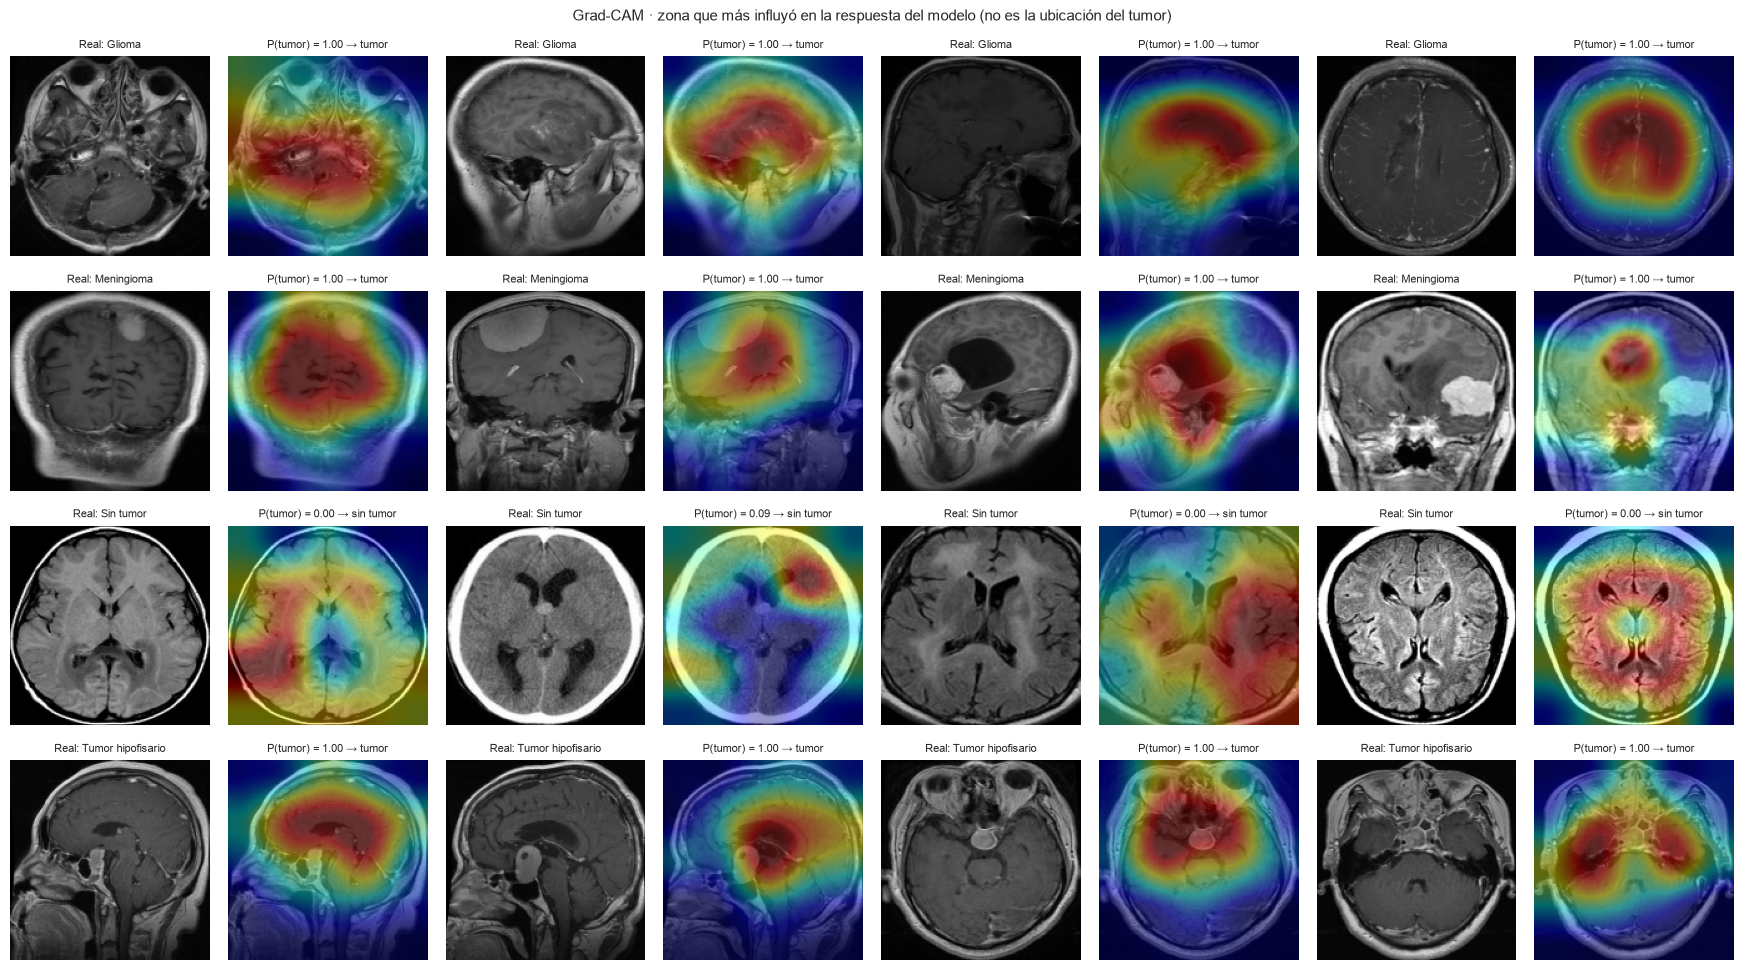

In [44]:
rng = np.random.default_rng(config.SEMILLA)
POR_CLASE = 4
fig, axs = plt.subplots(len(config.CLASES), POR_CLASE * 2, figsize=(2.2 * POR_CLASE * 2, 2.5 * len(config.CLASES)))
for fila, clase in zip(axs, config.CLASES):
    elegidos = rng.choice(np.where(man_pru.clase.to_numpy() == clase)[0], POR_CLASE, replace=False)
    for j, i in enumerate(elegidos):
        mapa = mapa_gradcam(modelo_final, img_pru[i], hacia_tumor=bool(p_pru[i] >= UMBRAL))
        fila[2 * j].imshow(img_pru[i]); fila[2 * j].set_title(f"Real: {config.NOMBRES_ES[clase]}", fontsize=8)
        fila[2 * j + 1].imshow(superponer(img_pru[i], mapa))
        fila[2 * j + 1].set_title(f"P(tumor) = {p_pru[i]:.2f} → {'tumor' if p_pru[i] >= UMBRAL else 'sin tumor'}", fontsize=8)
    for ax in fila:
        ax.axis("off")
fig.suptitle("Grad-CAM · zona que más influyó en la respuesta del modelo (no es la ubicación del tumor)", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "red_gradcam.png", dpi=130); plt.show()

#### Exportación del modelo `v001`
- `modelo.keras`: modelo completo (imagen RGB de 160 × 160 con valores 0 a 255 → probabilidad de tumor y tipo). Se guarda sin optimizador.
- `info.json`: umbral, capa de Grad-CAM, clases, métricas, diagnóstico, versiones y semilla.
- `validacion.npz`: `y` y `prob` son las etiquetas y probabilidades **con las que se eligió el umbral** (para el control deslizante de umbral de la aplicación); `y_val` y `prob_val` son las de la validación apartada del modelo exportado.
- Curvas de entrenamiento en PNG.

In [45]:
entrenar.exportar_limpio(modelo_final, CARPETA_VERSION / "modelo.keras")
rutas_ent = man_ent.ruta.to_numpy().astype(str)
np.savez_compressed(CARPETA_VERSION / "validacion.npz", y=np.asarray(y_umbral).astype(np.int8), prob=np.asarray(p_umbral).astype(np.float64),
                    rutas=(rutas_ent[i_va] if USAR_AJUSTE else rutas_ent), origen=np.array(ORIGEN_UMBRAL),
                    y_val=y_va.astype(np.int8), prob_val=p_va_final.astype(np.float64), rutas_val=rutas_ent[i_va],
                    y_oof=y_ent.astype(np.int8), prob_oof_cabeza=prob_oof.astype(np.float64))
shutil.copy(curva_cabeza, CARPETA_VERSION / "curvas_cabeza.png")
shutil.copy(curva_ajuste, CARPETA_VERSION / "curvas_ajuste_fino.png")
shutil.copy(FIGURAS / "red_gradcam.png", CARPETA_VERSION / "gradcam_ejemplos.png")


def limpio(d):
    return {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in d.items()}


# Comprobación: predecir imagen por imagen (como la app) da la misma sensibilidad que en lote
uno_a_uno = np.array([float(np.asarray(modelo_final(img_ent[i][None].astype(np.float32), training=False)["tumor"]).ravel()[0]) for i in i_va])
m_uno = metricas_binarias(y_va, uno_a_uno, UMBRAL)
print(f"Validación apartada, en lote: FN {m_val['fn']} · FP {m_val['fp']}  |  imagen por imagen: FN {m_uno['fn']} · FP {m_uno['fp']}")
assert (m_uno["fn"], m_uno["fp"]) == (m_val["fn"], m_val["fp"]), "La predicción imagen por imagen no coincide con la de lote."


info = {
    "version": VERSION,
    "nombre": NOMBRE_RED,
    "tipo": "red_keras",
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "archivo_modelo": "modelo.keras",
    "etapa_exportada": ETAPA,
    "descripcion": ("MobileNetV2 con ajuste fino de las últimas capas + cabeza densa" if USAR_AJUSTE
                    else "MobileNetV2 congelada + cabeza densa (el ajuste fino no mejoró la validación)"),
    "entrada": "Imagen RGB uint8 de 160x160 con valores de 0 a 255 (recorte del cerebro + INTER_AREA); la normalización está dentro del modelo",
    "umbral": UMBRAL,
    "sensibilidad_objetivo": OBJETIVO,
    "origen_umbral": ORIGEN_UMBRAL,
    "metricas_umbral": {"n": int(len(y_umbral)), "umbral": UMBRAL, **m_umbral},
    "capa_gradcam": red.NOMBRE_CAPA_GRADCAM,
    "tam": config.TAM,
    "clases": config.CLASES,
    "tipos": config.TIPOS_TUMOR,
    "metricas_cv": {
        "nota": NOTA_RED, "pliegues": config.N_PLIEGUES, "umbral": umbral_cv,
        **{f"{m}_media": float(fila_cv[f"{m}_media"]) for m in METRICAS},
        **{f"{m}_std": float(fila_cv[f"{m}_std"]) for m in METRICAS},
        "por_pliegue": por_pliegue.drop(columns="modelo").to_dict(orient="records"),
    },
    "metricas_validacion": {"n": int(len(i_va)), "umbral": UMBRAL, **m_val},
    "metricas_prueba": {"n": int(len(y_pru)), "umbral": UMBRAL, **m_pru,
                        "sensibilidad_ic95": [s_li, s_ls], "especificidad_ic95": [e_li, e_ls],
                        "exactitud_tipo": exactitud_tipo},
    "mejor_epoca": int(diag_final["mejor_epoca"]),
    "diagnostico": diag_final["etiqueta"],
    "explicacion_diagnostico": diag_final["explicacion"],
    "advertencias_diagnostico": diag_final["advertencias"],
    "diagnostico_etapas": {"cabeza": limpio(diag_cabeza), "ajuste_fino": limpio(diag_ajuste)},
    "comparacion_validacion": {"perdida_val_cabeza": val_cabeza, "perdida_val_ajuste_fino": val_ajuste, "se_uso_ajuste_fino": bool(USAR_AJUSTE)},
    "entrenamiento": {
        "perdida_vigilada": "val_loss (pérdida total de validación = tumor ponderada por clase + 0.5 * tipo)",
        "n_entrenamiento": int(len(i_tr)), "n_validacion": int(len(i_va)), "n_prueba": int(len(y_pru)),
        "pesos_clase": {str(k): float(v) for k, v in red.pesos_clase(y_ent[i_tr]).items()},
        "cabeza": {"epocas_max": EPOCAS_CABEZA, "paciencia": PACIENCIA_CABEZA, "tasa": TASA_CABEZA, "lote": LOTE_CABEZA,
                   "epocas_corridas": len(hist_cabeza["loss"])},
        "ajuste_fino": {"epocas_max": EPOCAS_AJUSTE, "paciencia": PACIENCIA_AJUSTE, "tasa": TASA_AJUSTE, "lote": LOTE_AJUSTE,
                        "capas": CAPAS_AJUSTE, "capas_descongeladas": int(hist_ajuste["capas_descongeladas"]),
                        "epocas_corridas": len(hist_ajuste["loss"]), "veces_entrenado": 1},
        "segundos": {k: round(float(v), 1) for k, v in tiempos.items()},
    },
    "versiones": config.versiones(),
    "semilla": config.SEMILLA,
    "aviso": config.AVISO,
}
(CARPETA_VERSION / "info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("Exportado en", CARPETA_VERSION)
for f in sorted(CARPETA_VERSION.iterdir()):
    print(f"   {f.name}  ({f.stat().st_size / 1e6:.2f} MB)")

Validación apartada, en lote: FN 9 · FP 3  |  imagen por imagen: FN 9 · FP 3
Exportado en C:\proyectos\tumores-cerebrales\app\modelos\v001
   curvas_ajuste_fino.png  (0.08 MB)
   curvas_cabeza.png  (0.07 MB)
   gradcam_ejemplos.png  (2.41 MB)
   info.json  (0.01 MB)
   modelo.keras  (10.95 MB)
   validacion.npz  (0.04 MB)


##### Comprobación: el modelo exportado da lo mismo que el evaluado
Se carga `v001` con `inferencia.cargar_modelo` y se predicen imágenes de prueba **desde el archivo original**, por el mismo camino que usará la aplicación.

In [46]:
modelo_app, info_app = inferencia.cargar_modelo(CARPETA_VERSION)
muestra = rng.choice(len(man_pru), 12, replace=False)
diferencias = []
for i in muestra:
    r = inferencia.predecir(modelo_app, info_app, leer_imagen(config.RAIZ / man_pru.ruta[i]), con_gradcam=(i == muestra[0]))
    diferencias.append(abs(r["probabilidad_tumor"] - p_pru[i]))
    assert r["hay_tumor"] == bool(p_pru[i] >= UMBRAL)
print(f"Diferencia máxima entre la app y la evaluación en {len(muestra)} imágenes: {max(diferencias):.2e}")
assert max(diferencias) < 1e-4
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items() if k not in ("gradcam", "imagen_preparada", "gradcam_superpuesto")})
print(f"\nNotebook terminado en {(time.time() - INICIO) / 60:.1f} min · tiempos (s): { {k: round(v) for k, v in tiempos.items()} }")

Diferencia máxima entre la app y la evaluación en 12 imágenes: 4.62e-07
{'probabilidad_tumor': 0.9998, 'umbral': 0.5205, 'hay_tumor': True, 'tipo_probable': 'meningioma', 'probabilidad_tipo': 0.587, 'probabilidades_tipo': {'glioma': 0.4128262400627136, 'meningioma': 0.5870428681373596, 'pituitary': 0.00013083632802590728}, 'aviso': 'Resultado de apoyo. No sustituye el diagnóstico de un médico especialista.'}

Notebook terminado en 8.5 min · tiempos (s): {'kfold_cabeza_s': 36, 'cabeza_s': 9, 'ajuste_fino_s': 334, 'prediccion_prueba_s': 9}


# 4. IA generativa: asistente de consultas SQL
El administrador pregunta en español; Claude genera la consulta, un validador permite solo lecturas sobre una lista blanca y Claude redacta la respuesta.

In [47]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
from app.backend import asistente, config, db

pd.set_option("display.max_colwidth", 120)
db.crear_esquema()   # crea las vistas de la lista blanca si faltan (no borra nada)
print("Modelo:", config.ANTHROPIC_MODELO)
print("Base:", config.DB_MODO, "| dialecto SQL:", asistente.dialecto())
print("¿Hay clave configurada?:", config.asistente_configurado())   # solo sí/no; la clave nunca se imprime
print("Límite de filas:", config.ASISTENTE_LIMITE_FILAS, "| tiempo máximo de la consulta:", config.ASISTENTE_SEGUNDOS_SQL, "s")
print("Parámetros: max_tokens =", asistente.MAX_TOKENS, "| esfuerzo =", asistente.ESFUERZO,
      "| respaldo del servidor =", asistente.BETA_RESPALDO if config.ASISTENTE_RESPALDO else "desactivado")

Modelo: claude-opus-5-5
Base: fabric | dialecto SQL: tsql
¿Hay clave configurada?: True
Límite de filas: 200 | tiempo máximo de la consulta: 10 s
Parámetros: max_tokens = 4000 | esfuerzo = medium | respaldo del servidor = server-side-fallback-2026-07-01


#### Prompts exactos
##### Prompt del sistema para generar la consulta
Variables que se sustituyen: `{motor}`, `{dialecto}`, `{esquema}` (la lista blanca) y `{limite}`.

In [48]:
print(asistente.prompt_sistema_sql())

Eres el asistente de consultas de un tablero hospitalario académico que apoya la detección de tumores cerebrales en resonancias. Ayudas al Administrador a obtener datos con UNA consulta SQL de solo lectura.

Motor: Microsoft Fabric (SQL Server) (dialecto tsql).

Reglas obligatorias:
1. Escribe UNA sola sentencia SELECT (se permite WITH ... SELECT). Nunca INSERT, UPDATE, DELETE, DROP, ALTER, CREATE, PRAGMA, ATTACH, EXEC ni nada que cambie datos.
2. Usa solo estas vistas y columnas. No existen otras tablas para ti:
- vw_predicciones: Una fila por predicción. origen='uso' son estudios reales subidos por doctores; origen='prueba' son los resultados de los 5 modelos sobre el conjunto de prueba.
    * prediccion_id: número de la predicción
    * origen: 'uso' o 'prueba'
    * creado_en: fecha y hora en que se registró
    * fecha: fecha del estudio
    * anio: año de la fecha del estudio
    * mes: mes (1-12)
    * nombre_mes: nombre del mes en español
    * semana: semana ISO del año
    * 

##### Mensaje del usuario para generar la consulta
Variables: `{hoy}`, `{anio}`, `{semana}` y `{pregunta}` (con los identificadores de paciente ocultos).

In [49]:
print(asistente.PLANTILLA_USUARIO_SQL)
print("--- ejemplo ---")
print(asistente.prompt_usuario_sql("¿Cuántos estudios con posible tumor hubo esta semana por doctor?"))

Fecha de hoy: {hoy} (año {anio}, semana ISO {semana}).

<pregunta>
{pregunta}
</pregunta>
--- ejemplo ---
Fecha de hoy: 2026-11-21 (año 2026, semana ISO 47).

<pregunta>
¿Cuántos estudios con posible tumor hubo esta semana por doctor?
</pregunta>


##### Esquema de la salida estructurada (JSON Schema)

In [50]:
import json
print(json.dumps(asistente.ESQUEMA_SALIDA_SQL, indent=2, ensure_ascii=False))

{
  "type": "object",
  "properties": {
    "puede_responder": {
      "type": "boolean"
    },
    "sql": {
      "type": "string"
    },
    "explicacion": {
      "type": "string"
    },
    "motivo": {
      "type": "string"
    }
  },
  "required": [
    "puede_responder",
    "sql",
    "explicacion",
    "motivo"
  ],
  "additionalProperties": false
}


##### Prompt del sistema y mensaje para redactar la respuesta
Variables: `{pregunta}`, `{sql}`, `{n_filas}`, `{n_mostradas}`, `{columnas}` y `{filas}` (máximo 50, en JSON).

In [51]:
print(asistente.PROMPT_SISTEMA_RESPUESTA)
print("--- plantilla ---")
print(asistente.PLANTILLA_USUARIO_RESPUESTA)

Eres el asistente de consultas de un tablero hospitalario académico de apoyo a la detección de tumores cerebrales. Recibes la pregunta del Administrador, la consulta SQL que se ejecutó y sus resultados. Redacta la respuesta en español de México, formal, sencillo y claro, en 1 a 4 oraciones o una lista corta.

Reglas:
- Usa solo los números que aparecen en los resultados; no inventes ni extrapoles. Si no hay filas, dilo.
- Si los resultados vienen recortados, indícalo.
- No des diagnósticos médicos ni recomendaciones clínicas; es información de apoyo sobre el uso del sistema.
- No menciones detalles técnicos de SQL salvo que ayuden a entender el resultado.
--- plantilla ---
<pregunta>
{pregunta}
</pregunta>

<consulta_sql>
{sql}
</consulta_sql>

<resultados filas_totales="{n_filas}" filas_mostradas="{n_mostradas}">
columnas: {columnas}
{filas}
</resultados>


#### Lista blanca
Solo vistas de lectura. **No** están `usuarios` (hash de contraseñas), `sesiones`, `dim_paciente` (identificador del paciente)
ni las tablas base. `vw_predicciones` trae edad, grupo de edad y sexo ficticios, pero no el identificador.

In [52]:
filas = [(vista, desc, len(cols)) for vista, (desc, cols) in asistente.ESQUEMA.items()]
display(pd.DataFrame(filas, columns=["vista", "descripción", "columnas"]))

,vista,descripción,columnas
0,vw_predicciones,Una fila por predicción. origen='uso' son estudios reales subidos por doctores; origen='prueba' son los resultados d...,30
1,vw_estudios_semana,Estudios de uso por semana ISO (de la fecha del estudio) y doctor.,8
2,vw_metricas_modelo,"Matriz de confusión por versión de modelo y origen, solo con casos confirmados.",12
3,vw_modelos,Catálogo de modelos.,14
4,vw_entrenamientos,Entrenamientos y reentrenamientos de la red.,10
5,vw_metricas_pliegue,Métricas por pliegue de la validación cruzada.,13
6,vw_historial_epocas,Historial por época de cada entrenamiento.,8
7,vw_bitacora,Bitácora de acciones del sistema.,7
8,dim_fecha,Calendario.,7
9,dim_diagnostico,Catálogo de diagnósticos.,4


#### El validador
Casos peligrosos (todos deben quedar bloqueados) y casos válidos (se les fuerza el límite de filas).

In [53]:
casos = {
    "Borrar tabla": "DROP TABLE usuarios",
    "Cambiar rol": "UPDATE usuarios SET rol='administrador'",
    "Leer hashes": "SELECT hash_password FROM usuarios",
    "Identificadores": "SELECT * FROM dim_paciente",
    "Subconsulta fuera de lista": "SELECT nombre FROM vw_modelos WHERE modelo_id IN (SELECT usuario_id FROM usuarios)",
    "CTE fuera de lista": "WITH u AS (SELECT * FROM usuarios) SELECT * FROM u",
    "Dos sentencias": "SELECT * FROM vw_modelos; DROP TABLE usuarios",
    "Comentario que esconde otra": "SELECT * FROM vw_modelos /* ; DROP TABLE usuarios */",
    "PRAGMA": "PRAGMA table_info(usuarios)",
    "ATTACH": "ATTACH DATABASE 'otra.db' AS otra",
    "Función peligrosa": "SELECT load_extension('x')",
    "SELECT ... INTO": "SELECT * INTO copia FROM vw_modelos",
    "Válida (agregada)": "SELECT modelo, COUNT(*) AS n FROM vw_predicciones WHERE origen = 'prueba' GROUP BY modelo",
    "Válida (pide 100000 filas)": "SELECT * FROM vw_bitacora LIMIT 100000",
}
resultado = []
for nombre, sql in casos.items():
    try:
        final = asistente.validar_sql(sql)
        resultado.append((nombre, "aceptada", final))
    except asistente.Bloqueada as e:
        resultado.append((nombre, "BLOQUEADA", str(e)))
tabla = pd.DataFrame(resultado, columns=["caso", "resultado", "SQL final o motivo"])
display(tabla)
assert (tabla["resultado"] == "BLOQUEADA").sum() == len(casos) - 2

,caso,resultado,SQL final o motivo
0,Borrar tabla,BLOQUEADA,La consulta contiene una instrucción no permitida: DROP.
1,Cambiar rol,BLOQUEADA,La consulta contiene una instrucción no permitida: UPDATE.
2,Leer hashes,BLOQUEADA,La tabla o vista 'usuarios' no está en la lista blanca.
3,Identificadores,BLOQUEADA,La tabla o vista 'dim_paciente' no está en la lista blanca.
4,Subconsulta fuera de lista,BLOQUEADA,La tabla o vista 'usuarios' no está en la lista blanca.
5,CTE fuera de lista,BLOQUEADA,La tabla o vista 'usuarios' no está en la lista blanca.
6,Dos sentencias,BLOQUEADA,Solo se permite una sentencia.
7,Comentario que esconde otra,BLOQUEADA,La consulta no puede llevar comentarios.
8,PRAGMA,BLOQUEADA,La consulta contiene una instrucción no permitida: PRAGMA.
9,ATTACH,BLOQUEADA,La consulta contiene una instrucción no permitida: ATTACH.


##### Ejecución de una consulta válida en la base local (solo lectura)

In [54]:
sql = asistente.validar_sql(
    "SELECT modelo, modelo_version, origen, casos, vp, vn, fp, fn, "
    "ROUND(1.0 * vp / NULLIF(vp + fn, 0), 4) AS sensibilidad, ROUND(1.0 * vn / NULLIF(vn + fp, 0), 4) AS especificidad "
    "FROM vw_metricas_modelo ORDER BY origen, modelo")
print(sql)
columnas, filas = asistente.ejecutar(sql)
display(pd.DataFrame(filas, columns=columnas))

SELECT TOP 200 modelo, modelo_version, origen, casos, vp, vn, fp, fn, ROUND(1.0 * vp / NULLIF(vp + fn, 0), 4) AS sensibilidad, ROUND(1.0 * vn / NULLIF(vn + fp, 0), 4) AS especificidad FROM vw_metricas_modelo ORDER BY origen, modelo


,modelo,modelo_version,origen,casos,vp,vn,fp,fn,sensibilidad,especificidad
0,Logística (MobileNetV2),logistica_mobilenet,prueba,720,633,63,10,14,0.9784,0.8630
1,Logística (rasgos básicos),logistica_basica,prueba,720,632,22,51,15,0.9768,0.3014
2,Random Forest (MobileNetV2),random_forest,prueba,720,636,58,15,11,0.9830,0.7945
3,Red Keras (MobileNetV2),v001,prueba,720,626,65,8,21,0.9675,0.8904
4,SVM RBF (MobileNetV2),svm_rbf,prueba,720,633,63,10,14,0.9784,0.8630
5,Red Keras (MobileNetV2),v001,uso,14,9,5,0,0,1.0000,1.0000


#### Llamada real a la API de Claude
Si hay clave en `.env`, se hace **una** pregunta real (dos llamadas: generar y redactar) y se registra en la bitácora.
Si no hay clave, se indica y el notebook sigue sin error.

In [55]:
if config.asistente_configurado():
    r = asistente.responder("¿Cuántos estudios con posible tumor hubo esta semana por doctor?",
                            {"usuario_id": None, "usuario": "notebook_05", "rol": "administrador"}, "notebook",
                            asistente.obtener_cliente())
    print("Estado:", r["estado"])
    print("SQL:", r["sql"])
    if r["columnas"]:
        display(pd.DataFrame(r["filas"], columns=r["columnas"]))
    print("Respuesta:", r["respuesta"])
else:
    print("No hay ANTHROPIC_API_KEY en .env: se omite la llamada real (el resto del notebook no la necesita).")

Estado: ok
SQL: SELECT TOP 200 doctor, SUM(estudios) AS estudios, SUM(con_posible_tumor) AS con_posible_tumor FROM vw_estudios_semana WHERE anio = 2026 AND semana = 47 GROUP BY doctor ORDER BY con_posible_tumor DESC


,doctor,estudios,con_posible_tumor
0,doctor1,14,9


Respuesta: En la semana 47 de 2026 solo aparece un doctor con estudios registrados:

- **doctor1:** 14 estudios, de los cuales 9 se marcaron con posible tumor.

Ningún otro doctor tuvo estudios registrados en esta semana.


#### Reglas de seguridad (resumen)
- Solo `SELECT` sobre la lista blanca, una sentencia, sin comentarios, sin DML/DDL, sin `PRAGMA`/`ATTACH`/`EXEC`, sin funciones
  peligrosas; límite de filas forzado (`LIMIT` en SQLite, `TOP` en T-SQL).
- Conexión de solo lectura (SQLite `mode=ro` + `query_only`; en Fabric `ApplicationIntent=ReadOnly` y un usuario con solo lectura).
- No se envían a la API datos que identifiquen pacientes: la lista blanca no los tiene, los identificadores escritos en la
  pregunta se ocultan y se quitan columnas sensibles antes de enviar filas.
- Toda consulta y todo rechazo queda en la bitácora. La clave nunca se muestra, ni se registra, ni se devuelve.
- Es información de apoyo sobre el uso del sistema; no es un diagnóstico médico.

# 5. Conclusiones
Cifras del conjunto de prueba (720 imágenes: 647 con tumor y 73 sin tumor); la tabla completa está en la sección 3.2 y en `resultados/tabla_comparativa.md`.

- **Limpieza:** de 7,200 imágenes quedaron 3,600; la mitad eran copias (sobre todo en espejo). Sin quitarlas, las métricas salían infladas.
- **Solo Random Forest alcanza la meta** de sensibilidad (0.9830, 11 tumores sin detectar).
- **La red de Keras** logra 0.9675 (21 sin detectar) y la menor cantidad de falsas alarmas (8). En los casos con tumor el SVM fue mejor que la red (McNemar exacta p = 0.016, sin corregir por comparaciones múltiples).
- **La solución más simple** (solo brillo) detecta 0.9768 de los tumores, pero con 51 falsas alarmas de 73: el brillo por sí solo separa buena parte del problema.
- **La red convergió:** mejor época 12; es un mínimo de la pérdida de validación, no una garantía de mínimo global.

**Límites:** datos públicos sin identificador de paciente (puede haber cortes del mismo estudio en entrenamiento y prueba), solo 73 imágenes sin tumor en la prueba, sin búsqueda de hiperparámetros ni selección de rasgos.

**Recomendación:** usar el sistema solo como apoyo; si se prioriza detectar tumores, bajar el umbral desde el panel del administrador o usar Random Forest, y validar con datos clínicos reales antes de cualquier uso.

> Resultado de apoyo. No sustituye el diagnóstico de un médico especialista.